1 - Libraries and configuration

In [6]:

# Section 1 — Libraries and Configuration

# libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
import joblib

from pathlib import Path
from sklearn.preprocessing import StandardScaler
from tensorflow.keras.models import Model, load_model
from tensorflow.keras.layers import (
    Input,
    LSTM,
    RepeatVector,
    TimeDistributed,
    Dense
)
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras.optimizers import Adam


# device data files
CLIENT_FILES = {
    "client1": "Client1wide.csv",
    "client2": "Client2wide.csv",
    "switch": "Switchwide.csv",
    "webserver": "Client3wide.csv",
}


# raspberry pi telemetry metrics (15)
PI_METRICS = [
    "latency_ms",
    "packet_loss_pct",
    "reachability",
    "cpu_pct",
    "disk_usage_pct",
    "uptime_seconds",
    "temperature_c",
    "cpu_voltage_v",
    "power_supply_low_voltage",
    "cpu_speed_capped",
    "cpu_throttled",
    "cpu_clock_mhz",
    "est_power_draw_w",
    "packet_error_rate_pct",
    "throughput_bytes_per_sec",
]


# CPU collection methods
CPU_SOURCE_COLUMNS = [
    "cpu_pct__psutil",
    "cpu_pct__proc_stat",
]


# switch telemetry metrics
SWITCH_METRICS = [
    "cpu_pct",
    "free_memory",
    "uptime",
    "temperature",
    "power_supply_state",
]


# device metric configuration
# additional numerical switch interface metrics will be
# identified automatically during data loading
DEVICE_METRIC_CONFIG = {
    "client1": PI_METRICS.copy(),
    "client2": PI_METRICS.copy(),
    "switch": SWITCH_METRICS.copy(),
    "webserver": PI_METRICS.copy(),
}


# metric name configuration
METRIC_RENAME = {
    "temp_c": "temperature_c",
}


# data split ratios
TRAIN_RATIO = 0.70
VALIDATION_RATIO = 0.15
TEST_RATIO = 0.15


# feature windows
WINDOWS = {
    "1min": "1min",
    "5min": "5min",
    "10min": "10min",
}

# active feature window
ACTIVE_WINDOW = "1min"


# lstm sequence configuration
SEQUENCE_LENGTH = 30
SEQUENCE_STRIDE = 1


# lstm autoencoder configuration
LSTM_UNITS = 64
LATENT_UNITS = 32
LSTM_DROPOUT = 0.10


# training configuration
EPOCHS = 50
BATCH_SIZE = 32
LEARNING_RATE = 0.001
PATIENCE = 7


# anomaly detection configuration
ANOMALY_PERCENTILE = 99
RANDOM_STATE = 42


# data preparation configuration
MISSING_THRESHOLD = 0.50
MAX_FILL_GAP = 2


# model output directory
MODEL_DIR = Path("lstm_models")
MODEL_DIR.mkdir(parents=True, exist_ok=True)


# reproducibility
np.random.seed(RANDOM_STATE)
tf.random.set_seed(RANDOM_STATE)


# configuration validation
assert abs(
    TRAIN_RATIO + VALIDATION_RATIO + TEST_RATIO - 1.0
) < 1e-9

assert ACTIVE_WINDOW in WINDOWS
assert 0 < ANOMALY_PERCENTILE < 100
assert SEQUENCE_LENGTH > 0
assert SEQUENCE_STRIDE > 0
assert len(PI_METRICS) == 15


# configuration check
print("LSTM Autoencoder configuration loaded")
print(f"Devices: {list(CLIENT_FILES.keys())}")
print(f"Raspberry Pi metrics: {len(PI_METRICS)}")
print(f"Feature windows: {list(WINDOWS.keys())}")
print(f"Active window: {ACTIVE_WINDOW}")
print(f"Sequence length: {SEQUENCE_LENGTH}")
print(f"Training epochs: {EPOCHS}")
print(f"Batch size: {BATCH_SIZE}")
print(f"Anomaly percentile: {ANOMALY_PERCENTILE}")
print(f"TensorFlow version: {tf.__version__}")


LSTM Autoencoder configuration loaded
Devices: ['client1', 'client2', 'switch', 'webserver']
Raspberry Pi metrics: 15
Feature windows: ['1min', '5min', '10min']
Active window: 1min
Sequence length: 30
Training epochs: 50
Batch size: 32
Anomaly percentile: 99
TensorFlow version: 2.21.0


2 - Retrieve telemetry

In [7]:

# ============================================================
# Section 2 — Data Loading and Verification
# ============================================================

# metadata and columns excluded from automatic feature selection
METADATA_COLUMNS = {
    "index",
    "Unnamed: 0",
    "_start",
    "_stop",
    "_measurement",
    "_field",
    "device_id",
    "device_name",
    "device_type",
    "collection_method",
    "method",
}

# load device data
def load_client_data(file_path):

    # read csv file
    df = pd.read_csv(file_path, low_memory=False)

    # identify timestamp column
    if "_time" in df.columns:
        time_column = "_time"
    elif "timestamp" in df.columns:
        time_column = "timestamp"
    else:
        raise ValueError(
            f"No timestamp column found in {file_path}"
        )

    # convert timestamps
    df[time_column] = pd.to_datetime(
        df[time_column],
        errors="coerce",
        utc=True
    )

    # count invalid timestamps
    invalid_timestamps = int(
        df[time_column].isna().sum()
    )

    if invalid_timestamps > 0:
        raise ValueError(
            f"{file_path} contains "
            f"{invalid_timestamps} invalid timestamps."
        )

    # sort data chronologically
    df = df.sort_values(
        time_column,
        kind="stable"
    )

    # set timestamp as index
    df = df.set_index(time_column)
    df.index.name = "_time"

    return df, invalid_timestamps


# combine CPU collection methods
def combine_cpu_measurements(df):

    cpu_sources = [
        "cpu_pct__psutil",
        "cpu_pct__proc_stat",
    ]

    # convert CPU measurements to numeric
    for column in cpu_sources + ["cpu_pct"]:
        if column in df.columns:
            df[column] = pd.to_numeric(
                df[column],
                errors="coerce"
            )

    # prefer existing combined CPU measurement
    if "cpu_pct" in df.columns:
        combined_cpu = df["cpu_pct"].copy()
    else:
        combined_cpu = pd.Series(
            np.nan,
            index=df.index
        )

    # fill missing CPU values using available sources
    for column in cpu_sources:
        if column in df.columns:
            combined_cpu = combined_cpu.combine_first(
                df[column]
            )

    if combined_cpu.notna().any():
        df["cpu_pct"] = combined_cpu

    return df


# analyse timestamp intervals
def analyse_time_intervals(df):

    time_differences = (
        df.index.to_series()
        .diff()
        .dt.total_seconds()
        .dropna()
    )

    positive_intervals = time_differences[
        time_differences > 0
    ]

    if positive_intervals.empty:
        return {
            "median_interval_s": np.nan,
            "mean_interval_s": np.nan,
            "max_interval_s": np.nan,
            "gaps_over_60s": 0,
            "gaps_over_300s": 0,
        }

    return {
        "median_interval_s": positive_intervals.median(),
        "mean_interval_s": positive_intervals.mean(),
        "max_interval_s": positive_intervals.max(),
        "gaps_over_60s": int(
            (positive_intervals > 60).sum()
        ),
        "gaps_over_300s": int(
            (positive_intervals > 300).sum()
        ),
    }


# ------------------------------------------------------------
# Load datasets for each device
# ------------------------------------------------------------

CLIENT_DATA = {}
DEVICE_METRICS = {}
DATA_SUMMARY = {}

for device_name, file_path in CLIENT_FILES.items():

    print(f"\n{'=' * 60}")
    print(f"Loading {device_name.upper()}...")
    print(f"{'=' * 60}")

    # check file exists
    if not Path(file_path).exists():
        raise FileNotFoundError(
            f"File not found: {file_path}"
        )

    # load device data
    df, invalid_timestamps = load_client_data(
        file_path
    )

    # standardise metric names
    df = df.rename(columns=METRIC_RENAME)

    # combine CPU measurements
    df = combine_cpu_measurements(df)

    # identify configured metrics
    configured_metrics = DEVICE_METRIC_CONFIG[
        device_name
    ]

    # identify available configured metrics
    available_metrics = [
        metric for metric in configured_metrics
        if metric in df.columns
    ]

    # identify missing configured metrics
    missing_metrics = [
        metric for metric in configured_metrics
        if metric not in df.columns
    ]

    # --------------------------------------------------------
    # Select device-specific features
    # --------------------------------------------------------

    if device_name == "switch":

        # identify additional numerical switch metrics
        additional_metrics = [
            column for column in df.columns

            if column not in available_metrics

            and column not in METADATA_COLUMNS

            and column not in CPU_SOURCE_COLUMNS

            and pd.api.types.is_numeric_dtype(
                df[column]
            )

            and not pd.api.types.is_bool_dtype(
                df[column]
            )
        ]

        device_metrics = (
            available_metrics + additional_metrics
        )

    else:

        # Raspberry Pis use only the 15 configured metrics
        device_metrics = available_metrics

        if missing_metrics:
            raise ValueError(
                f"{device_name}: Missing required metrics: "
                f"{missing_metrics}"
            )

    # convert selected metrics to numeric
    for metric in device_metrics:
        df[metric] = pd.to_numeric(
            df[metric],
            errors="coerce"
        )

    # identify metadata and unused columns
    metadata_columns = [
        column for column in df.columns
        if column not in device_metrics
    ]

    # check duplicate timestamps
    duplicate_timestamps = int(
        df.index.duplicated().sum()
    )

    # check missing measurements
    missing_values = df[
        device_metrics
    ].isna().sum()

    # analyse timestamp continuity
    time_stats = analyse_time_intervals(df)

    # store original device data
    CLIENT_DATA[device_name] = df

    # store selected metric names
    DEVICE_METRICS[device_name] = device_metrics

    # store dataset information
    DATA_SUMMARY[device_name] = {
        "samples": len(df),
        "metrics": len(device_metrics),
        "missing_values": int(
            missing_values.sum()
        ),
        "invalid_timestamps": invalid_timestamps,
        "duplicate_timestamps": duplicate_timestamps,
        "start_time": df.index.min(),
        "end_time": df.index.max(),
        **time_stats,
    }

    # --------------------------------------------------------
    # Display dataset information
    # --------------------------------------------------------

    print(f"Total samples: {len(df):,}")
    print(f"Total columns: {len(df.columns)}")
    print(f"Available metrics: {len(device_metrics)}")

    print(f"Start time: {df.index.min()}")
    print(f"End time: {df.index.max()}")

    print(
        f"Invalid timestamps: "
        f"{invalid_timestamps}"
    )

    print(
        f"Duplicate timestamps: "
        f"{duplicate_timestamps}"
    )

    print("\nAvailable metrics:")
    for metric in device_metrics:
        print(f"  {metric}")

    print("\nMissing configured metrics:")
    if missing_metrics:
        for metric in missing_metrics:
            print(f"  {metric}")
    else:
        print("  None")

    print("\nMetadata / unused columns:")
    if metadata_columns:
        for column in metadata_columns:
            print(f"  {column}")
    else:
        print("  None")

    print("\nMissing values per metric:")
    print(missing_values)

    print("\nTimestamp interval analysis:")
    for key, value in time_stats.items():
        print(f"  {key}: {value}")

    print("\nFirst five samples:")
    display(df.head())


# ------------------------------------------------------------
# Dataset summary
# ------------------------------------------------------------

print("\nData loading complete")
print(f"Devices loaded: {list(CLIENT_DATA.keys())}")

summary_df = pd.DataFrame.from_dict(
    DATA_SUMMARY,
    orient="index"
)

print("\nDataset summary:")
display(summary_df)




Loading CLIENT1...
Total samples: 78,301
Total columns: 17
Available metrics: 15
Start time: 2026-10-12 07:36:37.454292+00:00
End time: 2026-10-24 04:39:01.829934+00:00
Invalid timestamps: 0
Duplicate timestamps: 0

Available metrics:
  latency_ms
  packet_loss_pct
  reachability
  cpu_pct
  disk_usage_pct
  uptime_seconds
  temperature_c
  cpu_voltage_v
  power_supply_low_voltage
  cpu_speed_capped
  cpu_throttled
  cpu_clock_mhz
  est_power_draw_w
  packet_error_rate_pct
  throughput_bytes_per_sec

Missing configured metrics:
  None

Metadata / unused columns:
  cpu_pct__proc_stat
  cpu_pct__psutil

Missing values per metric:
latency_ms                  0
packet_loss_pct             0
reachability                0
cpu_pct                     0
disk_usage_pct              0
uptime_seconds              0
temperature_c               0
cpu_voltage_v               0
power_supply_low_voltage    0
cpu_speed_capped            0
cpu_throttled               0
cpu_clock_mhz               0
est

,packet_error_rate_pct,throughput_bytes_per_sec,cpu_pct__proc_stat,uptime_seconds,est_power_draw_w,latency_ms,packet_loss_pct,reachability,cpu_pct__psutil,disk_usage_pct,cpu_clock_mhz,cpu_speed_capped,cpu_throttled,cpu_voltage_v,power_supply_low_voltage,temperature_c,cpu_pct
_time,,,,,,,,,,,,,,,,,
2026-10-12 07:36:37.454292+00:00,0.0,699.8,0.1,2087839.9,2.7,0.522,0,1,NaN,7.1,600.1,0.0,0.0,0.86,0.0,36.5,0.1
2026-10-12 07:36:50.559981+00:00,0.0,749.3,0.1,2087853.0,2.7,0.529,0,1,NaN,7.1,600.2,0.0,0.0,0.86,0.0,35.5,0.1
2026-10-12 07:37:03.824596+00:00,0.0,1729.7,0.1,2087866.3,2.7,0.445,0,1,NaN,7.1,600.2,0.0,0.0,0.86,0.0,34.5,0.1
2026-10-12 07:37:16.927570+00:00,0.0,427.6,0.1,2087879.4,2.7,0.447,0,1,NaN,7.1,600.1,0.0,0.0,0.86,0.0,36.5,0.1
2026-10-12 07:37:30.015358+00:00,0.0,731.6,0.1,2087892.4,2.7,0.494,0,1,NaN,7.1,600.1,0.0,0.0,0.86,0.0,35.0,0.1



Loading CLIENT2...
Total samples: 78,125
Total columns: 17
Available metrics: 15
Start time: 2026-10-12 08:19:50.996247+00:00
End time: 2026-10-24 04:44:56.705048+00:00
Invalid timestamps: 0
Duplicate timestamps: 0

Available metrics:
  latency_ms
  packet_loss_pct
  reachability
  cpu_pct
  disk_usage_pct
  uptime_seconds
  temperature_c
  cpu_voltage_v
  power_supply_low_voltage
  cpu_speed_capped
  cpu_throttled
  cpu_clock_mhz
  est_power_draw_w
  packet_error_rate_pct
  throughput_bytes_per_sec

Missing configured metrics:
  None

Metadata / unused columns:
  cpu_pct__proc_stat
  cpu_pct__psutil

Missing values per metric:
latency_ms                  0
packet_loss_pct             0
reachability                0
cpu_pct                     0
disk_usage_pct              0
uptime_seconds              0
temperature_c               0
cpu_voltage_v               0
power_supply_low_voltage    0
cpu_speed_capped            0
cpu_throttled               0
cpu_clock_mhz               0
est

,packet_error_rate_pct,throughput_bytes_per_sec,cpu_pct__proc_stat,uptime_seconds,est_power_draw_w,latency_ms,packet_loss_pct,reachability,cpu_pct__psutil,disk_usage_pct,cpu_clock_mhz,cpu_speed_capped,cpu_throttled,cpu_voltage_v,power_supply_low_voltage,temperature_c,cpu_pct
_time,,,,,,,,,,,,,,,,,
2026-10-12 08:19:50.996247+00:00,0.0,704.9,0.1,2183075.1,2.7,0.495,0,1,NaN,14.8,600.1,0.0,0.0,0.85,0.0,42.3,0.1
2026-10-12 08:20:04.099658+00:00,0.0,728.5,0.1,2183088.2,2.7,0.459,0,1,NaN,14.8,600.2,0.0,0.0,0.85,0.0,42.8,0.1
2026-10-12 08:20:17.362098+00:00,0.0,1060.8,0.1,2183101.5,2.7,0.443,0,1,NaN,14.8,600.1,0.0,0.0,0.85,0.0,42.3,0.1
2026-10-12 08:20:30.464892+00:00,0.0,736.8,0.1,2183114.6,2.7,0.520,0,1,NaN,14.8,600.1,0.0,0.0,0.85,0.0,42.8,0.1
2026-10-12 08:20:43.553353+00:00,0.0,391.8,0.1,2183127.6,2.7,0.523,0,1,NaN,14.8,600.2,0.0,0.0,0.85,0.0,42.3,0.1



Loading SWITCH...
Total samples: 95,844
Total columns: 21
Available metrics: 21
Start time: 2026-10-13 02:33:40+00:00
End time: 2026-10-24 04:48:50+00:00
Invalid timestamps: 0
Duplicate timestamps: 0

Available metrics:
  cpu_pct
  free_memory
  uptime
  temperature
  power_supply_state
  interface_1_in_bytes
  interface_1_in_errors
  interface_1_out_bytes
  interface_1_out_errors
  interface_2_in_bytes
  interface_2_in_errors
  interface_2_out_bytes
  interface_2_out_errors
  interface_3_in_bytes
  interface_3_in_errors
  interface_3_out_bytes
  interface_3_out_errors
  interface_4_in_bytes
  interface_4_in_errors
  interface_4_out_bytes
  interface_4_out_errors

Missing configured metrics:
  None

Metadata / unused columns:
  None

Missing values per metric:
cpu_pct                   0
free_memory               0
uptime                    0
temperature               0
power_supply_state        0
interface_1_in_bytes      0
interface_1_in_errors     0
interface_1_out_bytes     0
inte

,cpu_pct,free_memory,interface_1_in_bytes,interface_1_in_errors,interface_1_out_bytes,interface_1_out_errors,interface_2_in_bytes,interface_2_in_errors,interface_2_out_bytes,interface_2_out_errors,...,interface_3_in_errors,interface_3_out_bytes,interface_3_out_errors,interface_4_in_bytes,interface_4_in_errors,interface_4_out_bytes,interface_4_out_errors,power_supply_state,temperature,uptime
_time,,,,,,,,,,,,,,,,,,,,,
2026-10-13 02:33:40+00:00,22,333348064,825043565.0,1.0,285099699.0,0.0,295079763.0,0.0,475460830.0,0.0,...,0.0,479988185.0,0.0,588784127.0,1.0,892956363.0,0.0,1,56,130104972
2026-10-13 02:33:50+00:00,21,333348332,825055374.0,1.0,285102361.0,0.0,295080741.0,0.0,475465625.0,0.0,...,0.0,479997186.0,0.0,588789046.0,1.0,892970023.0,0.0,1,56,130105972
2026-10-13 02:34:00+00:00,22,333348064,825059497.0,1.0,285103977.0,0.0,295081047.0,0.0,475466665.0,0.0,...,0.0,480002107.0,0.0,588792096.0,1.0,892973480.0,0.0,1,56,130106973
2026-10-13 02:34:10+00:00,21,333348064,825072257.0,1.0,285106565.0,0.0,295082063.0,0.0,475471498.0,0.0,...,0.0,480002989.0,0.0,588795987.0,1.0,892985556.0,0.0,1,56,130107973
2026-10-13 02:34:20+00:00,21,333348332,825080561.0,1.0,285108963.0,0.0,295091327.0,0.0,475476618.0,0.0,...,0.0,480007988.0,0.0,588802868.0,1.0,893000111.0,0.0,1,56,130108973



Loading WEBSERVER...
Total samples: 73,216
Total columns: 17
Available metrics: 15
Start time: 2026-10-13 02:17:33.343188+00:00
End time: 2026-10-24 04:53:15.777557+00:00
Invalid timestamps: 0
Duplicate timestamps: 0

Available metrics:
  latency_ms
  packet_loss_pct
  reachability
  cpu_pct
  disk_usage_pct
  uptime_seconds
  temperature_c
  cpu_voltage_v
  power_supply_low_voltage
  cpu_speed_capped
  cpu_throttled
  cpu_clock_mhz
  est_power_draw_w
  packet_error_rate_pct
  throughput_bytes_per_sec

Missing configured metrics:
  None

Metadata / unused columns:
  cpu_pct__proc_stat
  cpu_pct__psutil

Missing values per metric:
latency_ms                  0
packet_loss_pct             0
reachability                0
cpu_pct                     0
disk_usage_pct              0
uptime_seconds              0
temperature_c               0
cpu_voltage_v               0
power_supply_low_voltage    0
cpu_speed_capped            0
cpu_throttled               0
cpu_clock_mhz               0
e

,packet_error_rate_pct,throughput_bytes_per_sec,cpu_pct__proc_stat,uptime_seconds,est_power_draw_w,latency_ms,packet_loss_pct,reachability,cpu_pct__psutil,disk_usage_pct,cpu_clock_mhz,cpu_speed_capped,cpu_throttled,cpu_voltage_v,power_supply_low_voltage,temperature_c,cpu_pct
_time,,,,,,,,,,,,,,,,,
2026-10-13 02:17:33.343188+00:00,2.857,1079.6,0.2,2251109.1,2.71,0.704,0,1,NaN,21.8,600.0,0.0,0.0,1.2,0.0,56.4,0.2
2026-10-13 02:17:46.414298+00:00,0.000,1052.9,0.2,2251122.2,2.71,0.755,0,1,NaN,21.8,600.0,0.0,0.0,1.2,0.0,55.8,0.2
2026-10-13 02:18:37.379134+00:00,1.370,1066.1,0.3,2251173.2,2.71,0.705,0,1,NaN,21.8,600.0,0.0,0.0,1.2,0.0,55.8,0.3
2026-10-13 02:18:50.478142+00:00,0.000,1033.7,0.1,2251186.3,2.70,0.653,0,1,NaN,21.8,600.0,0.0,0.0,1.2,0.0,56.4,0.1
2026-10-13 02:19:03.660791+00:00,2.439,1452.7,0.2,2251199.5,2.71,0.665,0,1,NaN,21.8,600.0,0.0,0.0,1.2,0.0,55.8,0.2



Data loading complete
Devices loaded: ['client1', 'client2', 'switch', 'webserver']

Dataset summary:


,samples,metrics,missing_values,invalid_timestamps,duplicate_timestamps,start_time,end_time,median_interval_s,mean_interval_s,max_interval_s,gaps_over_60s,gaps_over_300s
client1,78301,15,0,0,0,2026-10-12 07:36:37.454292+00:00,2026-10-24 04:39:01.829934+00:00,13.088095,13.105292,58.478871,0,0
client2,78125,15,0,0,0,2026-10-12 08:19:50.996247+00:00,2026-10-24 04:44:56.705048+00:00,13.088115,13.106161,100.690805,1,0
switch,95844,21,0,0,0,2026-10-13 02:33:40+00:00,2026-10-24 04:48:50+00:00,10.000000,10.000835,51.000000,0,0
webserver,73216,15,0,0,0,2026-10-13 02:17:33.343188+00:00,2026-10-24 04:53:15.777557+00:00,13.088522,13.108549,50.964836,0,0


In [8]:

# ============================================================
# Section 2.1 — Switch Interface Rate Calculation
# ============================================================

# load switch data
switch_df = CLIENT_DATA["switch"].copy()

# calculate elapsed time between samples
elapsed_seconds = (
    switch_df.index.to_series()
    .diff()
    .dt.total_seconds()
)

# identify cumulative interface counters
counter_columns = [
    col for col in switch_df.columns
    if col.startswith("interface_")
    and (
        col.endswith("_in_bytes")
        or col.endswith("_out_bytes")
        or col.endswith("_in_errors")
        or col.endswith("_out_errors")
    )
]

# calculate rate for each counter
rate_columns = []

for col in counter_columns:

    # calculate counter difference
    difference = switch_df[col].diff()

    # calculate rate per second
    rate = difference / elapsed_seconds

    # exclude invalid intervals and counter resets
    rate = rate.where(
        (elapsed_seconds > 0) &
        (difference >= 0)
    )

    # name new metric
    if col.endswith("_bytes"):
        new_col = col + "_rate_Bps"
    else:
        new_col = col + "_rate_per_sec"

    # store calculated rate
    switch_df[new_col] = rate
    rate_columns.append(new_col)


# retain original data and calculated metrics
CLIENT_DATA["switch"] = switch_df

# replace cumulative counters with calculated rates
DEVICE_METRICS["switch"] = [
    col for col in DEVICE_METRICS["switch"]
    if col not in counter_columns
] + rate_columns


# display results
print("Switch interface rate calculation complete")
print(f"Original counters: {len(counter_columns)}")
print(f"Calculated rate metrics: {len(rate_columns)}")

print("\nSwitch LSTM input metrics:")
for metric in DEVICE_METRICS["switch"]:
    print(f"  {metric}")

print("\nFirst five samples:")
display(
    switch_df[DEVICE_METRICS["switch"]].head()
)

print("\nMissing values in calculated rates:")
print(
    switch_df[rate_columns].isna().sum()
)


Switch interface rate calculation complete
Original counters: 16
Calculated rate metrics: 16

Switch LSTM input metrics:
  cpu_pct
  free_memory
  uptime
  temperature
  power_supply_state
  interface_1_in_bytes_rate_Bps
  interface_1_in_errors_rate_per_sec
  interface_1_out_bytes_rate_Bps
  interface_1_out_errors_rate_per_sec
  interface_2_in_bytes_rate_Bps
  interface_2_in_errors_rate_per_sec
  interface_2_out_bytes_rate_Bps
  interface_2_out_errors_rate_per_sec
  interface_3_in_bytes_rate_Bps
  interface_3_in_errors_rate_per_sec
  interface_3_out_bytes_rate_Bps
  interface_3_out_errors_rate_per_sec
  interface_4_in_bytes_rate_Bps
  interface_4_in_errors_rate_per_sec
  interface_4_out_bytes_rate_Bps
  interface_4_out_errors_rate_per_sec

First five samples:


,cpu_pct,free_memory,uptime,temperature,power_supply_state,interface_1_in_bytes_rate_Bps,interface_1_in_errors_rate_per_sec,interface_1_out_bytes_rate_Bps,interface_1_out_errors_rate_per_sec,interface_2_in_bytes_rate_Bps,...,interface_2_out_bytes_rate_Bps,interface_2_out_errors_rate_per_sec,interface_3_in_bytes_rate_Bps,interface_3_in_errors_rate_per_sec,interface_3_out_bytes_rate_Bps,interface_3_out_errors_rate_per_sec,interface_4_in_bytes_rate_Bps,interface_4_in_errors_rate_per_sec,interface_4_out_bytes_rate_Bps,interface_4_out_errors_rate_per_sec
_time,,,,,,,,,,,,,,,,,,,,,
2026-10-13 02:33:40+00:00,22,333348064,130104972,56,1,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2026-10-13 02:33:50+00:00,21,333348332,130105972,56,1,1180.9,0.0,266.2,0.0,97.8,...,479.5,0.0,983.9,0.0,900.1,0.0,491.9,0.0,1366.0,0.0
2026-10-13 02:34:00+00:00,22,333348064,130106973,56,1,412.3,0.0,161.6,0.0,30.6,...,104.0,0.0,94.6,0.0,492.1,0.0,305.0,0.0,345.7,0.0
2026-10-13 02:34:10+00:00,21,333348064,130107973,56,1,1276.0,0.0,258.8,0.0,101.6,...,483.3,0.0,30.6,0.0,88.2,0.0,389.1,0.0,1207.6,0.0
2026-10-13 02:34:20+00:00,21,333348332,130108973,56,1,830.4,0.0,239.8,0.0,926.4,...,512.0,0.0,118.2,0.0,499.9,0.0,688.1,0.0,1455.5,0.0



Missing values in calculated rates:
interface_1_in_bytes_rate_Bps          1
interface_1_in_errors_rate_per_sec     1
interface_1_out_bytes_rate_Bps         1
interface_1_out_errors_rate_per_sec    1
interface_2_in_bytes_rate_Bps          1
interface_2_in_errors_rate_per_sec     1
interface_2_out_bytes_rate_Bps         1
interface_2_out_errors_rate_per_sec    1
interface_3_in_bytes_rate_Bps          1
interface_3_in_errors_rate_per_sec     1
interface_3_out_bytes_rate_Bps         1
interface_3_out_errors_rate_per_sec    1
interface_4_in_bytes_rate_Bps          1
interface_4_in_errors_rate_per_sec     1
interface_4_out_bytes_rate_Bps         1
interface_4_out_errors_rate_per_sec    1
dtype: int64


3 - Clean and preprocess

In [9]:

# ============================================================
# Section 3 — Feature Engineering and Resampling
# ============================================================

# binary telemetry metrics
BINARY_METRICS = {
    "reachability",
    "power_supply_low_voltage",
    "cpu_speed_capped",
    "cpu_throttled",
    "power_supply_state",
}

# cumulative metrics that should not be used directly
CUMULATIVE_METRICS = {
    "uptime_seconds",
    "uptime",
}


# ------------------------------------------------------------
# 3.1 Create resampled features
# ------------------------------------------------------------

def create_features(df, metrics, window):

    # select configured metrics
    data = df[metrics].copy()

    # ensure chronological order
    data = data.sort_index()

    # separate continuous and binary metrics
    continuous_metrics = [
        col for col in metrics
        if col not in BINARY_METRICS
        and col not in CUMULATIVE_METRICS
    ]

    binary_metrics = [
        col for col in metrics
        if col in BINARY_METRICS
    ]

    cumulative_metrics = [
        col for col in metrics
        if col in CUMULATIVE_METRICS
    ]

    feature_parts = []

    # continuous metrics: mean, maximum and standard deviation
    if continuous_metrics:

        continuous_features = data[
            continuous_metrics
        ].resample(window).agg(
            ["mean", "max", "std"]
        )

        continuous_features.columns = [
            f"{metric}_{stat}"
            for metric, stat
            in continuous_features.columns
        ]

        feature_parts.append(continuous_features)

    # binary metrics: mean and maximum
    if binary_metrics:

        binary_features = data[
            binary_metrics
        ].resample(window).agg(
            ["mean", "max"]
        )

        binary_features.columns = [
            f"{metric}_{stat}"
            for metric, stat
            in binary_features.columns
        ]

        feature_parts.append(binary_features)

    # cumulative metrics: use first and last values to
    # identify resets rather than train on increasing totals
    if cumulative_metrics:

        for metric in cumulative_metrics:

            values = data[metric]

            previous = values.shift(1)
            reset_events = (
                values.notna()
                & previous.notna()
                & (values < previous)
            ).astype(float)

            reset_feature = reset_events.resample(
                window
            ).max()

            reset_feature.name = f"{metric}_reset"

            feature_parts.append(
                reset_feature.to_frame()
            )

    # combine feature groups
    features = pd.concat(
        feature_parts,
        axis=1
    ).sort_index()

    return features


# ------------------------------------------------------------
# 3.2 Process all devices and feature windows
# ------------------------------------------------------------

FEATURE_DATA = {}
FEATURE_SUMMARY = {}

for device_name, df in CLIENT_DATA.items():

    print(f"\n{'=' * 60}")
    print(f"Processing {device_name.upper()}")
    print(f"{'=' * 60}")

    FEATURE_DATA[device_name] = {}

    selected_metrics = DEVICE_METRICS[
        device_name
    ]

    for window_name, window in WINDOWS.items():

        print(f"\nFeature window: {window_name}")

        # generate features
        features = create_features(
            df,
            selected_metrics,
            window
        )

        # identify missing values
        missing_before = int(
            features.isna().sum().sum()
        )

        # remove empty time windows
        features = features.dropna(
            how="all"
        )

        # interpolate small gaps only for continuous
        # features; avoid interpolation for binary flags
        continuous_feature_columns = [
            col for col in features.columns
            if not any(
                col.startswith(f"{metric}_")
                for metric in BINARY_METRICS
            )
            and not col.endswith("_reset")
        ]

        if continuous_feature_columns:

            features[continuous_feature_columns] = (
                features[continuous_feature_columns]
                .interpolate(
                    method="time",
                    limit=MAX_FILL_GAP,
                    limit_area="inside"
                )
            )

        # fill singleton std values with zero only when
        # an observation exists in that resampling window
        # (std is undefined for a single measurement)
        for col in features.columns:

            if col.endswith("_std"):

                source = col[:-4]

                count = df[source].resample(
                    window
                ).count()

                features[col] = features[col].fillna(
                    count.reindex(
                        features.index
                    ).eq(1).astype(float).mul(0)
                    .where(
                        count.reindex(
                            features.index
                        ).eq(1)
                    )
                )

        # retain missing binary features as missing
        # rather than fabricating healthy device states

        # identify remaining missing values
        missing_after = int(
            features.isna().sum().sum()
        )

        # store features
        FEATURE_DATA[device_name][
            window_name
        ] = features

        FEATURE_SUMMARY[
            (device_name, window_name)
        ] = {
            "samples": len(features),
            "features": len(features.columns),
            "missing_before": missing_before,
            "missing_after": missing_after,
            "start_time": features.index.min(),
            "end_time": features.index.max(),
        }

        # display summary
        print(f"Samples: {len(features):,}")
        print(
            f"Feature columns: "
            f"{len(features.columns)}"
        )
        print(
            f"Missing values before: "
            f"{missing_before:,}"
        )
        print(
            f"Missing values after: "
            f"{missing_after:,}"
        )


# ------------------------------------------------------------
# 3.3 Display feature summary
# ------------------------------------------------------------

feature_summary_df = pd.DataFrame.from_dict(
    FEATURE_SUMMARY,
    orient="index"
)

print("\nFeature engineering complete")
display(feature_summary_df)


# ------------------------------------------------------------
# 3.4 Display selected feature window
# ------------------------------------------------------------

for device_name in FEATURE_DATA:

    print(
        f"\n{device_name.upper()} — "
        f"{ACTIVE_WINDOW}"
    )

    display(
        FEATURE_DATA[
            device_name
        ][ACTIVE_WINDOW].head()
    )



Processing CLIENT1

Feature window: 1min
Samples: 17,104
Feature columns: 39
Missing values before: 20
Missing values after: 0

Feature window: 5min
Samples: 3,421
Feature columns: 39
Missing values before: 0
Missing values after: 0

Feature window: 10min
Samples: 1,711
Feature columns: 39
Missing values before: 0
Missing values after: 0

Processing CLIENT2

Feature window: 1min
Samples: 17,065
Feature columns: 39
Missing values before: 49
Missing values after: 0

Feature window: 5min
Samples: 3,414
Feature columns: 39
Missing values before: 10
Missing values after: 0

Feature window: 10min
Samples: 1,708
Feature columns: 39
Missing values before: 10
Missing values after: 0

Processing SWITCH

Feature window: 1min
Samples: 15,976
Feature columns: 60
Missing values before: 16
Missing values after: 0

Feature window: 5min
Samples: 3,196
Feature columns: 60
Missing values before: 0
Missing values after: 0

Feature window: 10min
Samples: 1,598
Feature columns: 60
Missing values before: 0


samples  features  missing_before  missing_after  \
client1   1min     17104        39              20              0   
          5min      3421        39               0              0   
          10min     1711        39               0              0   
client2   1min     17065        39              49              0   
          5min      3414        39              10              0   
          10min     1708        39              10              0   
switch    1min     15976        60              16              0   
          5min      3196        60               0              0   
          10min     1598        60               0              0   
webserver 1min     15997        39               0              0   
          5min      3200        39               0              0   
          10min     1601        39               0              0   

                               start_time                  end_time  
client1   1min  2026-10-12 07:36:00+00:00 2026-10-24 04:39:00+00:00  
          5min  2026-10-12 07:35:00+00:00 2026-10-24 04:35:00+00:00  
          10min 2026-10-12 07:30:00+00:00 2026-10-24 04:30:00+00:00  
client2   1min  2026-10-12 08:19:00+00:00 2026-10-24 04:44:00+00:00  
          5min  2026-10-12 08:15:00+00:00 2026-10-24 04:40:00+00:00  
          10min 2026-10-12 08:10:00+00:00 2026-10-24 04:40:00+00:00  
switch    1min  2026-10-13 02:33:00+00:00 2026-10-24 04:48:00+00:00  
          5min  2026-10-13 02:30:00+00:00 2026-10-24 04:45:00+00:00  
          10min 2026-10-13 02:30:00+00:00 2026-10-24 04:40:00+00:00  
webserver 1min  2026-10-13 02:17:00+00:00 2026-10-24 04:53:00+00:00  
          5min  2026-10-13 02:15:00+00:00 2026-10-24 04:50:00+00:00  
          10min 2026-10-13 02:10:00+00:00 2026-10-24 04:50:00+00:00


CLIENT1 — 1min


,latency_ms_mean,latency_ms_max,latency_ms_std,packet_loss_pct_mean,packet_loss_pct_max,packet_loss_pct_std,cpu_pct_mean,cpu_pct_max,cpu_pct_std,disk_usage_pct_mean,...,throughput_bytes_per_sec_std,reachability_mean,reachability_max,power_supply_low_voltage_mean,power_supply_low_voltage_max,cpu_speed_capped_mean,cpu_speed_capped_max,cpu_throttled_mean,cpu_throttled_max,uptime_seconds_reset
_time,,,,,,,,,,,,,,,,,,,,,
2026-10-12 07:36:00+00:00,0.52550,0.529,0.004950,0.0,0,0.0,0.100,0.1,0.000000,7.1,...,35.001786,1.0,1,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2026-10-12 07:37:00+00:00,0.47160,0.518,0.032700,0.0,0,0.0,0.100,0.1,0.000000,7.1,...,537.854399,1.0,1,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2026-10-12 07:38:00+00:00,0.47825,0.516,0.029568,0.0,0,0.0,0.075,0.1,0.050000,7.1,...,477.233671,1.0,1,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2026-10-12 07:39:00+00:00,0.49220,0.520,0.026762,0.0,0,0.0,0.100,0.1,0.000000,7.1,...,428.559696,1.0,1,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2026-10-12 07:40:00+00:00,0.48500,0.544,0.044950,0.0,0,0.0,0.120,0.2,0.044721,7.1,...,590.367043,1.0,1,0.0,0.0,0.0,0.0,0.0,0.0,0.0



CLIENT2 — 1min


,latency_ms_mean,latency_ms_max,latency_ms_std,packet_loss_pct_mean,packet_loss_pct_max,packet_loss_pct_std,cpu_pct_mean,cpu_pct_max,cpu_pct_std,disk_usage_pct_mean,...,throughput_bytes_per_sec_std,reachability_mean,reachability_max,power_supply_low_voltage_mean,power_supply_low_voltage_max,cpu_speed_capped_mean,cpu_speed_capped_max,cpu_throttled_mean,cpu_throttled_max,uptime_seconds_reset
_time,,,,,,,,,,,,,,,,,,,,,
2026-10-12 08:19:00+00:00,0.495000,0.495,0.000000,0.0,0.0,0.0,0.100000,0.1,0.000000,14.8,...,0.000000,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2026-10-12 08:20:00+00:00,0.491400,0.523,0.037527,0.0,0.0,0.0,0.100000,0.1,0.000000,14.8,...,385.257600,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2026-10-12 08:21:00+00:00,0.509500,0.530,0.020207,0.0,0.0,0.0,0.100000,0.1,0.000000,14.8,...,457.819597,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2026-10-12 08:22:00+00:00,0.499200,0.534,0.030671,0.0,0.0,0.0,0.100000,0.1,0.000000,14.8,...,398.391104,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2026-10-12 08:23:00+00:00,0.472667,0.535,0.065164,0.0,0.0,0.0,0.133333,0.2,0.057735,14.8,...,362.118687,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0



SWITCH — 1min


,cpu_pct_mean,cpu_pct_max,cpu_pct_std,free_memory_mean,free_memory_max,free_memory_std,temperature_mean,temperature_max,temperature_std,interface_1_in_bytes_rate_Bps_mean,...,interface_4_in_errors_rate_per_sec_std,interface_4_out_bytes_rate_Bps_mean,interface_4_out_bytes_rate_Bps_max,interface_4_out_bytes_rate_Bps_std,interface_4_out_errors_rate_per_sec_mean,interface_4_out_errors_rate_per_sec_max,interface_4_out_errors_rate_per_sec_std,power_supply_state_mean,power_supply_state_max,uptime_reset
_time,,,,,,,,,,,,,,,,,,,,,
2026-10-13 02:33:00+00:00,21.500000,22,0.707107,3.333482e+08,333348332,189.504617,56.0,56,0.0,1180.900000,...,0.0,1366.000000,1366.0,0.000000,0.0,0.0,0.0,1.0,1,0.0
2026-10-13 02:34:00+00:00,21.166667,22,0.408248,3.333482e+08,333348332,138.394605,56.0,56,0.0,767.416667,...,0.0,972.700000,1455.5,495.758945,0.0,0.0,0.0,1.0,1,0.0
2026-10-13 02:35:00+00:00,22.000000,24,1.414214,3.333481e+08,333348332,134.000000,56.0,56,0.0,597.408333,...,0.0,2534.100000,4607.1,1628.723404,0.0,0.0,0.0,1.0,1,0.0
2026-10-13 02:36:00+00:00,21.000000,21,0.000000,3.333482e+08,333348332,138.394605,56.0,56,0.0,826.966667,...,0.0,1436.983333,2711.4,675.974894,0.0,0.0,0.0,1.0,1,0.0
2026-10-13 02:37:00+00:00,21.333333,22,0.516398,3.333482e+08,333348332,138.394605,56.0,56,0.0,702.383333,...,0.0,1617.350000,3617.8,1088.286285,0.0,0.0,0.0,1.0,1,0.0



WEBSERVER — 1min


,latency_ms_mean,latency_ms_max,latency_ms_std,packet_loss_pct_mean,packet_loss_pct_max,packet_loss_pct_std,cpu_pct_mean,cpu_pct_max,cpu_pct_std,disk_usage_pct_mean,...,throughput_bytes_per_sec_std,reachability_mean,reachability_max,power_supply_low_voltage_mean,power_supply_low_voltage_max,cpu_speed_capped_mean,cpu_speed_capped_max,cpu_throttled_mean,cpu_throttled_max,uptime_seconds_reset
_time,,,,,,,,,,,,,,,,,,,,,
2026-10-13 02:17:00+00:00,0.72950,0.755,0.036062,0.0,0,0.0,0.200,0.2,0.000000,21.8,...,18.879751,1.0,1,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2026-10-13 02:18:00+00:00,0.67900,0.705,0.036770,0.0,0,0.0,0.200,0.3,0.141421,21.8,...,22.910260,1.0,1,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2026-10-13 02:19:00+00:00,0.70160,0.736,0.033133,0.0,0,0.0,0.140,0.2,0.054772,21.8,...,429.626498,1.0,1,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2026-10-13 02:20:00+00:00,0.69575,0.729,0.031805,0.0,0,0.0,0.125,0.2,0.050000,21.8,...,589.731216,1.0,1,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2026-10-13 02:21:00+00:00,0.72060,0.736,0.023501,0.0,0,0.0,0.140,0.2,0.054772,21.8,...,438.411979,1.0,1,0.0,0.0,0.0,0.0,0.0,0.0,0.0


4 - Feature engineering

In [10]:

# ============================================================
# Section 4 — Chronological Data Splitting and Feature Scaling
# ============================================================

# store processed data
SPLIT_DATA = {}
SCALERS = {}
FEATURE_COLUMNS = {}
SPLIT_SUMMARY = {}


# process each device
for device_name, windows in FEATURE_DATA.items():

    print(f"\n{'=' * 60}")
    print(f"Processing {device_name.upper()}")
    print(f"{'=' * 60}")

    # select active feature window
    features = windows[ACTIVE_WINDOW].copy()

    # ensure chronological order
    features = features.sort_index()

    # replace infinite values with missing values
    features = features.replace(
        [np.inf, -np.inf],
        np.nan
    )

    # check duplicate timestamps
    if features.index.duplicated().any():
        raise ValueError(
            f"{device_name}: Duplicate timestamps detected."
        )

    # identify dataset size
    total_samples = len(features)

    # calculate chronological split positions
    train_end = int(total_samples * TRAIN_RATIO)

    validation_end = train_end + int(
        total_samples * VALIDATION_RATIO
    )

    # split data chronologically
    train = features.iloc[:train_end].copy()

    validation = features.iloc[
        train_end:validation_end
    ].copy()

    test = features.iloc[
        validation_end:
    ].copy()

    # --------------------------------------------------------
    # Missing data handling
    # --------------------------------------------------------

    # calculate missing-value percentage from training only
    missing_fraction = train.isna().mean()

    # identify features exceeding missing threshold
    removed_features = missing_fraction[
        missing_fraction > MISSING_THRESHOLD
    ].index.tolist()

    # retain selected features
    selected_features = [
        col for col in train.columns
        if col not in removed_features
    ]

    if not selected_features:
        raise ValueError(
            f"{device_name}: No usable features remain."
        )

    train = train[selected_features]
    validation = validation[selected_features]
    test = test[selected_features]

    # calculate replacement values from training data only
    fill_values = train.median().fillna(0.0)

    # fill remaining missing values
    train = train.fillna(fill_values)
    validation = validation.fillna(fill_values)
    test = test.fillna(fill_values)

    # --------------------------------------------------------
    # Feature scaling
    # --------------------------------------------------------

    # initialise scaler
    scaler = StandardScaler()

    # fit scaler using training data only
    X_train = scaler.fit_transform(train)

    # transform validation and test using same scaler
    X_validation = scaler.transform(validation)
    X_test = scaler.transform(test)

    # check for invalid values after scaling
    for name, array in {
        "train": X_train,
        "validation": X_validation,
        "test": X_test,
    }.items():

        if not np.isfinite(array).all():
            raise ValueError(
                f"{device_name}: Invalid values in {name} data."
            )

    # --------------------------------------------------------
    # Store processed datasets
    # --------------------------------------------------------

    SPLIT_DATA[device_name] = {
        "train": X_train,
        "validation": X_validation,
        "test": X_test,
        "train_times": train.index,
        "validation_times": validation.index,
        "test_times": test.index,
    }

    SCALERS[device_name] = scaler
    FEATURE_COLUMNS[device_name] = selected_features

    # save scaler and preprocessing information
    joblib.dump(
        {
            "scaler": scaler,
            "feature_columns": selected_features,
            "fill_values": fill_values,
            "active_window": ACTIVE_WINDOW,
        },
        MODEL_DIR / f"{device_name}_preprocessing.joblib"
    )

    # --------------------------------------------------------
    # Store summary
    # --------------------------------------------------------

    SPLIT_SUMMARY[device_name] = {
        "total_samples": total_samples,
        "training_samples": len(train),
        "validation_samples": len(validation),
        "testing_samples": len(test),
        "selected_features": len(selected_features),
        "removed_features": len(removed_features),
        "train_start": train.index.min(),
        "train_end": train.index.max(),
        "validation_start": validation.index.min(),
        "validation_end": validation.index.max(),
        "test_start": test.index.min(),
        "test_end": test.index.max(),
    }

    # display results
    print(f"Total samples: {total_samples:,}")

    print(f"Training samples: {len(train):,}")
    print(f"Validation samples: {len(validation):,}")
    print(f"Testing samples: {len(test):,}")

    print(f"Selected features: {len(selected_features)}")
    print(f"Removed features: {len(removed_features)}")

    print("\nTraining period:")
    print(f"  {train.index.min()} to {train.index.max()}")

    print("\nValidation period:")
    print(
        f"  {validation.index.min()} "
        f"to {validation.index.max()}"
    )

    print("\nTesting period:")
    print(f"  {test.index.min()} to {test.index.max()}")

    print("\nScaled data shapes:")
    print(f"  Train: {X_train.shape}")
    print(f"  Validation: {X_validation.shape}")
    print(f"  Test: {X_test.shape}")

    if removed_features:
        print("\nRemoved features:")
        for feature in removed_features:
            print(f"  {feature}")


# ------------------------------------------------------------
# Display dataset summary
# ------------------------------------------------------------

print("\nChronological splitting and scaling complete")

split_summary_df = pd.DataFrame.from_dict(
    SPLIT_SUMMARY,
    orient="index"
)

display(split_summary_df)



Processing CLIENT1
Total samples: 17,104
Training samples: 11,972
Validation samples: 2,565
Testing samples: 2,567
Selected features: 39
Removed features: 0

Training period:
  2026-10-12 07:36:00+00:00 to 2026-10-20 15:07:00+00:00

Validation period:
  2026-10-20 15:08:00+00:00 to 2026-10-22 09:52:00+00:00

Testing period:
  2026-10-22 09:53:00+00:00 to 2026-10-24 04:39:00+00:00

Scaled data shapes:
  Train: (11972, 39)
  Validation: (2565, 39)
  Test: (2567, 39)

Processing CLIENT2
Total samples: 17,065
Training samples: 11,945
Validation samples: 2,559
Testing samples: 2,561
Selected features: 39
Removed features: 0

Training period:
  2026-10-12 08:19:00+00:00 to 2026-10-20 15:24:00+00:00

Validation period:
  2026-10-20 15:25:00+00:00 to 2026-10-22 10:03:00+00:00

Testing period:
  2026-10-22 10:04:00+00:00 to 2026-10-24 04:44:00+00:00

Scaled data shapes:
  Train: (11945, 39)
  Validation: (2559, 39)
  Test: (2561, 39)

Processing SWITCH
Total samples: 15,976
Training samples: 1

,total_samples,training_samples,validation_samples,testing_samples,selected_features,removed_features,train_start,train_end,validation_start,validation_end,test_start,test_end
client1,17104,11972,2565,2567,39,0,2026-10-12 07:36:00+00:00,2026-10-20 15:07:00+00:00,2026-10-20 15:08:00+00:00,2026-10-22 09:52:00+00:00,2026-10-22 09:53:00+00:00,2026-10-24 04:39:00+00:00
client2,17065,11945,2559,2561,39,0,2026-10-12 08:19:00+00:00,2026-10-20 15:24:00+00:00,2026-10-20 15:25:00+00:00,2026-10-22 10:03:00+00:00,2026-10-22 10:04:00+00:00,2026-10-24 04:44:00+00:00
switch,15976,11183,2396,2397,60,0,2026-10-13 02:33:00+00:00,2026-10-20 20:55:00+00:00,2026-10-20 20:56:00+00:00,2026-10-22 12:51:00+00:00,2026-10-22 12:52:00+00:00,2026-10-24 04:48:00+00:00
webserver,15997,11197,2399,2401,39,0,2026-10-13 02:17:00+00:00,2026-10-20 20:53:00+00:00,2026-10-20 20:54:00+00:00,2026-10-22 12:52:00+00:00,2026-10-22 12:53:00+00:00,2026-10-24 04:53:00+00:00


5 - Create LSTM sequences

In [11]:

# ============================================================
# Section 5 — Create LSTM Sequences
# ============================================================

# create sliding window sequences
def create_sequences(values, timestamps, sequence_length, stride):

    sequences = []
    sequence_times = []

    # expected timestamp interval
    expected_interval = pd.Timedelta(
        WINDOWS[ACTIVE_WINDOW]
    )

    # convert data to float32
    values = np.asarray(values, dtype=np.float32)

    # ensure timestamps are datetime index
    timestamps = pd.DatetimeIndex(timestamps)

    # identify consecutive timestamp intervals
    intervals = timestamps[1:] - timestamps[:-1]

    # identify timestamp gaps
    valid_intervals = (
        intervals == expected_interval
    )

    # create sliding windows
    for start in range(
        0,
        len(values) - sequence_length + 1,
        stride
    ):

        end = start + sequence_length

        # reject sequences crossing timestamp gaps
        if not valid_intervals[start:end - 1].all():
            continue

        # extract sequence
        sequence = values[start:end]

        # reject invalid values
        if not np.isfinite(sequence).all():
            continue

        sequences.append(sequence)

        # sequence ending timestamp
        sequence_times.append(
            timestamps[end - 1]
        )

    # handle insufficient data
    if not sequences:

        return (
            np.empty(
                (
                    0,
                    sequence_length,
                    values.shape[1]
                ),
                dtype=np.float32
            ),
            pd.DatetimeIndex([])
        )

    return (
        np.stack(sequences),
        pd.DatetimeIndex(sequence_times)
    )


# ------------------------------------------------------------
# Generate sequences for each device
# ------------------------------------------------------------

LSTM_SEQUENCES = {}
SEQUENCE_TIMESTAMPS = {}
SEQUENCE_SUMMARY = {}

for device_name, splits in SPLIT_DATA.items():

    print(f"\n{'=' * 60}")
    print(f"Creating LSTM sequences for {device_name.upper()}")
    print(f"{'=' * 60}")

    LSTM_SEQUENCES[device_name] = {}
    SEQUENCE_TIMESTAMPS[device_name] = {}

    for split_name in [
        "train",
        "validation",
        "test"
    ]:

        # select scaled feature data
        values = splits[split_name]

        # select matching timestamps
        timestamps = splits[f"{split_name}_times"]

        # create sequences
        sequences, sequence_times = create_sequences(
            values,
            timestamps,
            SEQUENCE_LENGTH,
            SEQUENCE_STRIDE
        )

        # store sequences
        LSTM_SEQUENCES[device_name][
            split_name
        ] = sequences

        SEQUENCE_TIMESTAMPS[device_name][
            split_name
        ] = sequence_times

        # display dimensions
        print(
            f"{split_name}: {sequences.shape}"
        )

    # store summary
    SEQUENCE_SUMMARY[device_name] = {
        "features": len(FEATURE_COLUMNS[device_name]),
        "train_sequences": len(
            LSTM_SEQUENCES[device_name]["train"]
        ),
        "validation_sequences": len(
            LSTM_SEQUENCES[device_name]["validation"]
        ),
        "test_sequences": len(
            LSTM_SEQUENCES[device_name]["test"]
        ),
    }


# ------------------------------------------------------------
# Display summary
# ------------------------------------------------------------

print("\nLSTM sequence generation complete")

sequence_summary_df = pd.DataFrame.from_dict(
    SEQUENCE_SUMMARY,
    orient="index"
)

display(sequence_summary_df)


# ------------------------------------------------------------
# Check sequence values
# ------------------------------------------------------------

for device_name, splits in LSTM_SEQUENCES.items():

    print(f"\n{device_name.upper()} sequence checks:")

    for split_name, sequences in splits.items():

        invalid_count = int(
            (~np.isfinite(sequences)).sum()
        )

        print(
            f"{split_name}: "
            f"{invalid_count} invalid values"
        )



Creating LSTM sequences for CLIENT1
train: (11943, 30, 39)
validation: (2536, 30, 39)
test: (2538, 30, 39)

Creating LSTM sequences for CLIENT2
train: (11907, 30, 39)
validation: (2530, 30, 39)
test: (2532, 30, 39)

Creating LSTM sequences for SWITCH
train: (11154, 30, 60)
validation: (2367, 30, 60)
test: (2368, 30, 60)

Creating LSTM sequences for WEBSERVER
train: (11168, 30, 39)
validation: (2370, 30, 39)
test: (2372, 30, 39)

LSTM sequence generation complete


,features,train_sequences,validation_sequences,test_sequences
client1,39,11943,2536,2538
client2,39,11907,2530,2532
switch,60,11154,2367,2368
webserver,39,11168,2370,2372



CLIENT1 sequence checks:
train: 0 invalid values
validation: 0 invalid values
test: 0 invalid values

CLIENT2 sequence checks:
train: 0 invalid values
validation: 0 invalid values
test: 0 invalid values

SWITCH sequence checks:
train: 0 invalid values
validation: 0 invalid values
test: 0 invalid values

WEBSERVER sequence checks:
train: 0 invalid values
validation: 0 invalid values
test: 0 invalid values


6 - Split and scale data


Training LSTM Autoencoder — CLIENT1
Epoch 1/50
374/374 ━━━━━━━━━━━━━━━━━━━━ 6s 11ms/step - loss: 0.5546 - val_loss: 0.5664
Epoch 2/50
374/374 ━━━━━━━━━━━━━━━━━━━━ 4s 10ms/step - loss: 0.5463 - val_loss: 0.5567
Epoch 3/50
374/374 ━━━━━━━━━━━━━━━━━━━━ 4s 10ms/step - loss: 0.5386 - val_loss: 0.5564
Epoch 4/50
374/374 ━━━━━━━━━━━━━━━━━━━━ 4s 10ms/step - loss: 0.5339 - val_loss: 0.5560
Epoch 5/50
374/374 ━━━━━━━━━━━━━━━━━━━━ 4s 10ms/step - loss: 0.5321 - val_loss: 0.5471
Epoch 6/50
374/374 ━━━━━━━━━━━━━━━━━━━━ 4s 12ms/step - loss: 0.5291 - val_loss: 0.5311
Epoch 7/50
374/374 ━━━━━━━━━━━━━━━━━━━━ 5s 13ms/step - loss: 0.5237 - val_loss: 0.5355
Epoch 8/50
374/374 ━━━━━━━━━━━━━━━━━━━━ 5s 13ms/step - loss: 0.5200 - val_loss: 0.5444
Epoch 9/50
374/374 ━━━━━━━━━━━━━━━━━━━━ 5s 13ms/step - loss: 0.5210 - val_loss: 0.5493
Epoch 10/50
374/374 ━━━━━━━━━━━━━━━━━━━━ 5s 12ms/step - loss: 0.5177 - val_loss: 0.5146
Epoch 11/50
374/374 ━━━━━━━━━━━━━━━━━━━━ 5s 12ms/step - loss: 0.5163 - val_loss: 0.5215
Epoc

,training_sequences,validation_sequences,features,epochs_completed,best_training_loss,best_validation_loss
client1,11943,2536,39,50,0.463440,0.440498
client2,11907,2530,39,43,0.407384,0.521333
switch,11154,2367,60,43,0.429062,0.385178
webserver,11168,2370,39,12,0.583685,0.615885


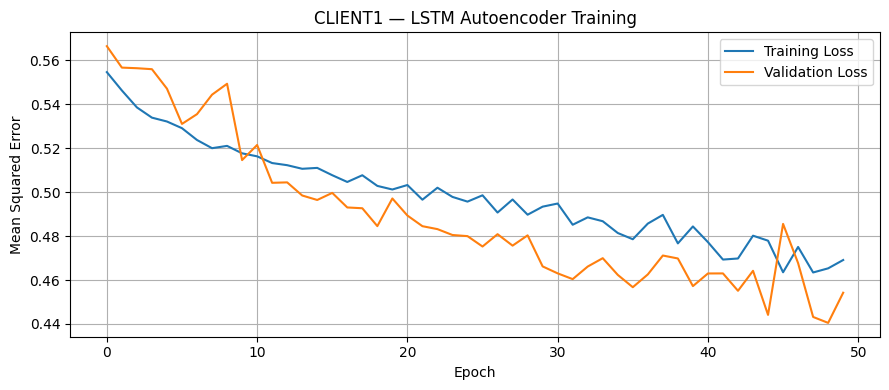

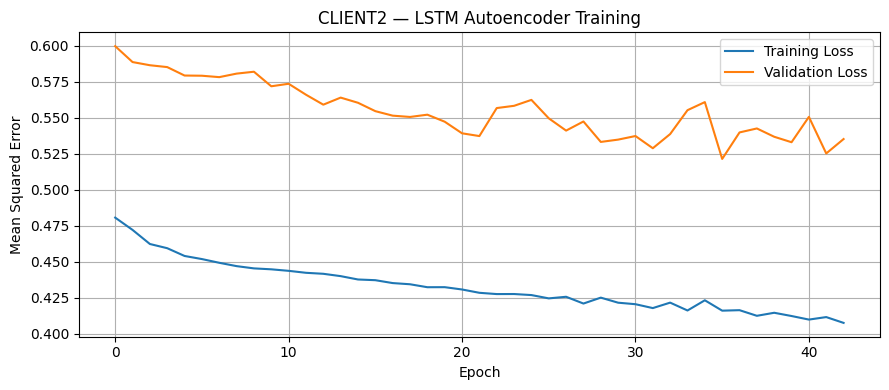

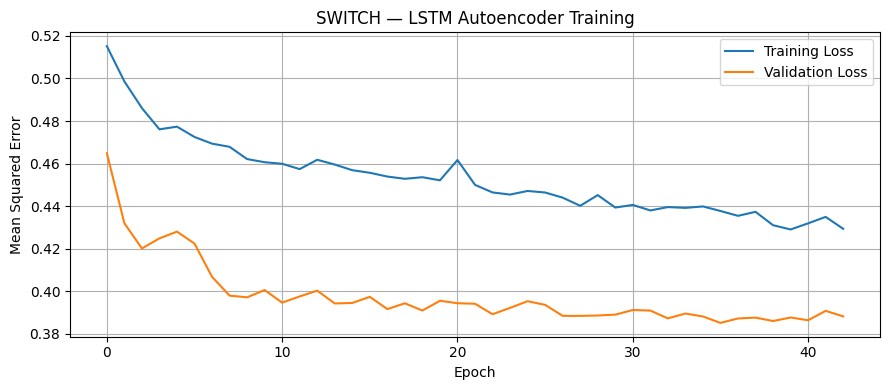

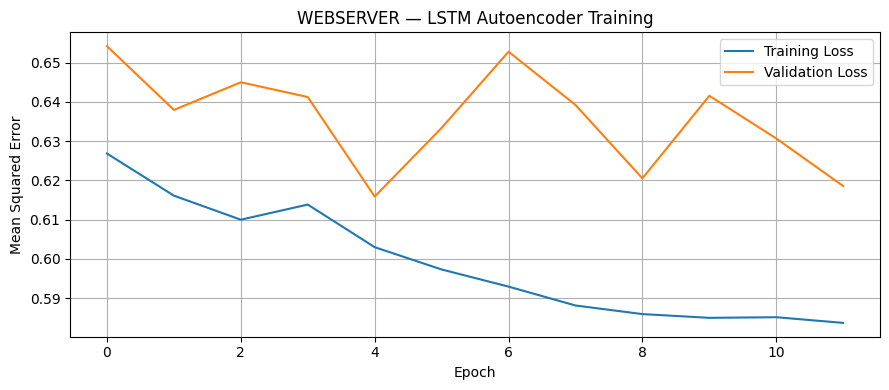

In [12]:

# ============================================================
# Section 6 — LSTM Autoencoder Architecture and Training
# ============================================================

# build LSTM Autoencoder
def build_lstm_autoencoder(sequence_length, n_features):

    # input layer
    inputs = Input(shape=(sequence_length, n_features))

    # encoder
    x = LSTM(
        LSTM_UNITS,
        activation="tanh",
        return_sequences=True,
        dropout=LSTM_DROPOUT
    )(inputs)

    encoded = LSTM(
        LATENT_UNITS,
        activation="tanh",
        return_sequences=False,
        dropout=LSTM_DROPOUT
    )(x)

    # repeat latent representation
    x = RepeatVector(sequence_length)(encoded)

    # decoder
    x = LSTM(
        LATENT_UNITS,
        activation="tanh",
        return_sequences=True,
        dropout=LSTM_DROPOUT
    )(x)

    x = LSTM(
        LSTM_UNITS,
        activation="tanh",
        return_sequences=True,
        dropout=LSTM_DROPOUT
    )(x)

    # reconstruction output
    outputs = TimeDistributed(
        Dense(n_features)
    )(x)

    # construct model
    model = Model(inputs, outputs)

    # compile model
    model.compile(
        optimizer=Adam(learning_rate=LEARNING_RATE),
        loss="mse"
    )

    return model


# ------------------------------------------------------------
# Train one model per device
# ------------------------------------------------------------

LSTM_MODELS = {}
TRAINING_HISTORY = {}
TRAINING_SUMMARY = {}

for device_name, splits in LSTM_SEQUENCES.items():

    print(f"\n{'=' * 60}")
    print(f"Training LSTM Autoencoder — {device_name.upper()}")
    print(f"{'=' * 60}")

    # retrieve training and validation sequences
    X_train = splits["train"]
    X_validation = splits["validation"]

    # validate sequence dimensions
    if len(X_train) == 0 or len(X_validation) == 0:
        raise ValueError(
            f"{device_name}: Insufficient sequences."
        )

    # identify input dimensions
    sequence_length = X_train.shape[1]
    n_features = X_train.shape[2]

    # build model
    model = build_lstm_autoencoder(
        sequence_length,
        n_features
    )

    # early stopping
    early_stopping = EarlyStopping(
        monitor="val_loss",
        patience=PATIENCE,
        restore_best_weights=True
    )

    # train model
    history = model.fit(
        X_train,
        X_train,
        validation_data=(
            X_validation,
            X_validation
        ),
        epochs=EPOCHS,
        batch_size=BATCH_SIZE,
        callbacks=[early_stopping],
        shuffle=False,
        verbose=1
    )

    # save trained model
    model_path = MODEL_DIR / (
        f"{device_name}_lstm_autoencoder.keras"
    )

    model.save(model_path)

    # store results
    LSTM_MODELS[device_name] = model
    TRAINING_HISTORY[device_name] = history.history

    TRAINING_SUMMARY[device_name] = {
        "training_sequences": len(X_train),
        "validation_sequences": len(X_validation),
        "features": n_features,
        "epochs_completed": len(history.history["loss"]),
        "best_training_loss": min(history.history["loss"]),
        "best_validation_loss": min(history.history["val_loss"]),
    }

    print(f"\nSaved model: {model_path}")


# ------------------------------------------------------------
# Display training summary
# ------------------------------------------------------------

training_summary_df = pd.DataFrame.from_dict(
    TRAINING_SUMMARY,
    orient="index"
)

print("\nLSTM Autoencoder training complete")
display(training_summary_df)


# ------------------------------------------------------------
# Plot training history
# ------------------------------------------------------------

for device_name, history in TRAINING_HISTORY.items():

    plt.figure(figsize=(9, 4))

    plt.plot(
        history["loss"],
        label="Training Loss"
    )

    plt.plot(
        history["val_loss"],
        label="Validation Loss"
    )

    plt.title(
        f"{device_name.upper()} — LSTM Autoencoder Training"
    )

    plt.xlabel("Epoch")
    plt.ylabel("Mean Squared Error")
    plt.legend()
    plt.grid(True)
    plt.tight_layout()
    plt.show()


7 - Build LSTM Autoencoder


Anomaly Detection — CLIENT1
Anomaly threshold: 4.134459
train: 11,943 sequences | 120 anomalies | 1.00% anomaly rate
validation: 2,536 sequences | 6 anomalies | 0.24% anomaly rate
test: 2,538 sequences | 0 anomalies | 0.00% anomaly rate

Anomaly Detection — CLIENT2
Anomaly threshold: 3.217792
train: 11,907 sequences | 120 anomalies | 1.01% anomaly rate
validation: 2,530 sequences | 40 anomalies | 1.58% anomaly rate
test: 2,532 sequences | 54 anomalies | 2.13% anomaly rate

Anomaly Detection — SWITCH
Anomaly threshold: 0.927209
train: 11,154 sequences | 112 anomalies | 1.00% anomaly rate
validation: 2,367 sequences | 0 anomalies | 0.00% anomaly rate
test: 2,368 sequences | 158 anomalies | 6.67% anomaly rate

Anomaly Detection — WEBSERVER
Anomaly threshold: 3.573769
train: 11,168 sequences | 112 anomalies | 1.00% anomaly rate
validation: 2,370 sequences | 48 anomalies | 2.03% anomaly rate
test: 2,372 sequences | 7 anomalies | 0.30% anomaly rate

Anomaly detection complete


,threshold,train_anomaly_rate_pct,validation_anomaly_rate_pct,test_anomaly_rate_pct,test_anomalies
client1,4.134459,1.004773,0.236593,0.000000,0
client2,3.217792,1.007811,1.581028,2.132701,54
switch,0.927209,1.004124,0.000000,6.672297,158
webserver,3.573769,1.002865,2.025316,0.295110,7


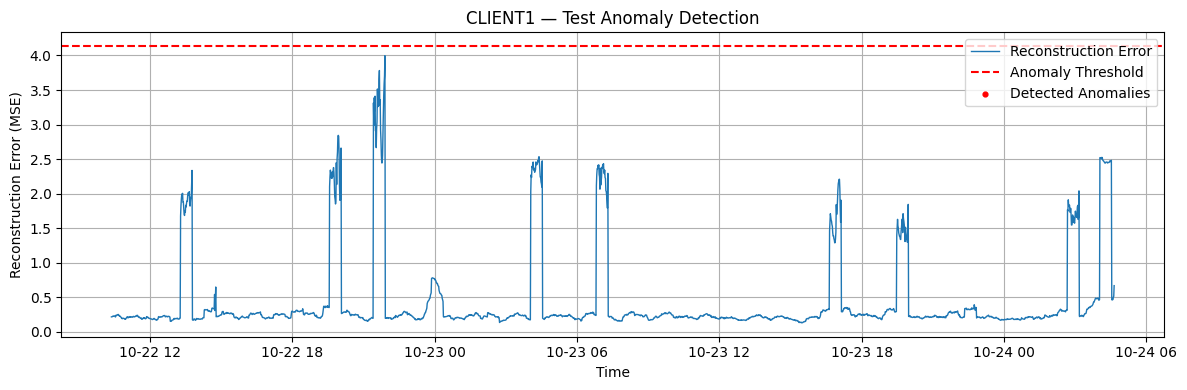

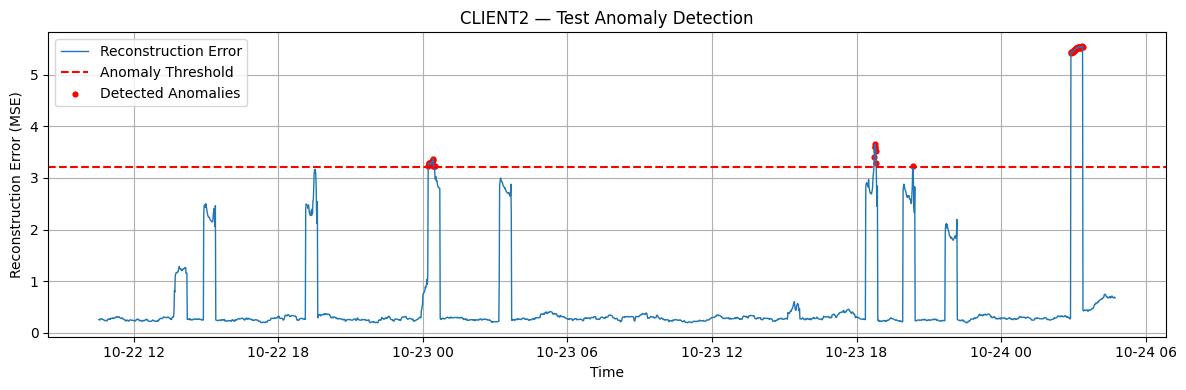

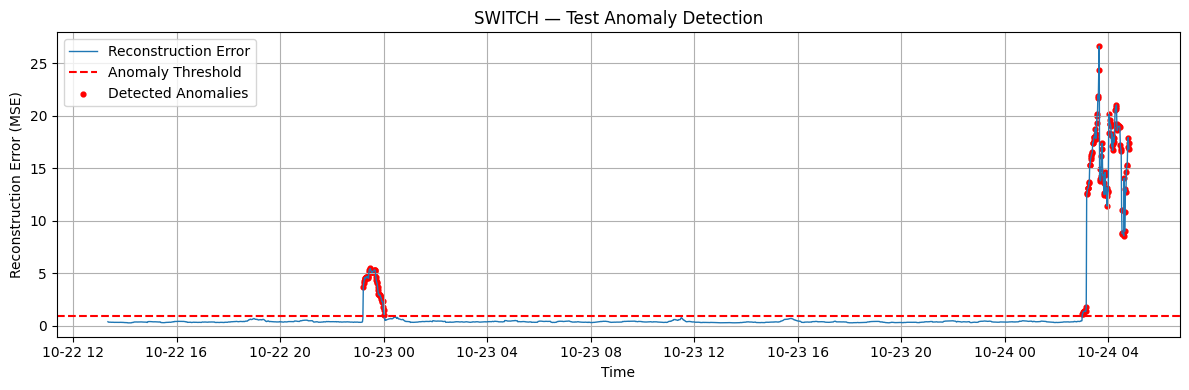

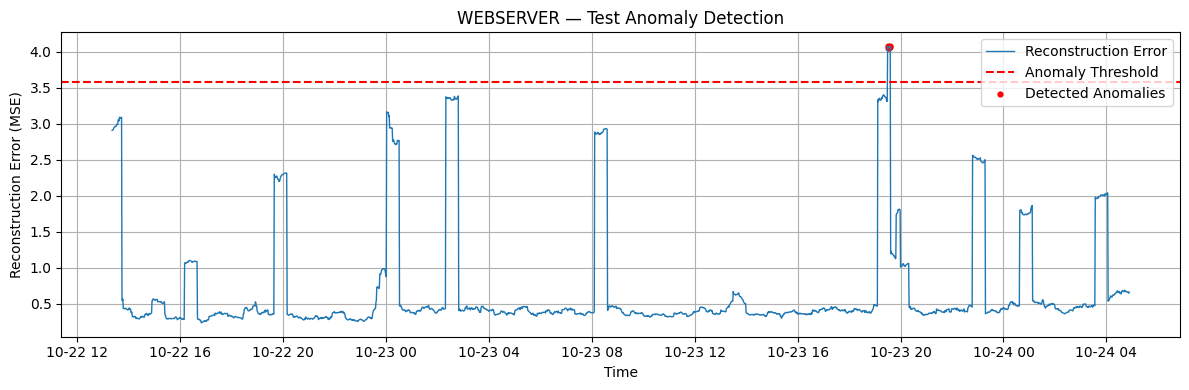


CLIENT1 — Detected anomalies


,reconstruction_error,threshold,is_anomaly,status,most_unusual_feature
_time,,,,,



CLIENT2 — Detected anomalies


,reconstruction_error,threshold,is_anomaly,status,most_unusual_feature
_time,,,,,
2026-10-23 00:13:00+00:00,3.226027,3.217792,True,ANOMALY,latency_ms_max
2026-10-23 00:14:00+00:00,3.265793,3.217792,True,ANOMALY,latency_ms_max
2026-10-23 00:15:00+00:00,3.291052,3.217792,True,ANOMALY,latency_ms_max
2026-10-23 00:16:00+00:00,3.286796,3.217792,True,ANOMALY,latency_ms_max
2026-10-23 00:17:00+00:00,3.290143,3.217792,True,ANOMALY,latency_ms_max
2026-10-23 00:18:00+00:00,3.268940,3.217792,True,ANOMALY,latency_ms_max
2026-10-23 00:19:00+00:00,3.270381,3.217792,True,ANOMALY,latency_ms_max
2026-10-23 00:20:00+00:00,3.273040,3.217792,True,ANOMALY,latency_ms_max
2026-10-23 00:21:00+00:00,3.287232,3.217792,True,ANOMALY,latency_ms_max



SWITCH — Detected anomalies


,reconstruction_error,threshold,is_anomaly,status,most_unusual_feature
_time,,,,,
2026-10-22 23:13:00+00:00,3.718564,0.927209,True,ANOMALY,interface_4_out_bytes_rate_Bps_mean
2026-10-22 23:14:00+00:00,4.069532,0.927209,True,ANOMALY,interface_4_out_bytes_rate_Bps_mean
2026-10-22 23:15:00+00:00,4.268052,0.927209,True,ANOMALY,interface_4_out_bytes_rate_Bps_mean
2026-10-22 23:16:00+00:00,4.593140,0.927209,True,ANOMALY,interface_4_out_bytes_rate_Bps_mean
2026-10-22 23:17:00+00:00,4.468748,0.927209,True,ANOMALY,interface_4_out_bytes_rate_Bps_mean
2026-10-22 23:18:00+00:00,4.529636,0.927209,True,ANOMALY,interface_4_out_bytes_rate_Bps_mean
2026-10-22 23:19:00+00:00,4.604787,0.927209,True,ANOMALY,interface_4_out_bytes_rate_Bps_mean
2026-10-22 23:20:00+00:00,4.668479,0.927209,True,ANOMALY,interface_4_out_bytes_rate_Bps_mean
2026-10-22 23:21:00+00:00,4.568397,0.927209,True,ANOMALY,interface_4_out_bytes_rate_Bps_mean



WEBSERVER — Detected anomalies


,reconstruction_error,threshold,is_anomaly,status,most_unusual_feature
_time,,,,,
2026-10-23 19:30:00+00:00,4.075584,3.573769,True,ANOMALY,cpu_voltage_v_mean
2026-10-23 19:31:00+00:00,4.052202,3.573769,True,ANOMALY,cpu_voltage_v_mean
2026-10-23 19:32:00+00:00,4.055070,3.573769,True,ANOMALY,cpu_voltage_v_mean
2026-10-23 19:33:00+00:00,4.058057,3.573769,True,ANOMALY,cpu_voltage_v_mean
2026-10-23 19:34:00+00:00,4.060930,3.573769,True,ANOMALY,cpu_voltage_v_mean
2026-10-23 19:35:00+00:00,4.067343,3.573769,True,ANOMALY,cpu_voltage_v_mean
2026-10-23 19:36:00+00:00,4.071727,3.573769,True,ANOMALY,cpu_voltage_v_mean


In [13]:


# ============================================================
# Section 7 — Reconstruction Error and Anomaly Detection
# ============================================================

# store anomaly detection results
RECONSTRUCTION_ERRORS = {}
ANOMALY_THRESHOLDS = {}
ANOMALY_RESULTS = {}
ANOMALY_SUMMARY = {}


# calculate reconstruction errors
def calculate_reconstruction_errors(model, sequences):

    # reconstruct input sequences
    reconstructed = model.predict(
        sequences,
        batch_size=BATCH_SIZE,
        verbose=0
    )

    # squared reconstruction error
    squared_error = np.square(
        sequences - reconstructed
    )

    # average across timesteps and features
    sequence_errors = squared_error.mean(
        axis=(1, 2)
    )

    # average across timesteps for each feature
    feature_errors = squared_error.mean(
        axis=1
    )

    return sequence_errors, feature_errors


# ------------------------------------------------------------
# Calculate anomaly thresholds and predictions
# ------------------------------------------------------------

for device_name, model in LSTM_MODELS.items():

    print(f"\n{'=' * 60}")
    print(f"Anomaly Detection — {device_name.upper()}")
    print(f"{'=' * 60}")

    RECONSTRUCTION_ERRORS[device_name] = {}
    ANOMALY_RESULTS[device_name] = {}

    # retrieve training sequences
    X_train = LSTM_SEQUENCES[device_name]["train"]

    # calculate training reconstruction errors
    train_errors, _ = calculate_reconstruction_errors(
        model,
        X_train
    )

    # establish anomaly threshold from training only
    threshold = np.percentile(
        train_errors,
        ANOMALY_PERCENTILE
    )

    ANOMALY_THRESHOLDS[device_name] = threshold

    print(f"Anomaly threshold: {threshold:.6f}")

    # --------------------------------------------------------
    # Evaluate each dataset split
    # --------------------------------------------------------

    for split_name in ["train", "validation", "test"]:

        # retrieve input sequences
        sequences = LSTM_SEQUENCES[
            device_name
        ][split_name]

        # retrieve sequence timestamps
        timestamps = SEQUENCE_TIMESTAMPS[
            device_name
        ][split_name]

        # calculate reconstruction errors
        if split_name == "train":
            sequence_errors = train_errors

            _, feature_errors = calculate_reconstruction_errors(
                model,
                sequences
            )

        else:
            sequence_errors, feature_errors = (
                calculate_reconstruction_errors(
                    model,
                    sequences
                )
            )

        # identify anomalous sequences
        predictions = (
            sequence_errors > threshold
        )

        # identify most unusual feature
        most_unusual_index = np.argmax(
            feature_errors,
            axis=1
        )

        feature_names = np.array(
            FEATURE_COLUMNS[device_name]
        )

        most_unusual_feature = feature_names[
            most_unusual_index
        ]

        # create results dataframe
        results = pd.DataFrame({
            "reconstruction_error": sequence_errors,
            "threshold": threshold,
            "is_anomaly": predictions,
            "status": np.where(
                predictions,
                "ANOMALY",
                "NORMAL"
            ),
            "most_unusual_feature": most_unusual_feature,
        }, index=timestamps)

        results.index.name = "_time"

        # store results
        ANOMALY_RESULTS[
            device_name
        ][split_name] = results

        RECONSTRUCTION_ERRORS[
            device_name
        ][split_name] = sequence_errors

        # display summary
        anomaly_count = int(predictions.sum())

        anomaly_rate = (
            100 * predictions.mean()
        )

        print(
            f"{split_name}: "
            f"{len(sequences):,} sequences | "
            f"{anomaly_count:,} anomalies | "
            f"{anomaly_rate:.2f}% anomaly rate"
        )

    # --------------------------------------------------------
    # Store device summary
    # --------------------------------------------------------

    test_results = ANOMALY_RESULTS[
        device_name
    ]["test"]

    ANOMALY_SUMMARY[device_name] = {
        "threshold": threshold,
        "train_anomaly_rate_pct": (
            ANOMALY_RESULTS[device_name]["train"][
                "is_anomaly"
            ].mean() * 100
        ),
        "validation_anomaly_rate_pct": (
            ANOMALY_RESULTS[device_name]["validation"][
                "is_anomaly"
            ].mean() * 100
        ),
        "test_anomaly_rate_pct": (
            test_results["is_anomaly"].mean() * 100
        ),
        "test_anomalies": int(
            test_results["is_anomaly"].sum()
        ),
    }


# ------------------------------------------------------------
# Display anomaly detection summary
# ------------------------------------------------------------

print("\nAnomaly detection complete")

anomaly_summary_df = pd.DataFrame.from_dict(
    ANOMALY_SUMMARY,
    orient="index"
)

display(anomaly_summary_df)


# ------------------------------------------------------------
# Plot test reconstruction errors
# ------------------------------------------------------------

for device_name in ANOMALY_RESULTS:

    results = ANOMALY_RESULTS[
        device_name
    ]["test"]

    threshold = ANOMALY_THRESHOLDS[
        device_name
    ]

    plt.figure(figsize=(12, 4))

    plt.plot(
        results.index,
        results["reconstruction_error"],
        label="Reconstruction Error",
        linewidth=1
    )

    plt.axhline(
        threshold,
        color="red",
        linestyle="--",
        label="Anomaly Threshold"
    )

    plt.scatter(
        results.index[results["is_anomaly"]],
        results.loc[
            results["is_anomaly"],
            "reconstruction_error"
        ],
        color="red",
        s=12,
        label="Detected Anomalies"
    )

    plt.title(
        f"{device_name.upper()} — Test Anomaly Detection"
    )

    plt.xlabel("Time")
    plt.ylabel("Reconstruction Error (MSE)")
    plt.legend()
    plt.grid(True)
    plt.tight_layout()
    plt.show()


# ------------------------------------------------------------
# Display first detected anomalies
# ------------------------------------------------------------

for device_name in ANOMALY_RESULTS:

    print(f"\n{device_name.upper()} — Detected anomalies")

    anomalies = ANOMALY_RESULTS[
        device_name
    ]["test"]

    anomalies = anomalies[
        anomalies["is_anomaly"]
    ]

    display(anomalies.head(10))


8 - Train the model


Reconstruction error statistics:


mean  median     std     p90     p95        p99  \
device    split                                                           
client1   train       0.4761  0.2380  0.8534  0.5191  2.1713   4.134500   
          validation  0.4405  0.2326  0.6288  1.4403  1.9574   3.072700   
          test        0.4419  0.2280  0.6156  1.3921  2.2114   2.831600   
client2   train       0.4086  0.2245  0.6513  0.4029  1.9944   3.217800   
          validation  0.5213  0.2639  0.8886  1.2309  2.2904   6.597200   
          test        0.5623  0.2808  0.8546  1.2327  2.7141   5.437300   
switch    train       0.4327  0.3650  0.7272  0.4449  0.4854   0.927200   
          validation  0.3852  0.3784  0.0556  0.4556  0.4893   0.566000   
          test        1.1283  0.3748  3.2694  0.5996  4.6392  18.801399   
webserver train       0.6446  0.3903  0.7334  1.2987  2.4836   3.573800   
          validation  0.6159  0.3585  0.7395  1.5979  2.7093   3.863400   
          test        0.6797  0.4033  0.7501  1.8147  2.8654   3.360800   

                        maximum  threshold  
device    split                             
client1   train       10.438000     4.1345  
          validation   4.726900     4.1345  
          test         3.996700     4.1345  
client2   train        7.193200     3.2178  
          validation   6.659500     3.2178  
          test         5.550700     3.2178  
switch    train       15.709800     0.9272  
          validation   0.645200     0.9272  
          test        26.639099     0.9272  
webserver train        7.412700     3.5738  
          validation   4.200600     3.5738  
          test         4.075600     3.5738


CLIENT1 — Highest error sequences


,reconstruction_error,threshold,is_anomaly,status,most_unusual_feature
_time,,,,,
2026-10-22 21:54:00+00:00,3.996748,4.134459,False,NORMAL,cpu_voltage_v_max
2026-10-22 21:40:00+00:00,3.782065,4.134459,False,NORMAL,cpu_voltage_v_max
2026-10-22 21:53:00+00:00,3.702792,4.134459,False,NORMAL,cpu_pct_max
2026-10-22 21:39:00+00:00,3.651604,4.134459,False,NORMAL,cpu_voltage_v_max
2026-10-22 21:52:00+00:00,3.590911,4.134459,False,NORMAL,cpu_pct_max
2026-10-22 21:35:00+00:00,3.514814,4.134459,False,NORMAL,cpu_voltage_v_max
2026-10-22 21:37:00+00:00,3.489852,4.134459,False,NORMAL,cpu_voltage_v_max
2026-10-22 21:51:00+00:00,3.419526,4.134459,False,NORMAL,cpu_pct_max
2026-10-22 21:29:00+00:00,3.410730,4.134459,False,NORMAL,cpu_pct_max



CLIENT2 — Highest error sequences


...

,event_id,start_time,end_time,duration_minutes,detected_sequences,maximum_error,mean_error,main_feature
0,1,2026-10-22 22:44:00+00:00,2026-10-23 00:01:00+00:00,77.0,49,5.468594,4.079574,interface_4_out_bytes_rate_Bps_mean
1,2,2026-10-24 02:31:00+00:00,2026-10-24 04:48:00+00:00,137.0,109,26.639095,14.813625,interface_4_in_bytes_rate_Bps_std



WEBSERVER — Anomaly Events
Detected events: 1


,event_id,start_time,end_time,duration_minutes,detected_sequences,maximum_error,mean_error,main_feature
0,1,2026-10-23 19:01:00+00:00,2026-10-23 19:36:00+00:00,35.0,7,4.075584,4.062988,cpu_voltage_v_mean



Anomaly event summary:


,anomalous_sequences,detected_events,longest_event_minutes,maximum_error
client1,0,0,0.0,3.996748
client2,54,4,58.0,5.550723
switch,158,2,137.0,26.639095
webserver,7,1,35.0,4.075584


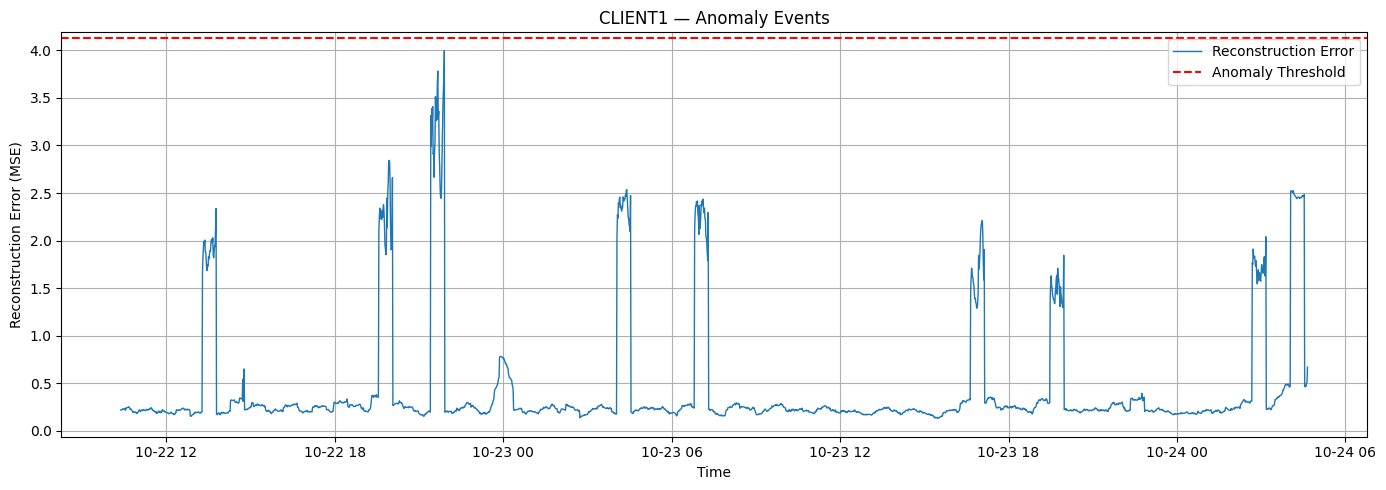

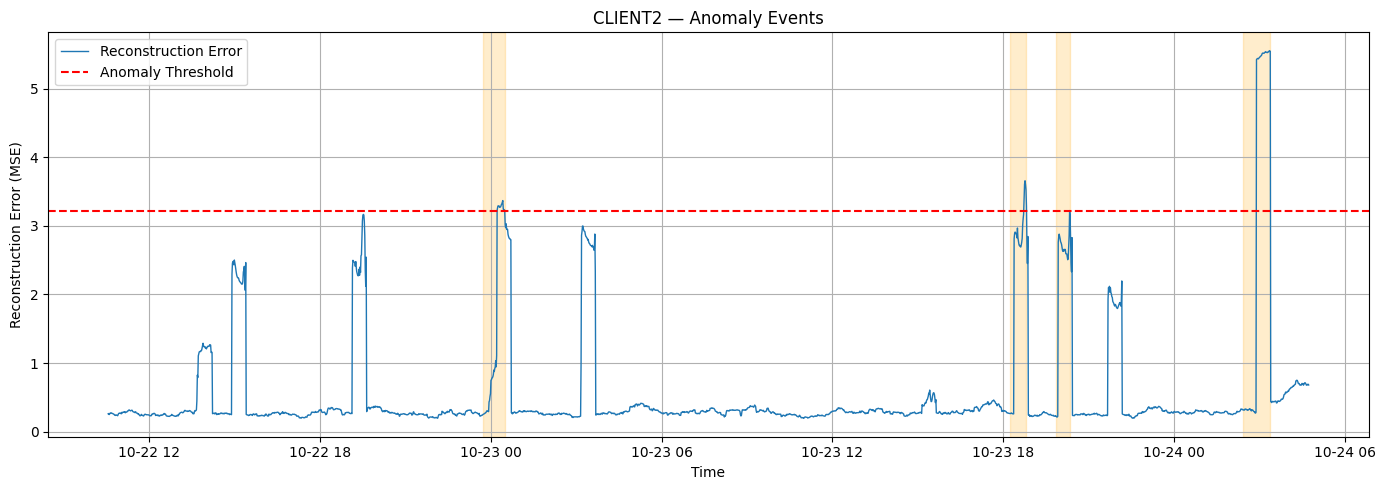

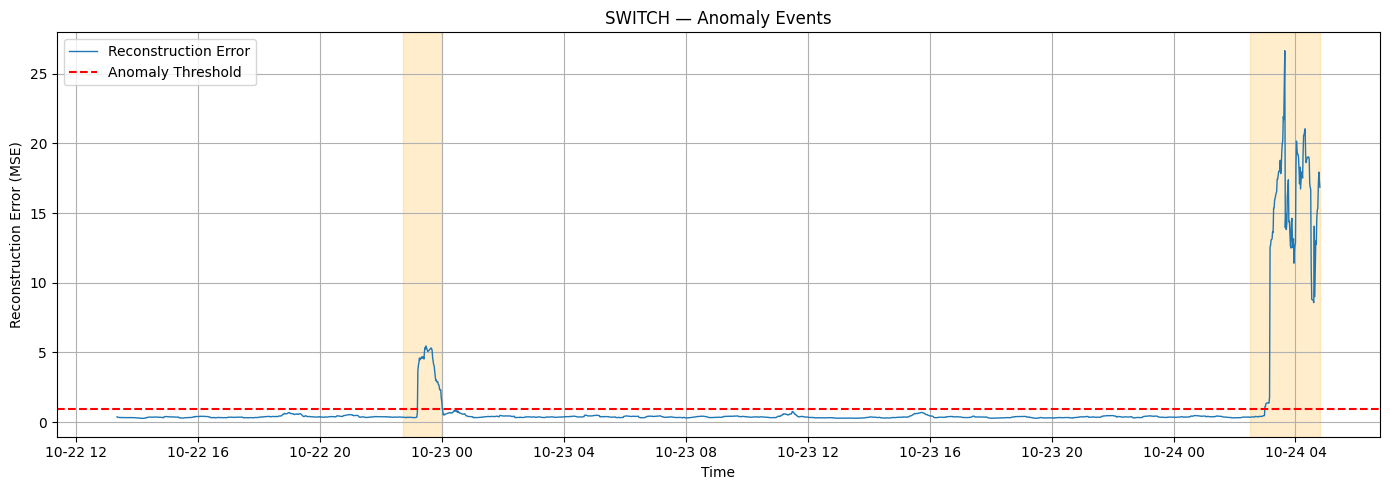

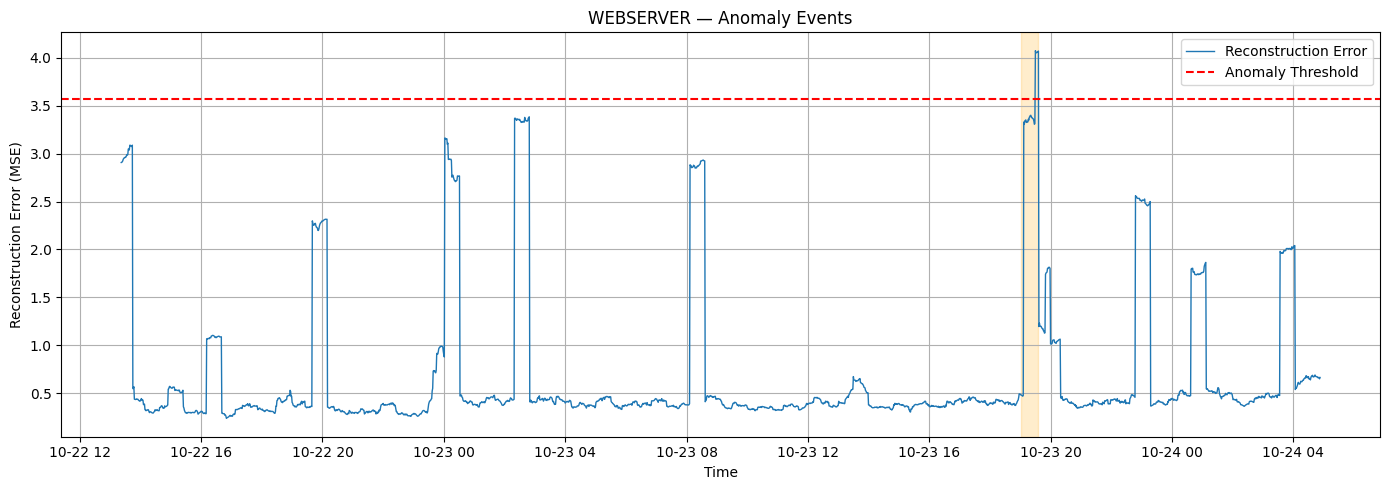

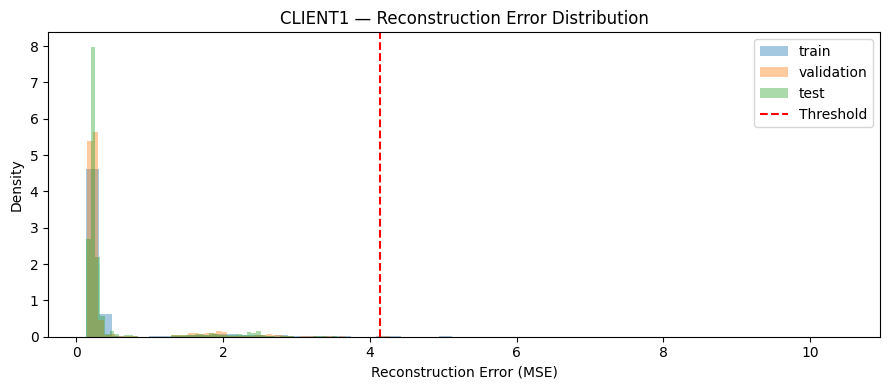

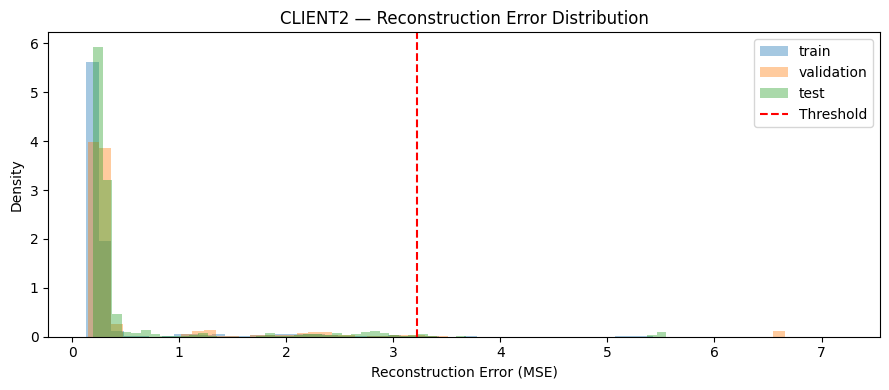

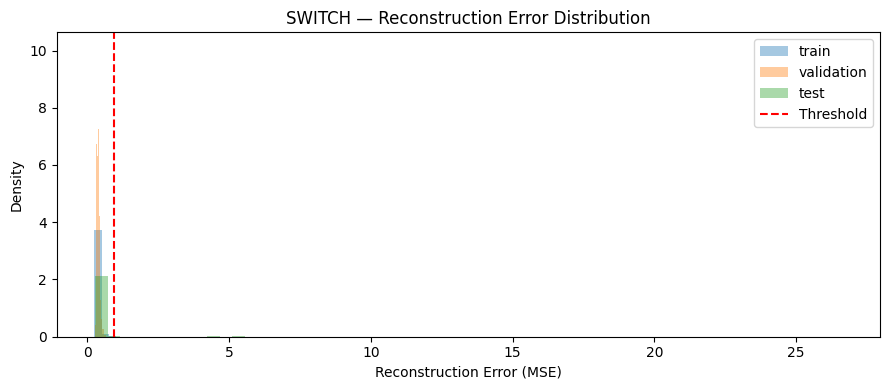

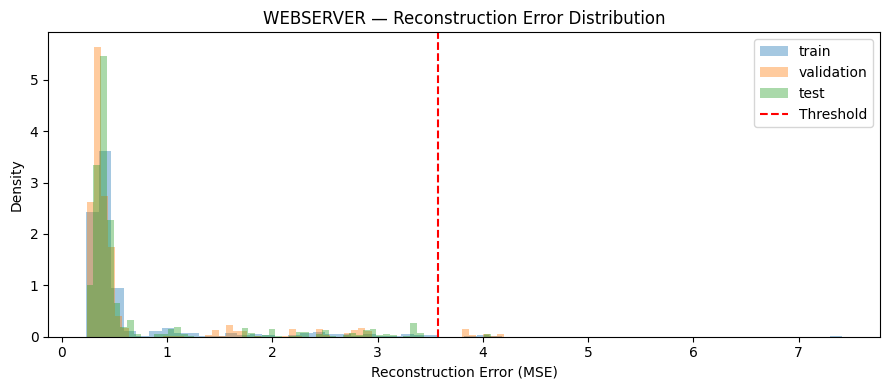


Section 8 complete
Results saved to: lstm_anomaly_results


In [14]:


# ============================================================
# Section 8 — Anomaly Evaluation and Interpretation
# ============================================================

# output directory
RESULTS_DIR = Path("lstm_anomaly_results")
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

# event grouping configuration
# detections within 30 minutes may belong to the same event
EVENT_GAP = pd.Timedelta(
    WINDOWS[ACTIVE_WINDOW]
) * SEQUENCE_LENGTH

# store analysis results
ERROR_STATISTICS = {}
ANOMALY_EVENTS = {}
EVENT_SUMMARY = {}


# ------------------------------------------------------------
# 8.1 Reconstruction error statistics
# ------------------------------------------------------------

for device_name, splits in RECONSTRUCTION_ERRORS.items():

    for split_name, errors in splits.items():

        ERROR_STATISTICS[
            (device_name, split_name)
        ] = {
            "mean": np.mean(errors),
            "median": np.median(errors),
            "std": np.std(errors),
            "p90": np.percentile(errors, 90),
            "p95": np.percentile(errors, 95),
            "p99": np.percentile(errors, 99),
            "maximum": np.max(errors),
            "threshold": ANOMALY_THRESHOLDS[
                device_name
            ],
        }


# display error statistics
error_statistics_df = pd.DataFrame.from_dict(
    ERROR_STATISTICS,
    orient="index"
)

error_statistics_df.index.names = [
    "device",
    "split"
]

print("\nReconstruction error statistics:")
display(error_statistics_df.round(4))

error_statistics_df.to_csv(
    RESULTS_DIR / "reconstruction_error_statistics.csv"
)


# ------------------------------------------------------------
# 8.2 Identify highest-error test sequences
# ------------------------------------------------------------

for device_name in ANOMALY_RESULTS:

    results = ANOMALY_RESULTS[
        device_name
    ]["test"].copy()

    # sort by reconstruction error
    highest_errors = results.sort_values(
        "reconstruction_error",
        ascending=False
    ).head(20)

    print(f"\n{device_name.upper()} — Highest error sequences")
    display(highest_errors)

    highest_errors.to_csv(
        RESULTS_DIR / f"{device_name}_highest_errors.csv"
    )


# ------------------------------------------------------------
# 8.3 Group overlapping detections into events
# ------------------------------------------------------------

def group_anomaly_events(results, event_gap):

    # select anomalous sequences
    anomalies = results[
        results["is_anomaly"]
    ].sort_index().copy()

    if anomalies.empty:
        return pd.DataFrame(columns=[
            "event_id",
            "start_time",
            "end_time",
            "duration_minutes",
            "detected_sequences",
            "maximum_error",
            "mean_error",
            "main_feature",
        ])

    # start a new event when the gap exceeds EVENT_GAP
    new_event = (
        anomalies.index.to_series()
        .diff()
        .gt(event_gap)
    )

    # assign event identifiers
    anomalies["event_id"] = (
        new_event.cumsum() + 1
    ).to_numpy()

    event_rows = []

    for event_id, group in anomalies.groupby("event_id"):

        # ending timestamps of sequences
        first_detection = group.index.min()
        last_detection = group.index.max()

        # approximate affected period
        start_time = first_detection - (
            pd.Timedelta(WINDOWS[ACTIVE_WINDOW])
            * (SEQUENCE_LENGTH - 1)
        )

        end_time = last_detection

        duration = (
            end_time - start_time
        ).total_seconds() / 60

        # most frequently identified unusual feature
        main_feature = (
            group["most_unusual_feature"]
            .mode()
            .iloc[0]
        )

        event_rows.append({
            "event_id": event_id,
            "start_time": start_time,
            "end_time": end_time,
            "duration_minutes": duration,
            "detected_sequences": len(group),
            "maximum_error": group[
                "reconstruction_error"
            ].max(),
            "mean_error": group[
                "reconstruction_error"
            ].mean(),
            "main_feature": main_feature,
        })

    return pd.DataFrame(event_rows)


# ------------------------------------------------------------
# 8.4 Analyse events for each device
# ------------------------------------------------------------

for device_name in ANOMALY_RESULTS:

    test_results = ANOMALY_RESULTS[
        device_name
    ]["test"]

    events = group_anomaly_events(
        test_results,
        EVENT_GAP
    )

    ANOMALY_EVENTS[device_name] = events

    EVENT_SUMMARY[device_name] = {
        "anomalous_sequences": int(
            test_results["is_anomaly"].sum()
        ),
        "detected_events": len(events),
        "longest_event_minutes": (
            events["duration_minutes"].max()
            if not events.empty else 0
        ),
        "maximum_error": (
            test_results["reconstruction_error"].max()
        ),
    }

    print(f"\n{'=' * 60}")
    print(f"{device_name.upper()} — Anomaly Events")
    print(f"{'=' * 60}")

    print(f"Detected events: {len(events)}")
    display(events)

    # export results
    events.to_csv(
        RESULTS_DIR / f"{device_name}_events.csv",
        index=False
    )

    test_results.to_csv(
        RESULTS_DIR / f"{device_name}_test_results.csv"
    )


# ------------------------------------------------------------
# 8.5 Display event summary
# ------------------------------------------------------------

event_summary_df = pd.DataFrame.from_dict(
    EVENT_SUMMARY,
    orient="index"
)

print("\nAnomaly event summary:")
display(event_summary_df)

event_summary_df.to_csv(
    RESULTS_DIR / "anomaly_event_summary.csv"
)


# ------------------------------------------------------------
# 8.6 Visualise reconstruction errors and events
# ------------------------------------------------------------

for device_name in ANOMALY_RESULTS:

    results = ANOMALY_RESULTS[
        device_name
    ]["test"]

    events = ANOMALY_EVENTS[device_name]

    threshold = ANOMALY_THRESHOLDS[
        device_name
    ]

    plt.figure(figsize=(14, 5))

    # plot reconstruction error
    plt.plot(
        results.index,
        results["reconstruction_error"],
        label="Reconstruction Error",
        linewidth=1
    )

    # anomaly threshold
    plt.axhline(
        threshold,
        linestyle="--",
        color="red",
        label="Anomaly Threshold"
    )

    # highlight detected events
    for _, event in events.iterrows():

        plt.axvspan(
            event["start_time"],
            event["end_time"],
            color="orange",
            alpha=0.2
        )

    plt.title(
        f"{device_name.upper()} — Anomaly Events"
    )

    plt.xlabel("Time")
    plt.ylabel("Reconstruction Error (MSE)")
    plt.legend()
    plt.grid(True)
    plt.tight_layout()

    plt.savefig(
        RESULTS_DIR / f"{device_name}_anomaly_events.png",
        dpi=150
    )

    plt.show()


# ------------------------------------------------------------
# 8.7 Compare reconstruction error distributions
# ------------------------------------------------------------

for device_name, splits in RECONSTRUCTION_ERRORS.items():

    plt.figure(figsize=(9, 4))

    for split_name in [
        "train",
        "validation",
        "test"
    ]:

        errors = splits[split_name]

        plt.hist(
            errors,
            bins=60,
            alpha=0.4,
            density=True,
            label=split_name
        )

    plt.axvline(
        ANOMALY_THRESHOLDS[device_name],
        linestyle="--",
        color="red",
        label="Threshold"
    )

    plt.title(
        f"{device_name.upper()} — Reconstruction Error Distribution"
    )

    plt.xlabel("Reconstruction Error (MSE)")
    plt.ylabel("Density")
    plt.legend()
    plt.tight_layout()
    plt.show()


print("\nSection 8 complete")
print(f"Results saved to: {RESULTS_DIR}")


9 - Anomaly detection


CLIENT1 — Training Reference


,mean,median,std,min,max,p95,p99
cpu_pct,0.1040,0.100,0.0651,0.000,3.200,0.100,0.200
cpu_voltage_v,0.8600,0.860,0.0014,0.860,0.926,0.860,0.860
temperature_c,33.0207,33.100,0.9906,28.700,37.000,34.500,35.500
latency_ms,0.5013,0.511,0.0306,0.353,1.242,0.537,0.548



CLIENT2 — Training Reference


,mean,median,std,min,max,p95,p99
cpu_pct,0.0990,0.100,0.0695,0.000,3.40,0.100,0.100
latency_ms,0.5031,0.513,0.0304,0.346,0.74,0.538,0.549
disk_usage_pct,14.9637,15.000,0.0972,14.800,15.10,15.100,15.100
temperature_c,40.0796,39.900,1.1245,35.500,43.80,41.800,42.300



SWITCH — Training Reference


...

,event_id,event_start,event_end,metric,normal_mean,normal_std,normal_p99,event_mean,event_min,event_max,deviation_std,above_normal_p99_pct,main_lstm_feature
0,1,2026-10-23 19:01:00+00:00,2026-10-23 19:36:00+00:00,cpu_voltage_v,1.2000,0.0016,1.2,1.2007,1.2,1.2563,0.4082,1.250,cpu_voltage_v_mean
1,1,2026-10-23 19:01:00+00:00,2026-10-23 19:36:00+00:00,cpu_pct,0.1150,0.1242,0.2,0.1462,0.1,5.8000,0.2516,0.625,cpu_voltage_v_mean
2,1,2026-10-23 19:01:00+00:00,2026-10-23 19:36:00+00:00,temperature_c,54.7933,0.9025,56.9,54.9438,53.7,58.0000,0.1667,0.625,cpu_voltage_v_mean
3,1,2026-10-23 19:01:00+00:00,2026-10-23 19:36:00+00:00,power_supply_low_voltage,0.0000,0.0000,0.0,0.0000,0.0,0.0000,NaN,0.000,cpu_voltage_v_mean
4,1,2026-10-23 19:01:00+00:00,2026-10-23 19:36:00+00:00,cpu_throttled,0.0000,0.0000,0.0,0.0000,0.0,0.0000,NaN,0.000,cpu_voltage_v_mean



CLIENT1 — Highest Reconstruction Errors


,reconstruction_error,threshold,is_anomaly,status,most_unusual_feature
_time,,,,,
2026-10-22 21:54:00+00:00,3.996748,4.134459,False,NORMAL,cpu_voltage_v_max
2026-10-22 21:40:00+00:00,3.782065,4.134459,False,NORMAL,cpu_voltage_v_max
2026-10-22 21:53:00+00:00,3.702792,4.134459,False,NORMAL,cpu_pct_max
2026-10-22 21:39:00+00:00,3.651604,4.134459,False,NORMAL,cpu_voltage_v_max
2026-10-22 21:52:00+00:00,3.590911,4.134459,False,NORMAL,cpu_pct_max
2026-10-22 21:35:00+00:00,3.514814,4.134459,False,NORMAL,cpu_voltage_v_max
2026-10-22 21:37:00+00:00,3.489852,4.134459,False,NORMAL,cpu_voltage_v_max
2026-10-22 21:51:00+00:00,3.419526,4.134459,False,NORMAL,cpu_pct_max
2026-10-22 21:29:00+00:00,3.410730,4.134459,False,NORMAL,cpu_pct_max



Client1 high-error telemetry:


,cpu_pct,cpu_voltage_v,temperature_c,latency_ms
count,270.000000,270.000000,270.000000,270.000000
mean,0.113704,0.860244,33.078148,0.504519
std,0.183312,0.004017,0.561335,0.028440
min,0.000000,0.860000,31.600000,0.425000
25%,0.100000,0.860000,32.600000,0.487000
50%,0.100000,0.860000,33.100000,0.514500
75%,0.100000,0.860000,33.600000,0.525000
max,3.100000,0.926000,35.000000,0.555000


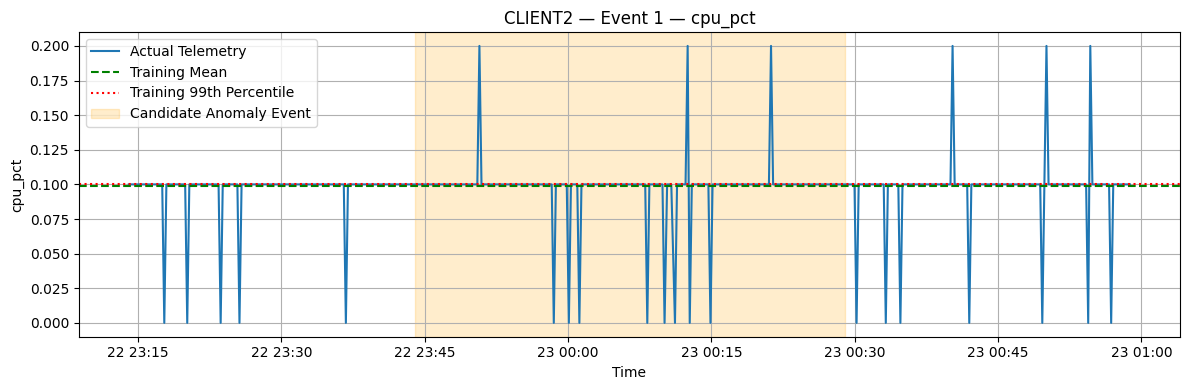

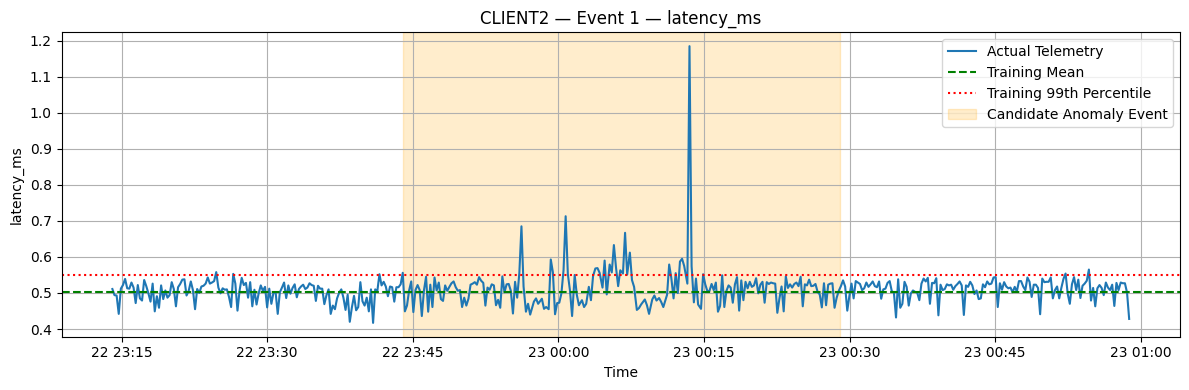

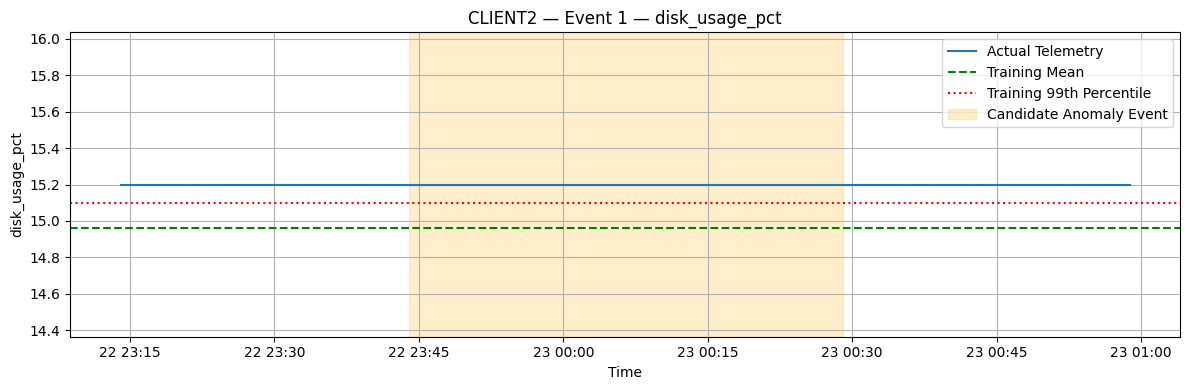

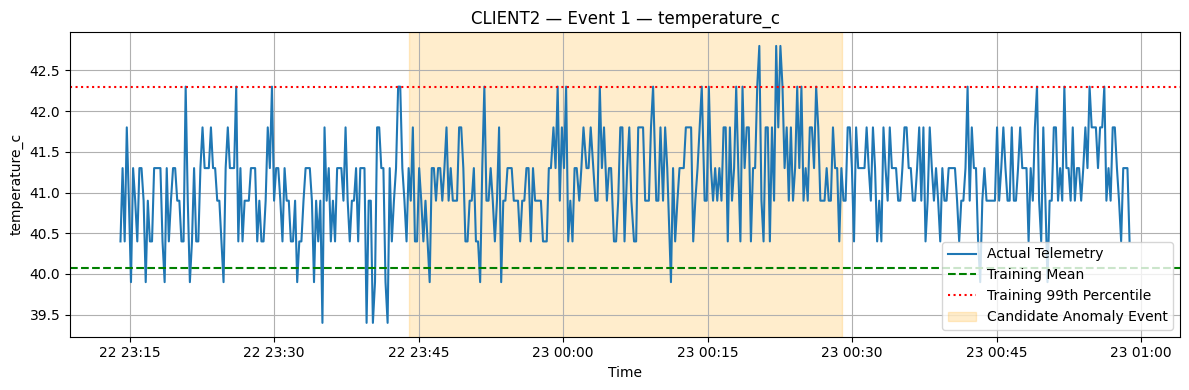

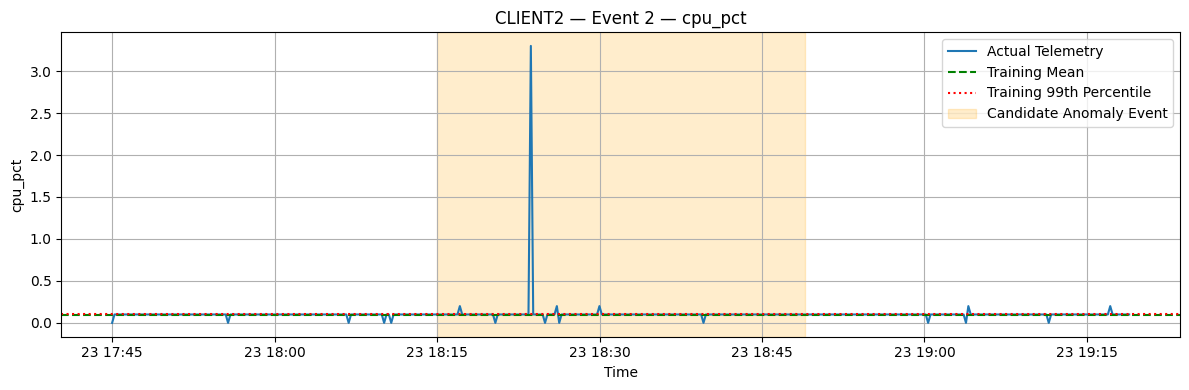

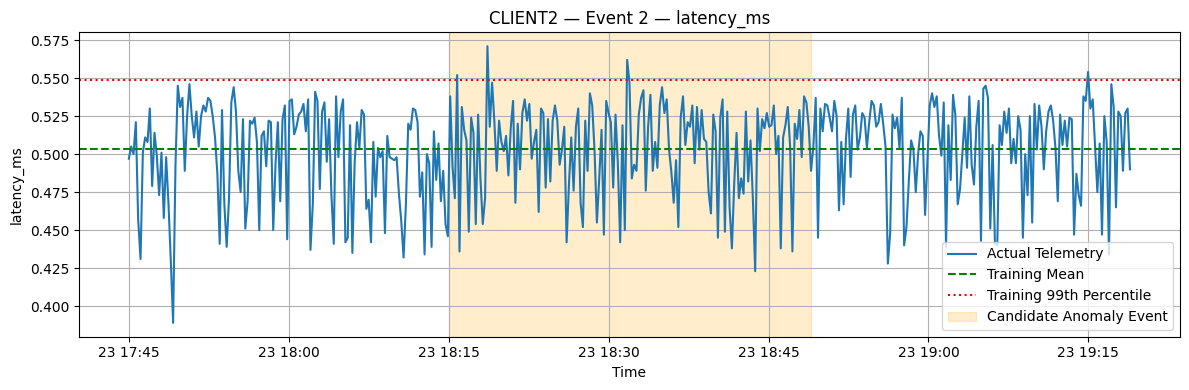

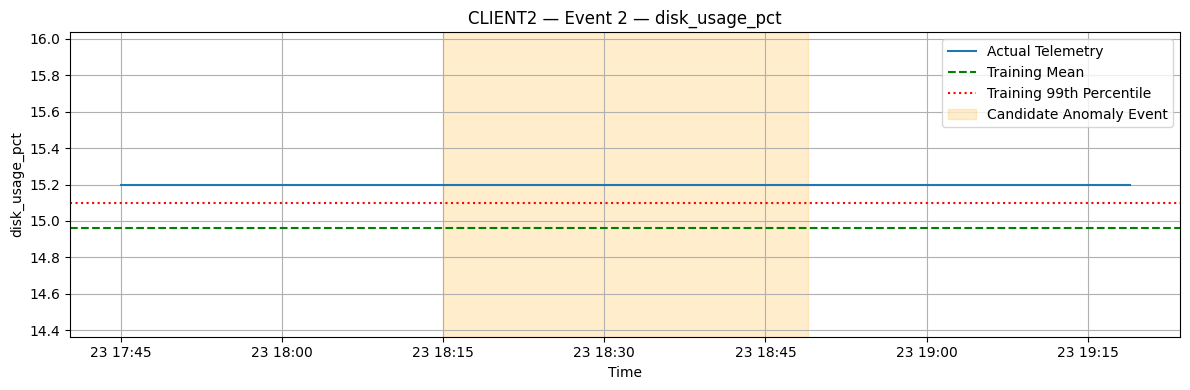

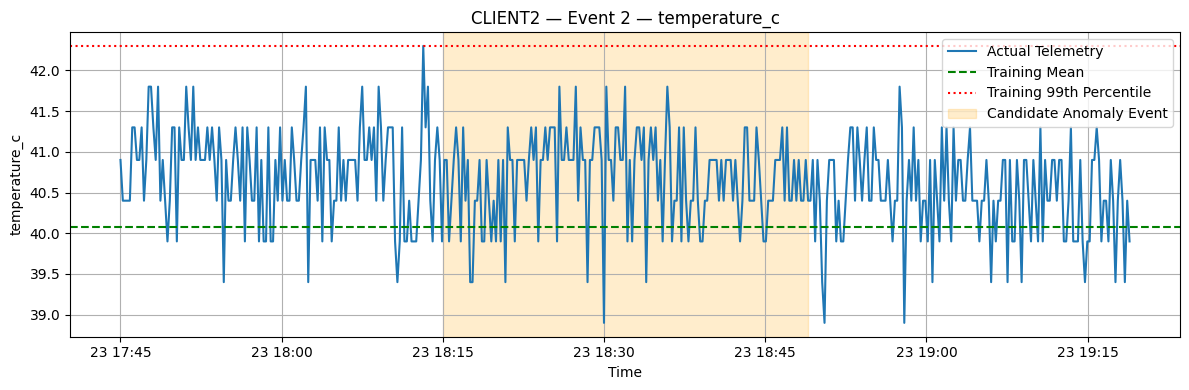

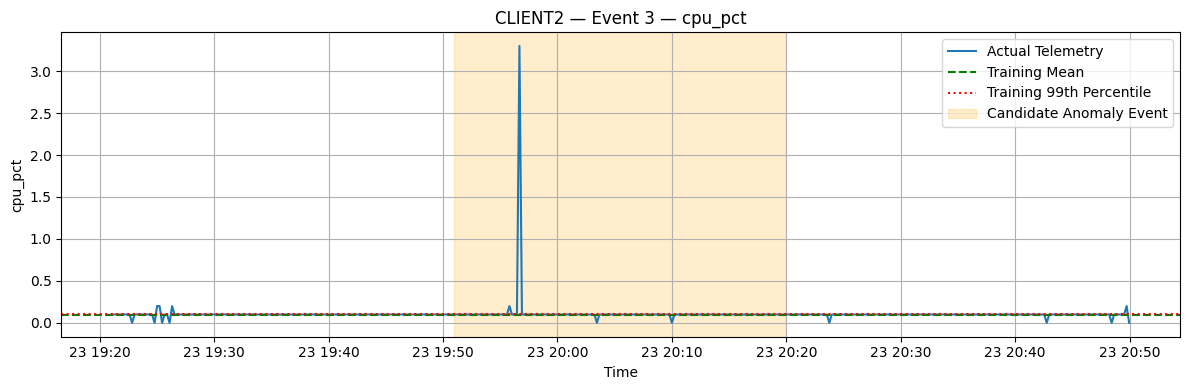

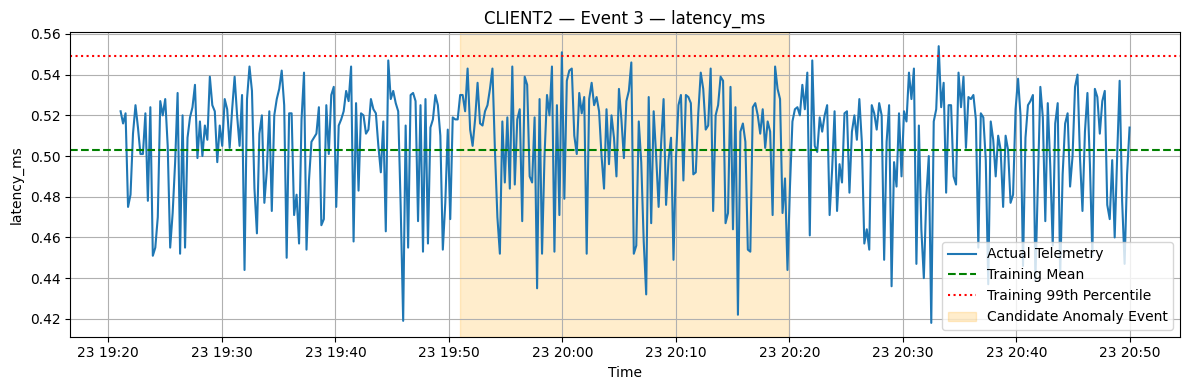

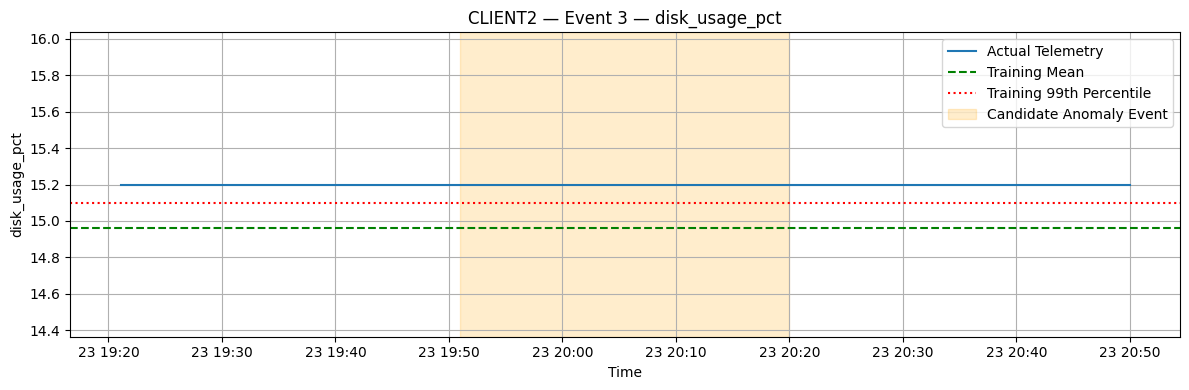

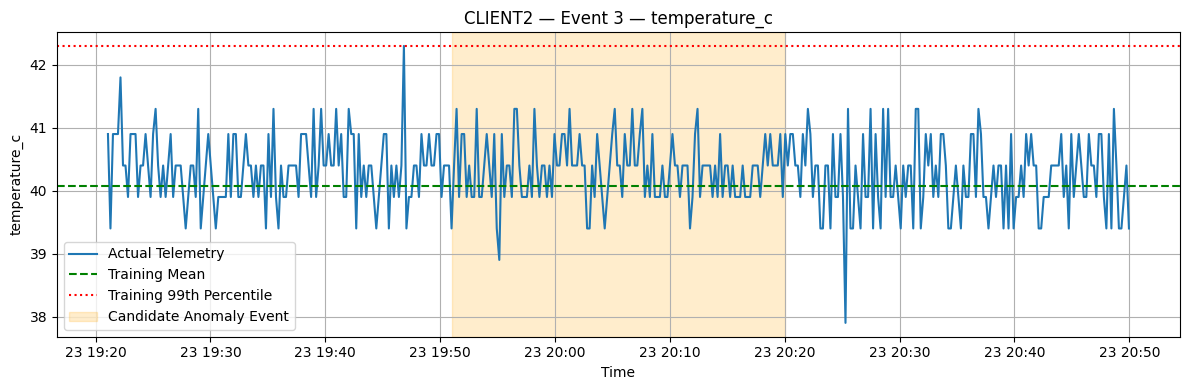

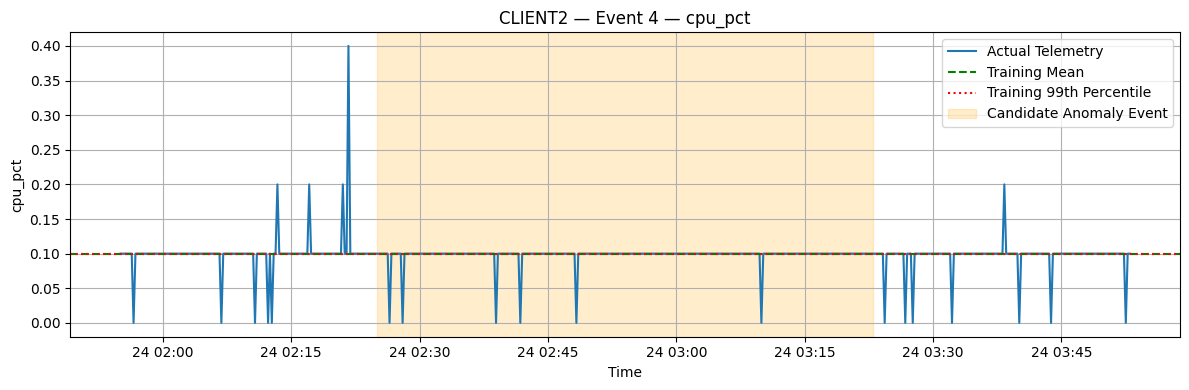

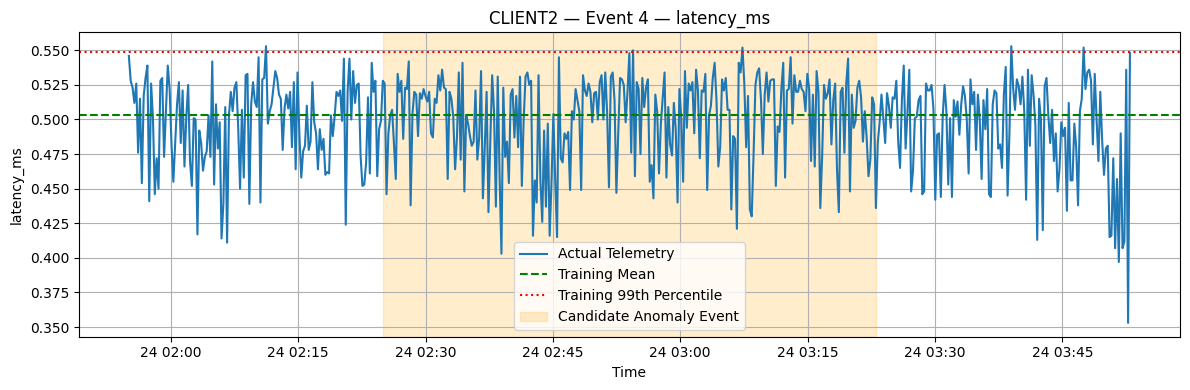

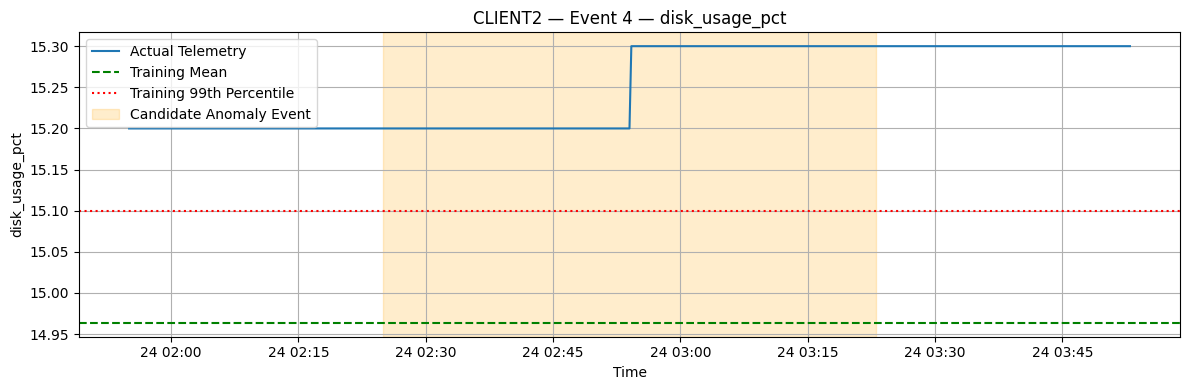

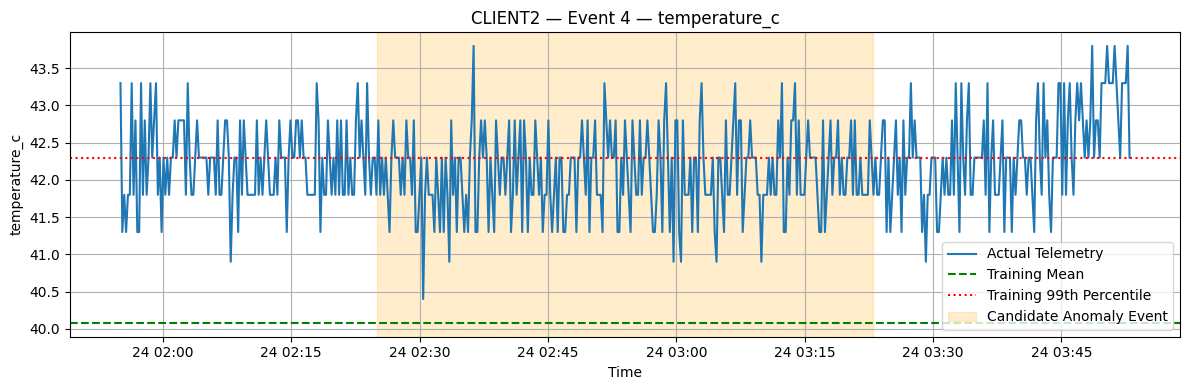

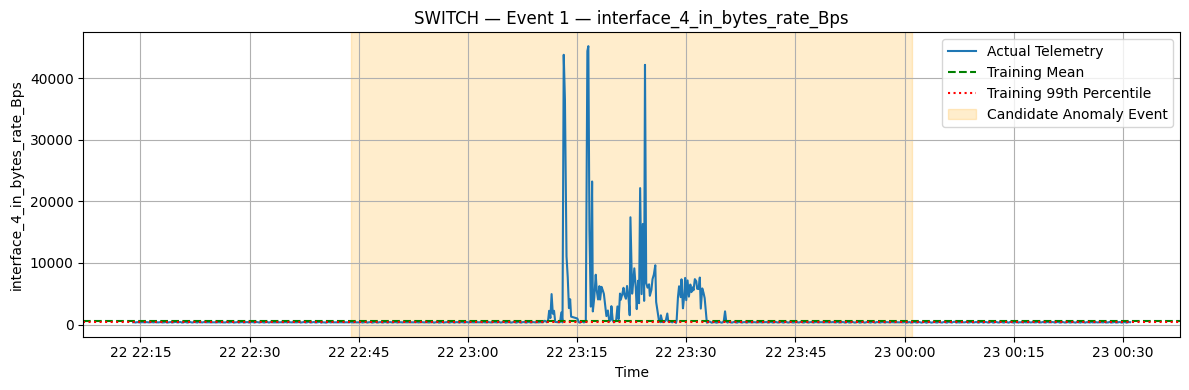

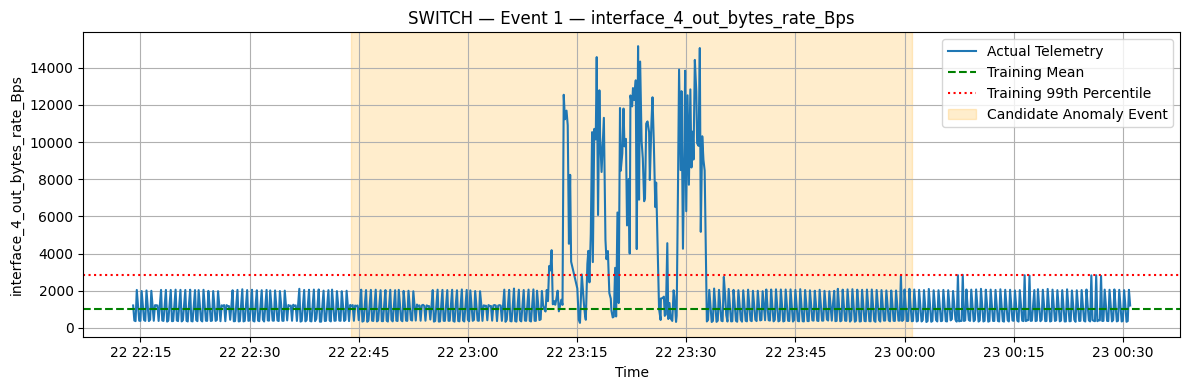

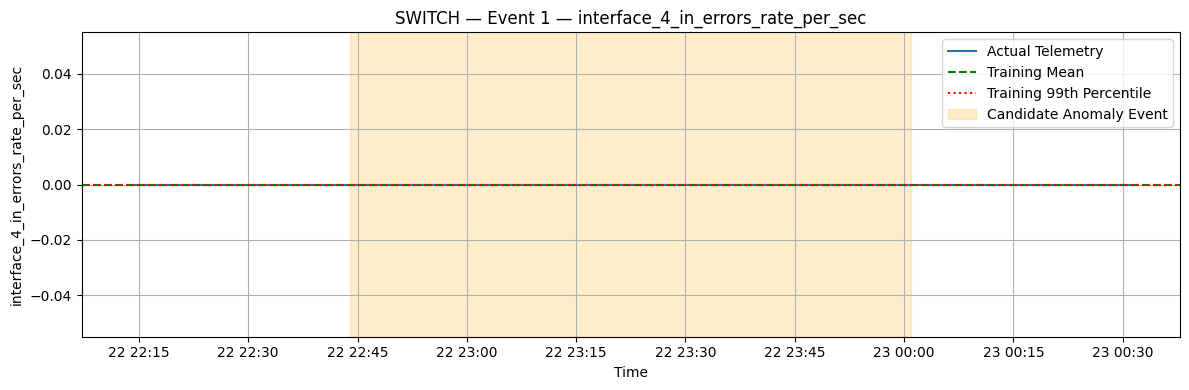

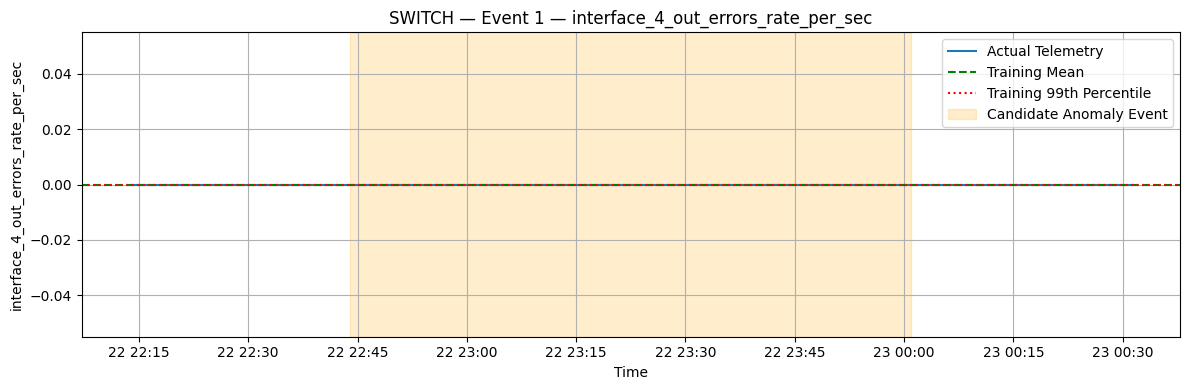

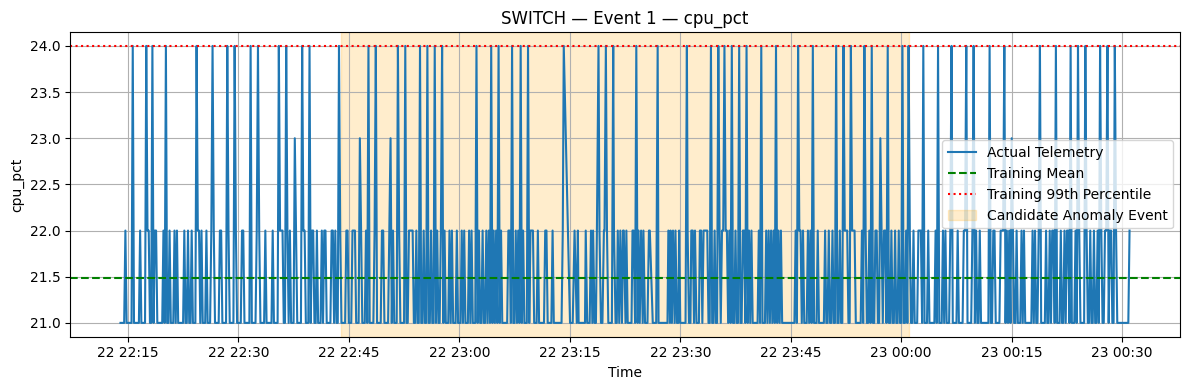

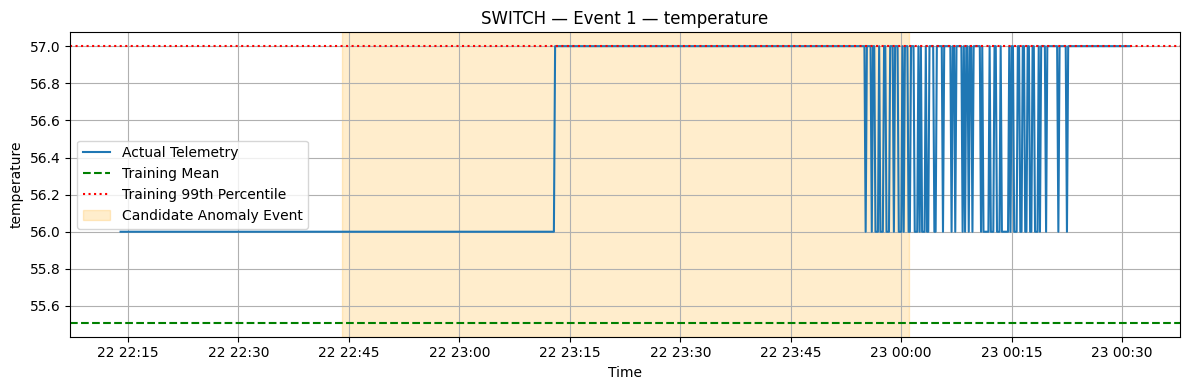

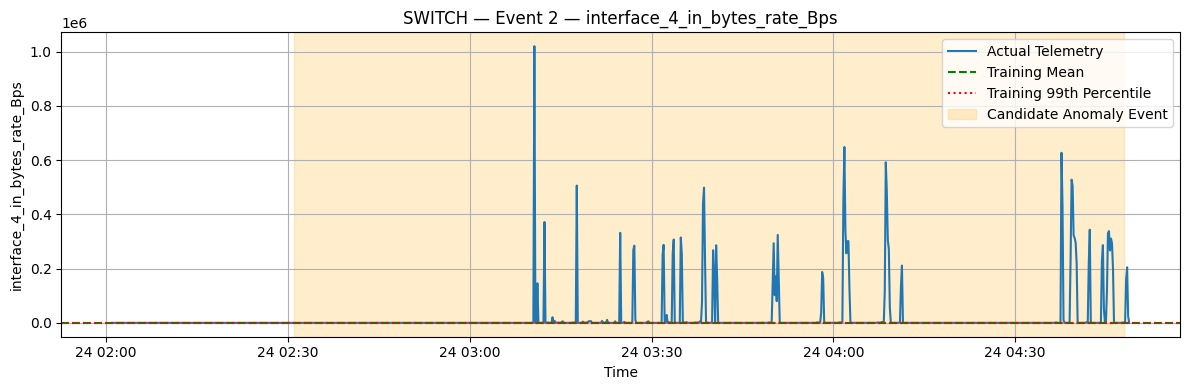

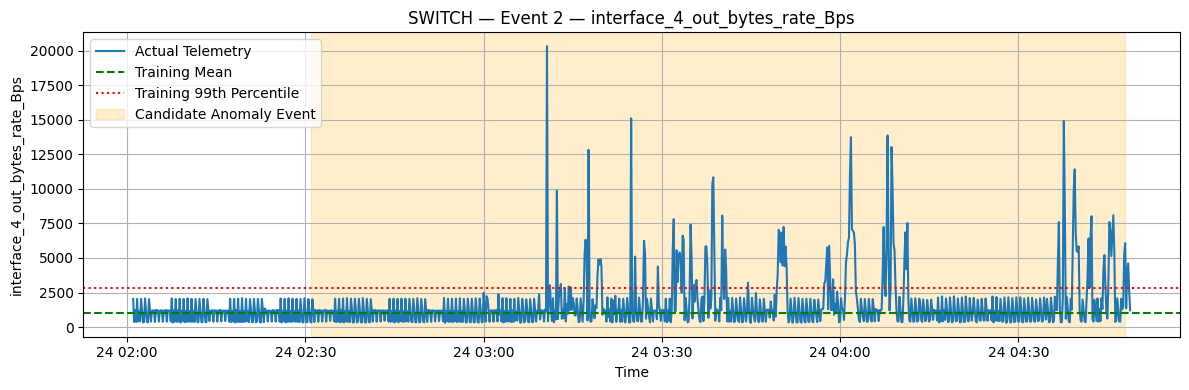

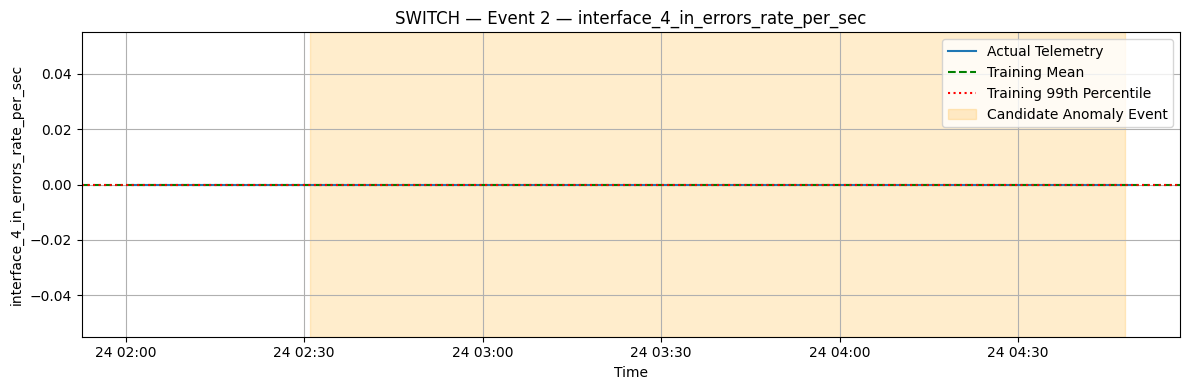

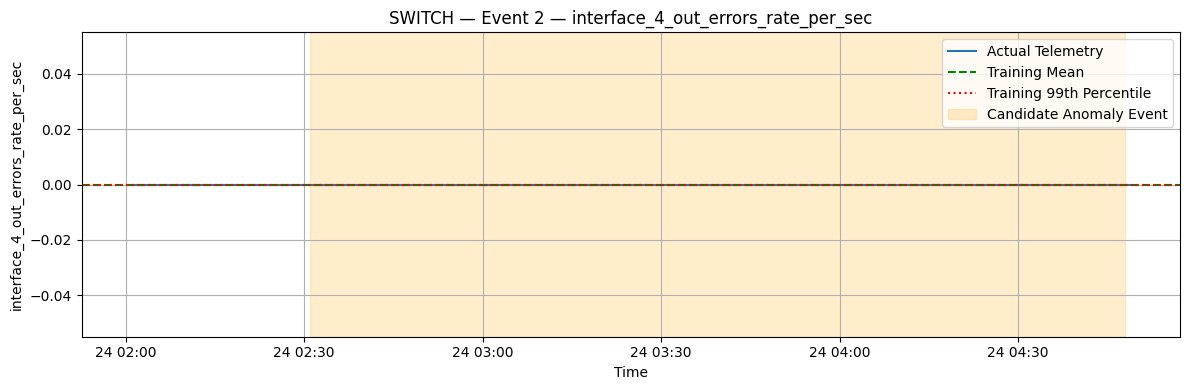

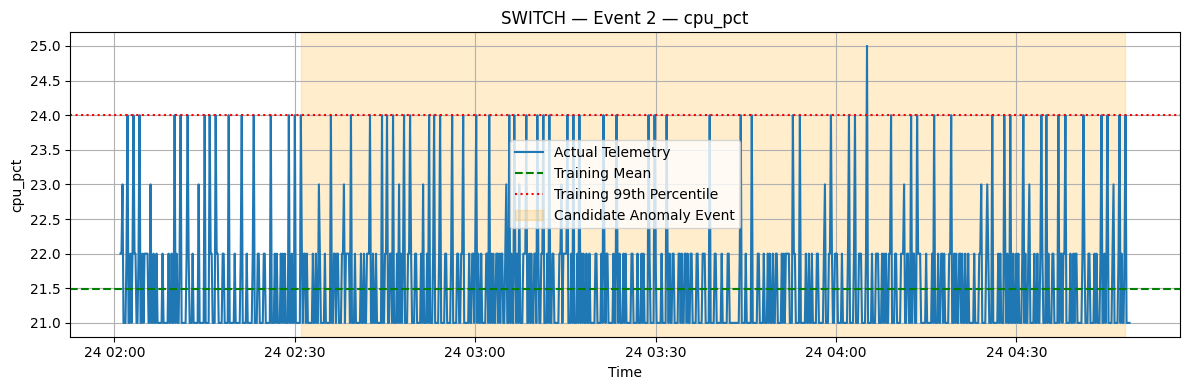

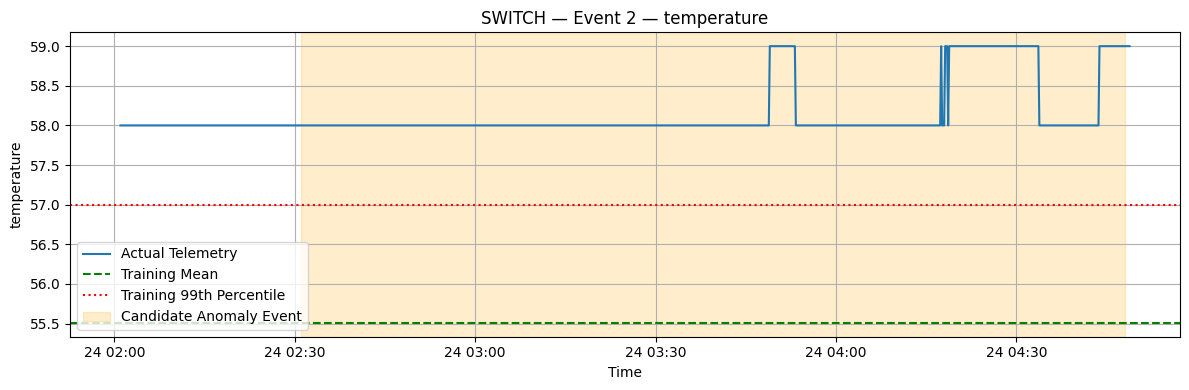

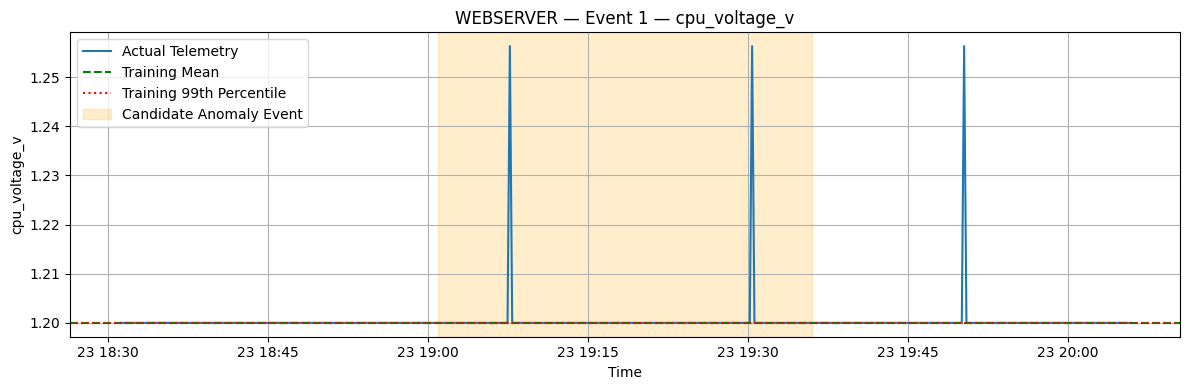

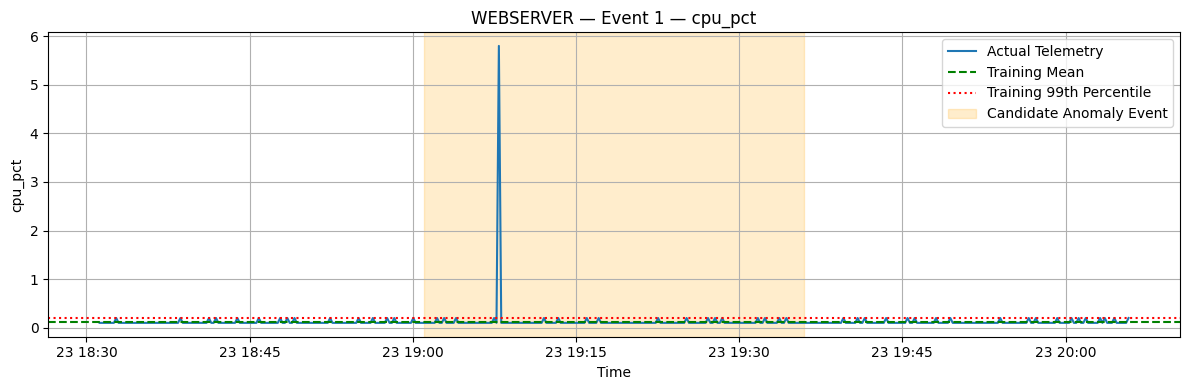

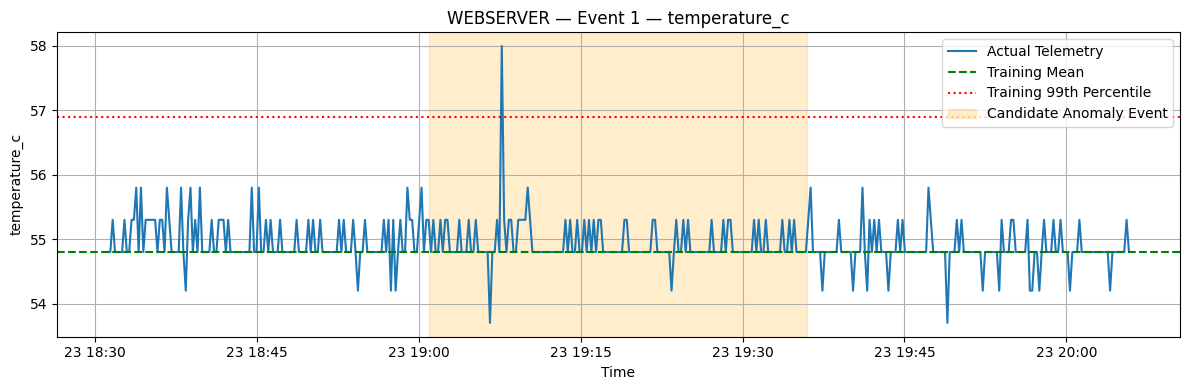

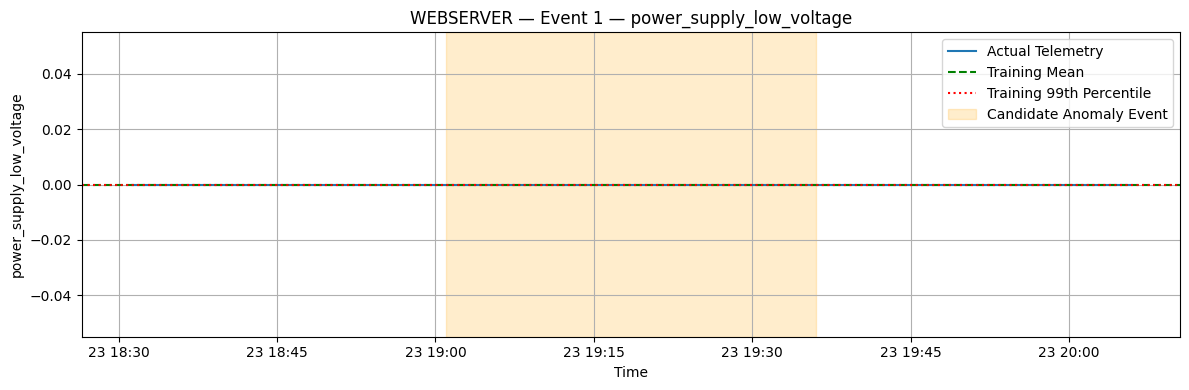

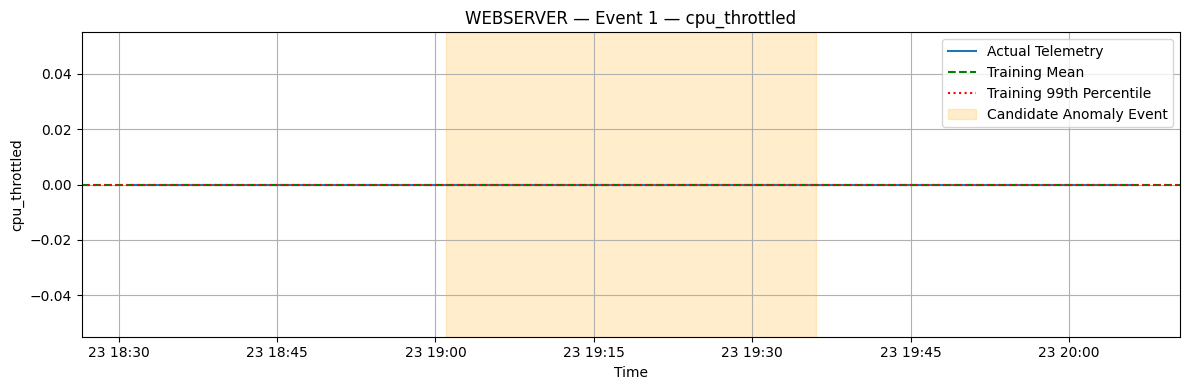


CLIENT2 — Possible Fault Indicators


,event_id,event_start,event_end,metric,normal_mean,normal_std,normal_p99,event_mean,event_min,event_max,deviation_std,above_normal_p99_pct,main_lstm_feature,large_deviation,frequent_extreme_values,possible_fault_indicator
1,1,2026-10-22 23:44:00+00:00,2026-10-23 00:29:00+00:00,latency_ms,0.503148,0.030393,0.549,0.514586,0.436,1.185,0.376336,14.646465,latency_ms_max,False,True,True
2,1,2026-10-22 23:44:00+00:00,2026-10-23 00:29:00+00:00,disk_usage_pct,14.963675,0.097188,15.100,15.200000,15.200,15.200,2.431637,100.000000,latency_ms_max,False,True,True
6,2,2026-10-23 18:15:00+00:00,2026-10-23 18:49:00+00:00,disk_usage_pct,14.963675,0.097188,15.100,15.200000,15.200,15.200,2.431637,100.000000,cpu_pct_max,False,True,True
10,3,2026-10-23 19:51:00+00:00,2026-10-23 20:20:00+00:00,disk_usage_pct,14.963675,0.097188,15.100,15.200000,15.200,15.200,2.431637,100.000000,cpu_pct_max,False,True,True
14,4,2026-10-24 02:25:00+00:00,2026-10-24 03:23:00+00:00,disk_usage_pct,14.963675,0.097188,15.100,15.249811,15.200,15.300,2.944164,100.000000,disk_usage_pct_std,False,True,True
15,4,2026-10-24 02:25:00+00:00,2026-10-24 03:23:00+00:00,temperature_c,40.079635,1.124473,42.300,42.075849,40.400,43.800,1.775245,20.377358,disk_usage_pct_std,False,True,True



SWITCH — Possible Fault Indicators


,event_id,event_start,event_end,metric,normal_mean,normal_std,normal_p99,event_mean,event_min,event_max,deviation_std,above_normal_p99_pct,main_lstm_feature,large_deviation,frequent_extreme_values,possible_fault_indicator
0,1,2026-10-22 22:44:00+00:00,2026-10-23 00:01:00+00:00,interface_4_in_bytes_rate_Bps,516.720523,6413.389220,438.900,1826.775031,262.769231,4.525125e+04,0.204269,25.601751,interface_4_out_bytes_rate_Bps_mean,False,True,True
1,1,2026-10-22 22:44:00+00:00,2026-10-23 00:01:00+00:00,interface_4_out_bytes_rate_Bps,1029.742676,768.221993,2859.415,2508.220608,266.400000,1.515691e+04,1.924545,18.818381,interface_4_out_bytes_rate_Bps_mean,False,True,True
6,2,2026-10-24 02:31:00+00:00,2026-10-24 04:48:00+00:00,interface_4_in_bytes_rate_Bps,516.720523,6413.389220,438.900,24334.548846,278.900000,1.020345e+06,3.713766,24.908870,interface_4_in_bytes_rate_Bps_std,True,True,True
7,2,2026-10-24 02:31:00+00:00,2026-10-24 04:48:00+00:00,interface_4_out_bytes_rate_Bps,1029.742676,768.221993,2859.415,1800.615310,302.500000,2.033330e+04,1.003450,13.851762,interface_4_in_bytes_rate_Bps_std,False,True,True
11,2,2026-10-24 02:31:00+00:00,2026-10-24 04:48:00+00:00,temperature,55.508742,0.885313,57.000,58.177400,58.000000,5.900000e+01,3.014365,100.000000,interface_4_in_bytes_rate_Bps_std,True,True,True



WEBSERVER — Possible Fault Indicators


,event_id,event_start,event_end,metric,normal_mean,normal_std,normal_p99,event_mean,event_min,event_max,deviation_std,above_normal_p99_pct,main_lstm_feature,large_deviation,frequent_extreme_values,possible_fault_indicator



Section 9 complete
Results saved to: lstm_fault_investigation


In [15]:


# ============================================================
# Section 9 — Feature-Level Anomaly Investigation
# ============================================================

# output directory
INVESTIGATION_DIR = Path("lstm_fault_investigation")
INVESTIGATION_DIR.mkdir(parents=True, exist_ok=True)


# metrics to investigate for each device
INVESTIGATION_METRICS = {
    "client1": [
        "cpu_pct",
        "cpu_voltage_v",
        "temperature_c",
        "latency_ms",
    ],
    "client2": [
        "cpu_pct",
        "latency_ms",
        "disk_usage_pct",
        "temperature_c",
    ],
    "switch": [
        "interface_4_in_bytes_rate_Bps",
        "interface_4_out_bytes_rate_Bps",
        "interface_4_in_errors_rate_per_sec",
        "interface_4_out_errors_rate_per_sec",
        "cpu_pct",
        "temperature",
    ],
    "webserver": [
        "cpu_voltage_v",
        "cpu_pct",
        "temperature_c",
        "power_supply_low_voltage",
        "cpu_throttled",
    ],
}


# ------------------------------------------------------------
# 9.1 Calculate normal operating statistics
# ------------------------------------------------------------

NORMAL_STATISTICS = {}

for device_name, df in CLIENT_DATA.items():

    # identify available investigation metrics
    metrics = [
        metric for metric in INVESTIGATION_METRICS[device_name]
        if metric in df.columns
    ]

    # use training-period measurements only
    training_end = SPLIT_SUMMARY[
        device_name
    ]["train_end"]

    training_data = df.loc[
        df.index <= training_end,
        metrics
    ]

    # calculate normal operating reference statistics
    statistics = training_data.agg([
        "mean",
        "median",
        "std",
        "min",
        "max",
    ]).T

    statistics["p95"] = training_data.quantile(0.95)
    statistics["p99"] = training_data.quantile(0.99)

    NORMAL_STATISTICS[device_name] = statistics

    print(f"\n{device_name.upper()} — Training Reference")
    display(statistics.round(4))

    statistics.to_csv(
        INVESTIGATION_DIR /
        f"{device_name}_normal_statistics.csv"
    )


# ------------------------------------------------------------
# 9.2 Compare anomaly events against training statistics
# ------------------------------------------------------------

FAULT_INVESTIGATION = {}

for device_name, events in ANOMALY_EVENTS.items():

    df = CLIENT_DATA[device_name]

    metrics = [
        metric for metric in INVESTIGATION_METRICS[device_name]
        if metric in df.columns
    ]

    reference = NORMAL_STATISTICS[device_name]

    investigation_rows = []

    # investigate detected events
    for _, event in events.iterrows():

        event_data = df.loc[
            event["start_time"]:event["end_time"],
            metrics
        ]

        if event_data.empty:
            continue

        for metric in metrics:

            values = event_data[metric].dropna()

            if values.empty:
                continue

            # normal reference statistics
            normal_mean = reference.loc[metric, "mean"]
            normal_std = reference.loc[metric, "std"]
            normal_p99 = reference.loc[metric, "p99"]

            # event statistics
            event_mean = values.mean()
            event_max = values.max()
            event_min = values.min()

            # deviation from normal behaviour
            if pd.notna(normal_std) and normal_std > 0:
                deviation_std = (
                    event_mean - normal_mean
                ) / normal_std
            else:
                deviation_std = np.nan

            # percentage of measurements above normal p99
            above_p99_pct = (
                100 * (values > normal_p99).mean()
            )

            investigation_rows.append({
                "event_id": event["event_id"],
                "event_start": event["start_time"],
                "event_end": event["end_time"],
                "metric": metric,
                "normal_mean": normal_mean,
                "normal_std": normal_std,
                "normal_p99": normal_p99,
                "event_mean": event_mean,
                "event_min": event_min,
                "event_max": event_max,
                "deviation_std": deviation_std,
                "above_normal_p99_pct": above_p99_pct,
                "main_lstm_feature": event["main_feature"],
            })

    investigation = pd.DataFrame(investigation_rows)

    FAULT_INVESTIGATION[device_name] = investigation

    print(f"\n{'=' * 60}")
    print(f"{device_name.upper()} — Feature Investigation")
    print(f"{'=' * 60}")

    if not investigation.empty:

        display(investigation.round(4))

        investigation.to_csv(
            INVESTIGATION_DIR /
            f"{device_name}_feature_investigation.csv",
            index=False
        )

    else:
        print("No detected events to investigate.")


# ------------------------------------------------------------
# 9.3 Investigate Client1 near-threshold periods
# ------------------------------------------------------------

client1_results = ANOMALY_RESULTS["client1"]["test"]

# identify 20 highest-error sequences
client1_high_errors = client1_results.nlargest(
    20,
    "reconstruction_error"
)

print("\nCLIENT1 — Highest Reconstruction Errors")
display(client1_high_errors)

# extract telemetry surrounding high-error periods
if not client1_high_errors.empty:

    start_time = (
        client1_high_errors.index.min()
        - pd.Timedelta(minutes=30)
    )

    end_time = client1_high_errors.index.max()

    client1_metrics = [
        metric for metric in INVESTIGATION_METRICS["client1"]
        if metric in CLIENT_DATA["client1"].columns
    ]

    client1_telemetry = CLIENT_DATA["client1"].loc[
        start_time:end_time,
        client1_metrics
    ]

    client1_telemetry.to_csv(
        INVESTIGATION_DIR /
        "client1_high_error_telemetry.csv"
    )

    print("\nClient1 high-error telemetry:")
    display(client1_telemetry.describe())


# ------------------------------------------------------------
# 9.4 Plot anomaly telemetry against normal operating ranges
# ------------------------------------------------------------

for device_name, events in ANOMALY_EVENTS.items():

    if events.empty:
        continue

    df = CLIENT_DATA[device_name]
    reference = NORMAL_STATISTICS[device_name]

    metrics = [
        metric for metric in INVESTIGATION_METRICS[device_name]
        if metric in df.columns
    ]

    for _, event in events.iterrows():

        # include context surrounding the event
        start = (
            event["start_time"]
            - pd.Timedelta(minutes=30)
        )

        end = (
            event["end_time"]
            + pd.Timedelta(minutes=30)
        )

        event_data = df.loc[start:end]

        for metric in metrics:

            plt.figure(figsize=(12, 4))

            # actual telemetry
            plt.plot(
                event_data.index,
                event_data[metric],
                label="Actual Telemetry"
            )

            # training reference mean
            plt.axhline(
                reference.loc[metric, "mean"],
                linestyle="--",
                color="green",
                label="Training Mean"
            )

            # training 99th percentile
            plt.axhline(
                reference.loc[metric, "p99"],
                linestyle=":",
                color="red",
                label="Training 99th Percentile"
            )

            # estimated anomaly period
            plt.axvspan(
                event["start_time"],
                event["end_time"],
                color="orange",
                alpha=0.2,
                label="Candidate Anomaly Event"
            )

            plt.title(
                f"{device_name.upper()} — "
                f"Event {event['event_id']} — {metric}"
            )

            plt.xlabel("Time")
            plt.ylabel(metric)
            plt.legend()
            plt.grid(True)
            plt.tight_layout()

            plt.savefig(
                INVESTIGATION_DIR /
                f"{device_name}_event_"
                f"{event['event_id']}_{metric}.png",
                dpi=150
            )

            plt.show()


# ------------------------------------------------------------
# 9.5 Identify possible fault indicators
# ------------------------------------------------------------

FAULT_INDICATORS = {}

for device_name, investigation in FAULT_INVESTIGATION.items():

    if investigation.empty:
        FAULT_INDICATORS[device_name] = pd.DataFrame()
        continue

    indicators = investigation.copy()

    # flag large deviations from training mean
    indicators["large_deviation"] = (
        indicators["deviation_std"].abs() >= 3
    )

    # flag periods frequently exceeding training p99
    indicators["frequent_extreme_values"] = (
        indicators["above_normal_p99_pct"] >= 10
    )

    # identify noteworthy metric changes
    indicators["possible_fault_indicator"] = (
        indicators["large_deviation"]
        | indicators["frequent_extreme_values"]
    )

    FAULT_INDICATORS[device_name] = indicators

    important = indicators[
        indicators["possible_fault_indicator"]
    ]

    print(f"\n{device_name.upper()} — Possible Fault Indicators")

    display(important)

    indicators.to_csv(
        INVESTIGATION_DIR /
        f"{device_name}_fault_indicators.csv",
        index=False
    )


print("\nSection 9 complete")
print(f"Results saved to: {INVESTIGATION_DIR}")


10 - Evaluation and deployment


FAULT EVALUATION — CLIENT1
Fault starts: 2026-10-23 09:24:00+00:00
Fault ends:   2026-10-23 10:23:00+00:00

Scenario: cpu_increase


C:\Users\alwyn\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCache\local-packages\Python312\site-packages\sklearn\utils\validation.py:2691: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(


Fault detection recall: 100.00%
Newly triggered window rate: 100.00%
False-positive rate (control): 0.00%
Precision (experimental): 100.00%
Event detected: True
Detection delay: 0.0 minutes

Scenario: temperature_increase


C:\Users\alwyn\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCache\local-packages\Python312\site-packages\sklearn\utils\validation.py:2691: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(


Fault detection recall: 0.00%
Newly triggered window rate: 0.00%
False-positive rate (control): 0.00%
Precision (experimental): nan%
Event detected: False
Detection delay: NOT DETECTED

Scenario: latency_increase


...

C:\Users\alwyn\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCache\local-packages\Python312\site-packages\sklearn\utils\validation.py:2691: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(


Fault detection recall: 93.33%
Newly triggered window rate: 93.33%
False-positive rate (control): 0.31%
Precision (experimental): 88.89%
Event detected: True
Detection delay: 4.0 minutes

FAULT INJECTION PERFORMANCE SUMMARY


,device,scenario,recall_pct,incremental_recall_pct,precision_pct,false_positive_rate_pct,event_detected,detection_delay_minutes
0,client1,cpu_increase,100.00,100.00,100.00,0.00,True,0.0
1,client1,temperature_increase,0.00,0.00,NaN,0.00,False,NaN
2,client1,latency_increase,100.00,100.00,100.00,0.00,True,0.0
3,client1,packet_loss_increase,91.67,91.67,100.00,0.00,True,5.0
4,client2,cpu_increase,100.00,100.00,52.63,2.21,True,0.0
5,client2,temperature_increase,0.00,0.00,0.00,2.21,False,NaN
6,client2,latency_increase,100.00,100.00,52.63,2.21,True,0.0
7,client2,packet_loss_increase,93.33,93.33,50.91,2.21,True,4.0
8,switch,incoming_traffic_surge,0.00,0.00,0.00,6.93,False,NaN
9,switch,outgoing_traffic_surge,95.00,95.00,26.51,6.93,True,3.0



DEVICE-LEVEL PERFORMANCE SUMMARY


,scenarios,mean_recall_pct,mean_incremental_recall_pct,mean_precision_pct,mean_fpr_pct,events_detected,mean_detection_delay_minutes
device,,,,,,,
client1,4,72.92,72.92,100.00,0.00,3,1.67
client2,4,73.33,73.33,39.04,2.21,3,1.33
switch,3,61.67,61.67,17.33,6.93,2,4.50
webserver,4,88.33,88.33,87.93,0.31,4,7.00


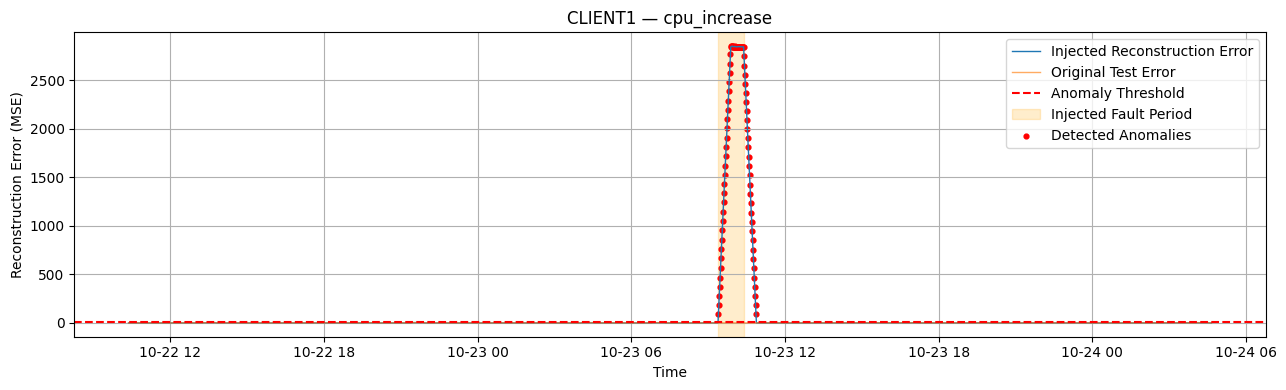

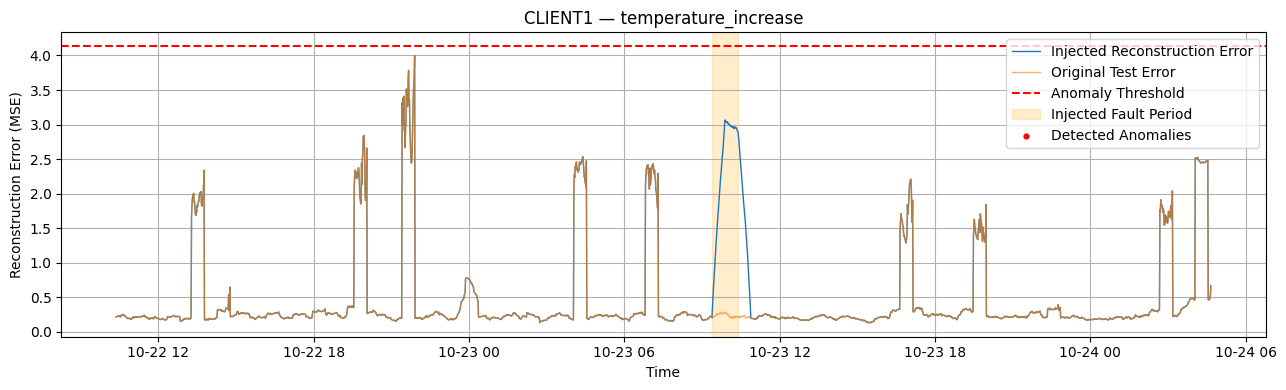

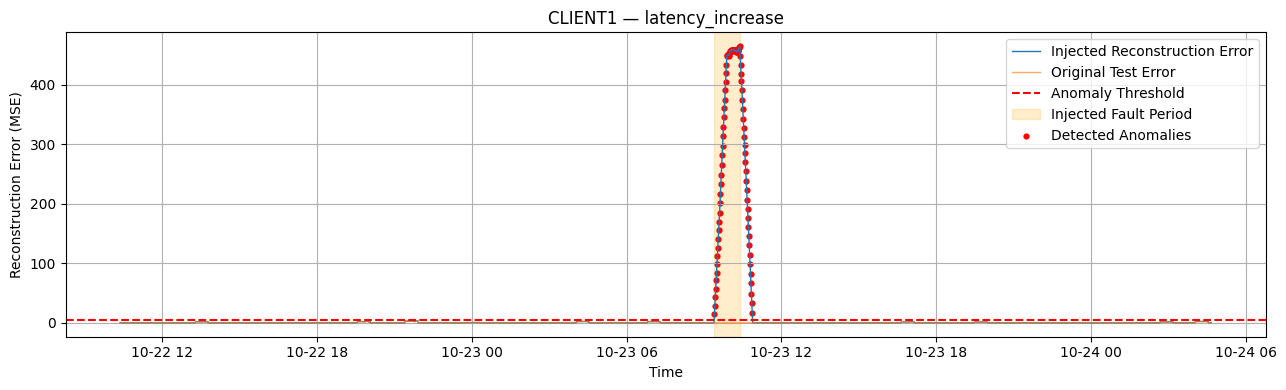

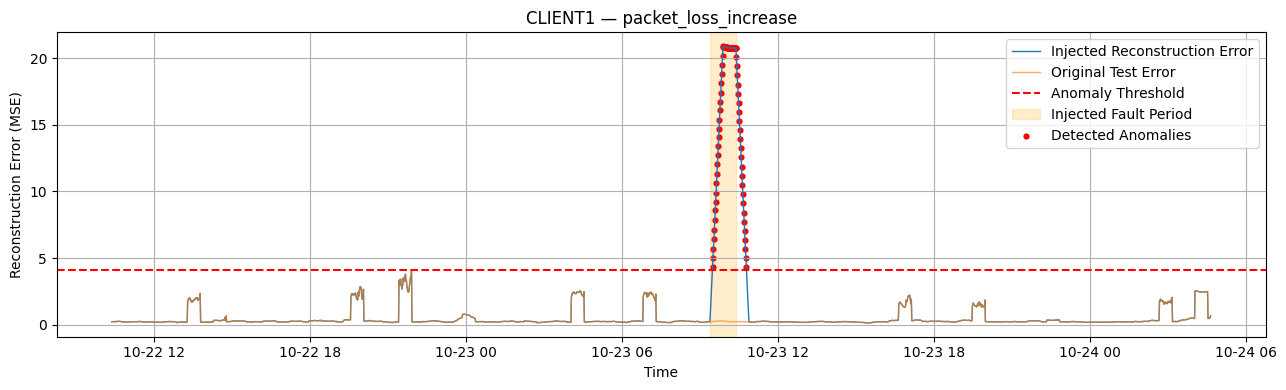

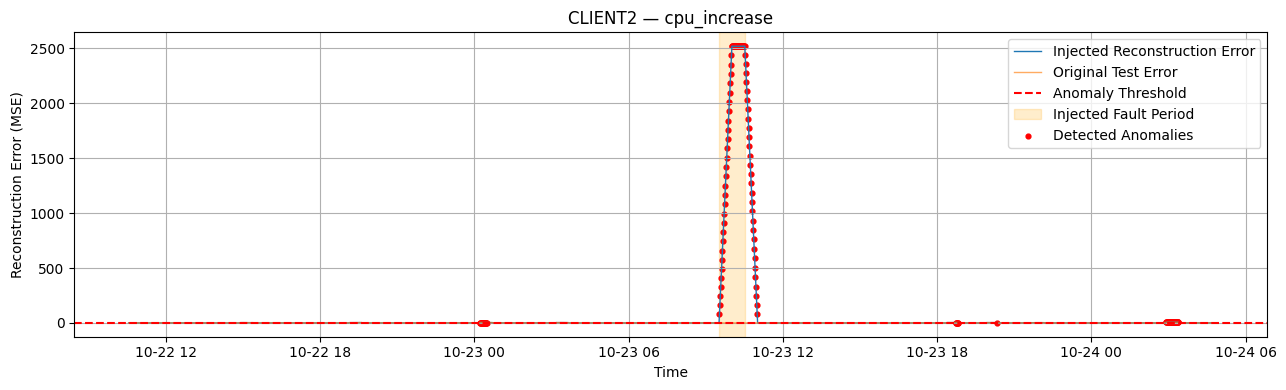

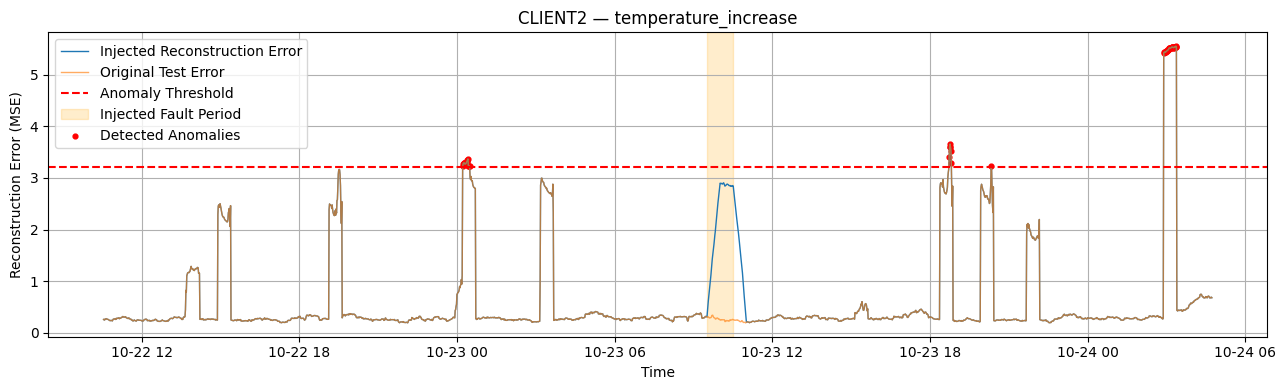

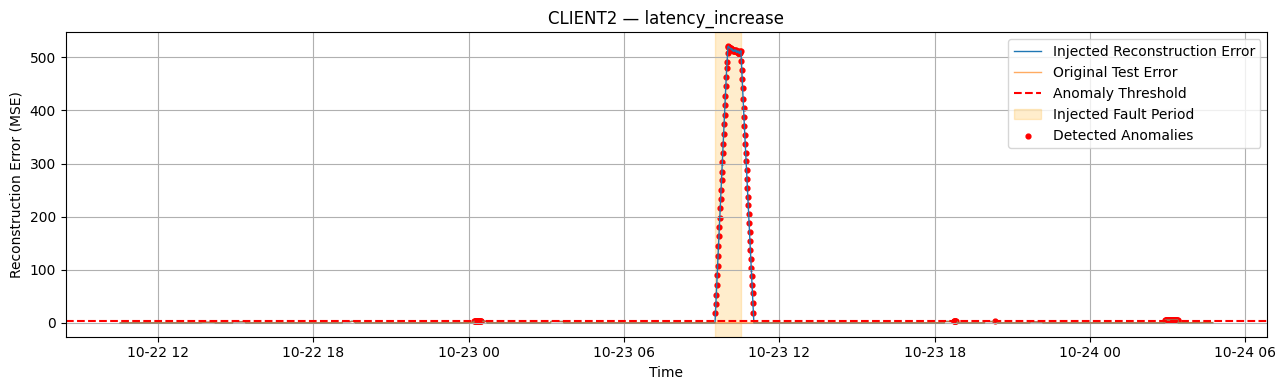

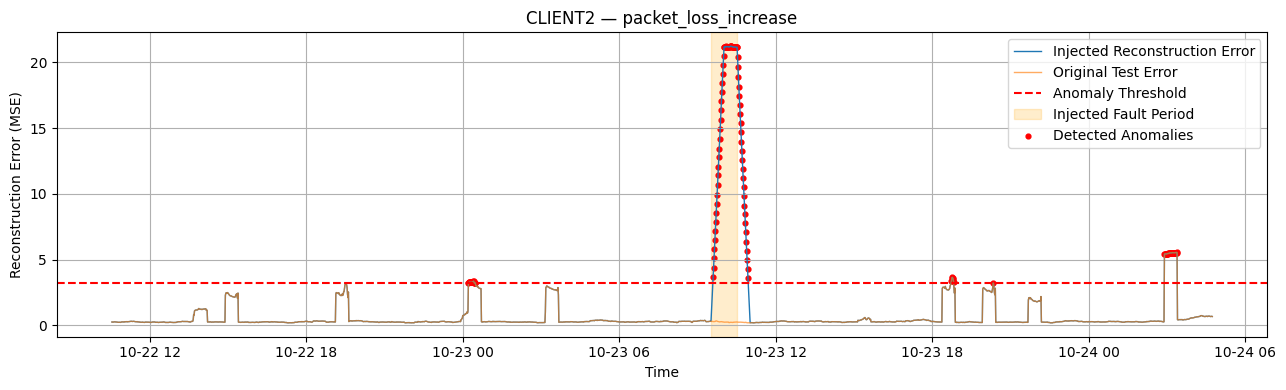

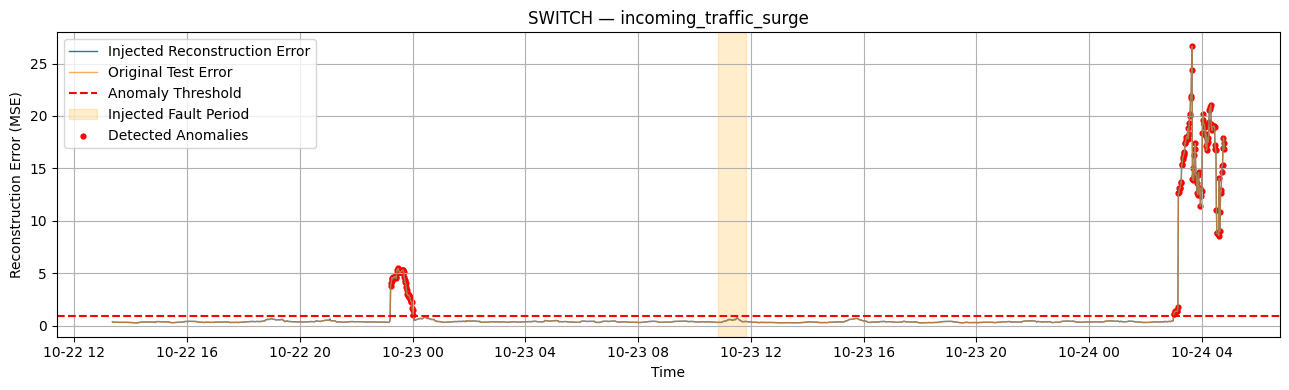

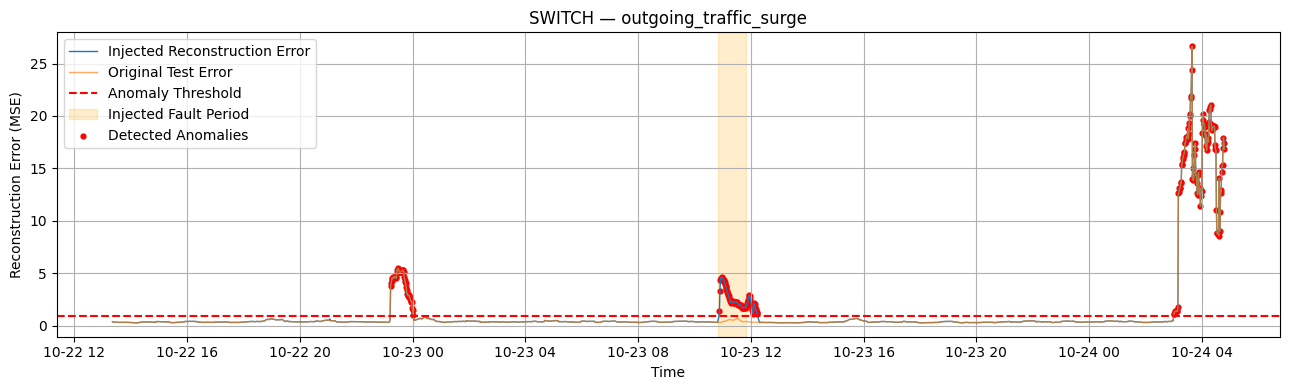

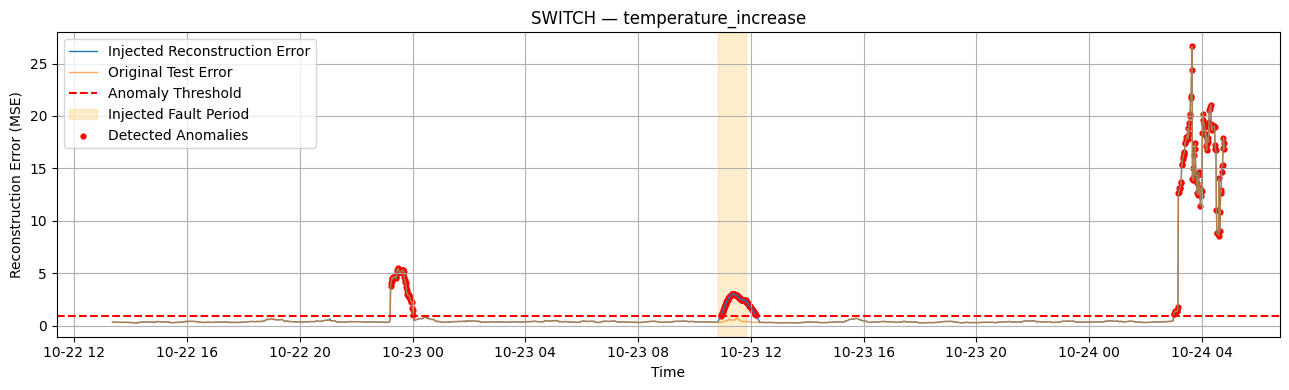

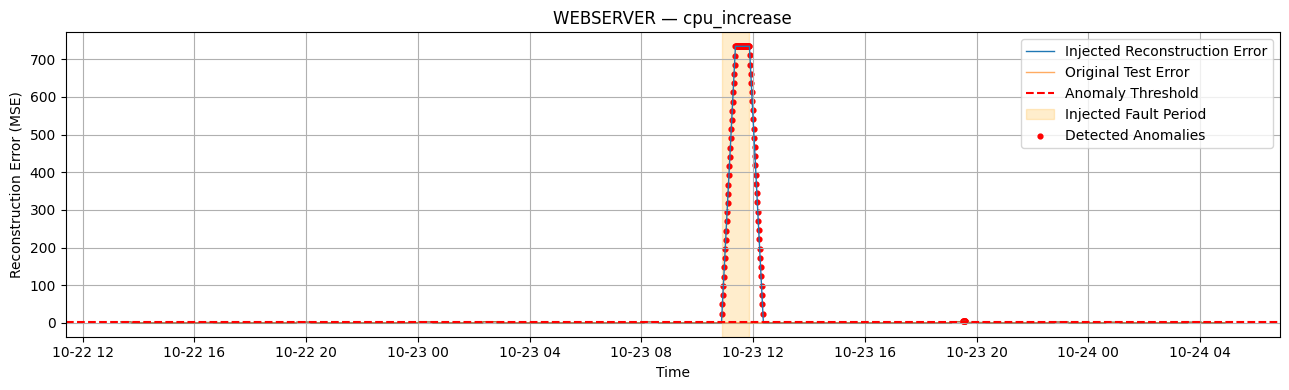

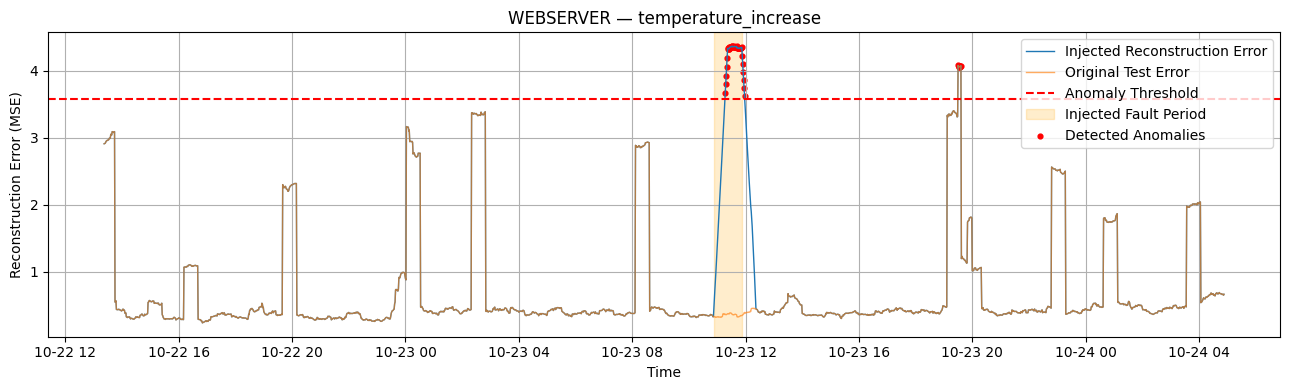

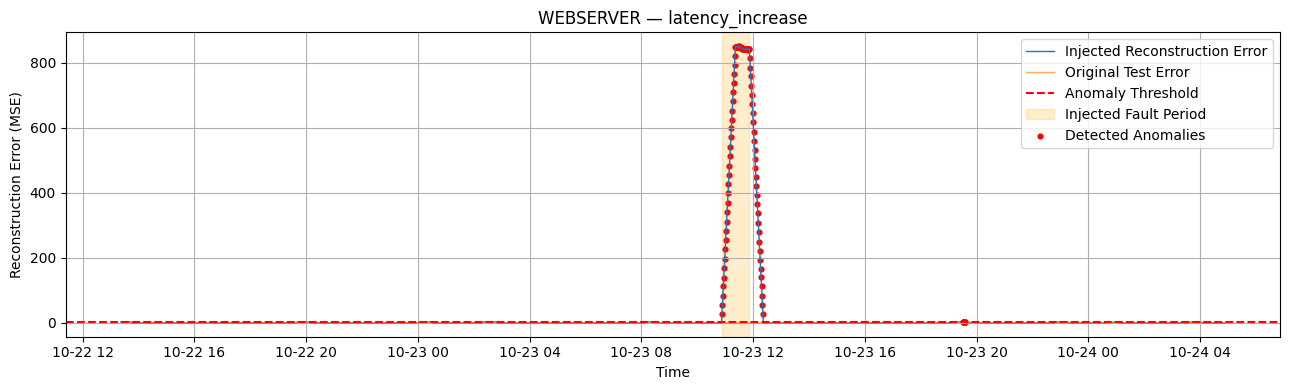

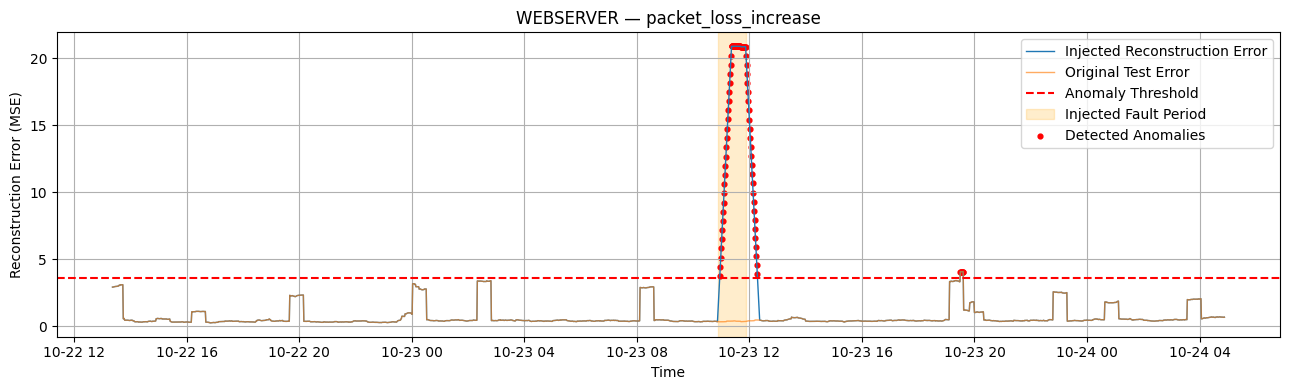


Section 10 complete
Results saved to: lstm_fault_evaluation


In [16]:

# ============================================================
# Section 10 — Controlled Fault Injection and Evaluation
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

FAULT_DIR = Path("lstm_fault_evaluation")
FAULT_DIR.mkdir(parents=True, exist_ok=True)

FAULT_DURATION_MINUTES = 60
FAULT_START_FRACTION = 0.55

FAULT_RESULTS = {}
FAULT_SUMMARY = []


# ------------------------------------------------------------
# 10.1 Define fault injection scenarios
# ------------------------------------------------------------

# add: increase metric by a fixed amount
# multiply: multiply metric by a fixed factor
#
# Important: cpu_pct values are percentage points.
# For example, 0.1 + 10 = 10.1%.

FAULT_SCENARIOS = {
    "client1": {
        "cpu_increase": ("cpu_pct", "add", 10.0),
        "temperature_increase": (
            "temperature_c", "add", 8.0
        ),
        "latency_increase": (
            "latency_ms", "multiply", 4.0
        ),
        "packet_loss_increase": (
            "packet_loss_pct", "add", 20.0
        ),
    },

    "client2": {
        "cpu_increase": ("cpu_pct", "add", 10.0),
        "temperature_increase": (
            "temperature_c", "add", 8.0
        ),
        "latency_increase": (
            "latency_ms", "multiply", 4.0
        ),
        "packet_loss_increase": (
            "packet_loss_pct", "add", 20.0
        ),
    },

    "switch": {
        "incoming_traffic_surge": (
            "interface_4_in_bytes_rate_Bps",
            "multiply",
            5.0
        ),
        "outgoing_traffic_surge": (
            "interface_4_out_bytes_rate_Bps",
            "multiply",
            5.0
        ),
        "temperature_increase": (
            "temperature", "add", 8.0
        ),
    },

    "webserver": {
        "cpu_increase": ("cpu_pct", "add", 10.0),
        "temperature_increase": (
            "temperature_c", "add", 8.0
        ),
        "latency_increase": (
            "latency_ms", "multiply", 4.0
        ),
        "packet_loss_increase": (
            "packet_loss_pct", "add", 20.0
        ),
    },
}


# ------------------------------------------------------------
# 10.2 Inject faults into engineered telemetry
# ------------------------------------------------------------

def inject_fault(
    scaled_values,
    scaler,
    feature_columns,
    metric,
    operation,
    magnitude,
    injection_mask
):
    """
    Inject a synthetic fault into a COPY of test features.

    Changes mean and max for additive faults.
    Changes mean, max and std for multiplicative faults.

    Does not modify original telemetry or fitted scalers.
    """

    original = scaler.inverse_transform(scaled_values)
    modified = original.copy()

    modified_features = []

    for i, feature in enumerate(feature_columns):

        if not feature.startswith(metric + "_"):
            continue

        suffix = feature[len(metric) + 1:]

        # Constant offsets do not change within-bin std.
        if operation == "add":
            if suffix not in ["mean", "max"]:
                continue
            modified[injection_mask, i] += magnitude

        elif operation == "multiply":
            if suffix not in ["mean", "max", "std"]:
                continue
            modified[injection_mask, i] *= magnitude

        else:
            raise ValueError(
                f"Unknown injection operation: {operation}"
            )

        # Keep percentage-type values physically bounded.
        if metric in [
            "cpu_pct",
            "packet_loss_pct",
        ]:
            modified[injection_mask, i] = np.clip(
                modified[injection_mask, i],
                0,
                100
            )

        modified_features.append(feature)

    if not modified_features:
        raise ValueError(
            f"No injectable features found for {metric}. "
            f"Available: {feature_columns}"
        )

    modified_scaled = scaler.transform(modified)

    return (
        modified_scaled.astype(np.float32),
        modified_features
    )


# ------------------------------------------------------------
# 10.3 Calculate reconstruction errors
# ------------------------------------------------------------

def evaluate_sequences(model, sequences, threshold):

    reconstruction = model.predict(
        sequences,
        batch_size=BATCH_SIZE,
        verbose=0
    )

    errors = np.mean(
        np.square(sequences - reconstruction),
        axis=(1, 2)
    )

    predictions = errors > threshold

    return errors, predictions


# ------------------------------------------------------------
# 10.4 Select a common fault injection period
# ------------------------------------------------------------

FAULT_PERIODS = {}

for device_name in FAULT_SCENARIOS:

    timestamps = pd.DatetimeIndex(
        SPLIT_DATA[device_name]["test_times"]
    )

    if len(timestamps) < (
        FAULT_DURATION_MINUTES + SEQUENCE_LENGTH
    ):
        raise ValueError(
            f"Insufficient test samples for {device_name}"
        )

    # Prefer a point around 55% into the test period.
    preferred = int(
        len(timestamps) * FAULT_START_FRACTION
    )

    # Choose an uninterrupted run of 1-minute samples.
    expected_step = pd.Timedelta(
        WINDOWS[ACTIVE_WINDOW]
    )

    required_length = (
        FAULT_DURATION_MINUTES + SEQUENCE_LENGTH
    )

    valid_starts = []

    for start in range(
        SEQUENCE_LENGTH,
        len(timestamps) - required_length + 1
    ):
        segment = timestamps[
            start - SEQUENCE_LENGTH + 1:
            start + required_length
        ]

        if (segment.to_series().diff().dropna()
                == expected_step).all():
            valid_starts.append(start)

    if not valid_starts:
        raise ValueError(
            f"No sufficiently continuous test period "
            f"for {device_name}"
        )

    start_index = min(
        valid_starts,
        key=lambda x: abs(x - preferred)
    )

    end_index = (
        start_index + FAULT_DURATION_MINUTES - 1
    )

    FAULT_PERIODS[device_name] = {
        "start": timestamps[start_index],
        "end": timestamps[end_index]
    }


# ------------------------------------------------------------
# 10.5 Run fault injection experiments
# ------------------------------------------------------------

for device_name, scenarios in FAULT_SCENARIOS.items():

    print(f"\n{'=' * 65}")
    print(f"FAULT EVALUATION — {device_name.upper()}")
    print(f"{'=' * 65}")

    model = LSTM_MODELS[device_name]
    scaler = SCALERS[device_name]

    threshold = ANOMALY_THRESHOLDS[device_name]

    feature_columns = list(
        FEATURE_COLUMNS[device_name]
    )

    original_scaled = np.asarray(
        SPLIT_DATA[device_name]["test"],
        dtype=np.float32
    )

    timestamps = pd.DatetimeIndex(
        SPLIT_DATA[device_name]["test_times"]
    )

    start_time = FAULT_PERIODS[device_name]["start"]
    end_time = FAULT_PERIODS[device_name]["end"]

    injection_mask = (
        (timestamps >= start_time) &
        (timestamps <= end_time)
    )

    print(f"Fault starts: {start_time}")
    print(f"Fault ends:   {end_time}")

    FAULT_RESULTS[device_name] = {}

    # Original test reconstruction errors are our control.
    baseline = ANOMALY_RESULTS[device_name]["test"]

    for scenario_name, scenario in scenarios.items():

        metric, operation, magnitude = scenario

        print(f"\nScenario: {scenario_name}")

        # ----------------------------------------------------
        # Inject fault into a fresh original test copy
        # ----------------------------------------------------

        modified_scaled, modified_features = inject_fault(
            original_scaled.copy(),
            scaler,
            feature_columns,
            metric,
            operation,
            magnitude,
            injection_mask
        )

        # ----------------------------------------------------
        # Rebuild sequences using the original Section 5
        # sequence generation function
        # ----------------------------------------------------

        X_fault, fault_times = create_sequences(
            modified_scaled,
            timestamps,
            SEQUENCE_LENGTH,
            SEQUENCE_STRIDE
        )

        fault_times = pd.DatetimeIndex(fault_times)

        # ----------------------------------------------------
        # Evaluate model
        # ----------------------------------------------------

        errors, predictions = evaluate_sequences(
            model,
            X_fault,
            threshold
        )

        results = pd.DataFrame({
            "reconstruction_error": errors,
            "threshold": threshold,
            "is_anomaly": predictions
        }, index=fault_times)

        results.index.name = "_time"

        # Match control scores to the same timestamps.
        aligned_baseline = baseline.reindex(fault_times)

        if aligned_baseline[
            "is_anomaly"
        ].isna().any():
            raise ValueError(
                "Baseline timestamps do not match "
                "generated fault sequences."
            )

        results["baseline_error"] = (
            aligned_baseline[
                "reconstruction_error"
            ].to_numpy()
        )

        results["baseline_anomaly"] = (
            aligned_baseline[
                "is_anomaly"
            ].to_numpy(dtype=bool)
        )

        # ----------------------------------------------------
        # Label sequences by their END timestamp.
        #
        # A sequence is fault-active when its ending
        # timestamp lies inside the injection interval.
        #
        # This gives a causal detection timeline:
        # no future samples are used.
        # ----------------------------------------------------

        active_fault = (
            (fault_times >= start_time) &
            (fault_times <= end_time)
        )

        # Window contamination lasts until all 30
        # fault-affected samples have exited the sequence.
        contamination_end = (
            end_time
            + pd.Timedelta(WINDOWS[ACTIVE_WINDOW])
            * (SEQUENCE_LENGTH - 1)
        )

        clean_control = (
            (fault_times < start_time) |
            (fault_times > contamination_end)
        )

        results["fault_active"] = active_fault
        results["clean_control"] = clean_control

        # ----------------------------------------------------
        # Detection metrics
        # ----------------------------------------------------

        tp = int(
            (predictions & active_fault).sum()
        )

        fn = int(
            (~predictions & active_fault).sum()
        )

        fp = int(
            (predictions & clean_control).sum()
        )

        tn = int(
            (~predictions & clean_control).sum()
        )

        recall = (
            tp / (tp + fn)
            if tp + fn > 0 else np.nan
        )

        precision = (
            tp / (tp + fp)
            if tp + fp > 0 else np.nan
        )

        false_positive_rate = (
            fp / (fp + tn)
            if fp + tn > 0 else np.nan
        )

        # Detection specifically triggered by injection,
        # excluding timestamps already flagged in baseline.
        newly_detected = (
            predictions &
            ~results["baseline_anomaly"].to_numpy() &
            active_fault
        )

        incremental_recall = (
            newly_detected.sum() / active_fault.sum()
            if active_fault.sum() > 0 else np.nan
        )

        # Detection delay
        detected_times = fault_times[
            active_fault & predictions
        ]

        if len(detected_times) > 0:
            detection_delay = (
                detected_times.min() - start_time
            ).total_seconds() / 60
        else:
            detection_delay = np.nan

        # Event-level detection:
        # Was the fault detected at least once?
        event_detected = bool(tp > 0)

        # Baseline alarms during the same fault period.
        baseline_detections = int(
            (
                results["baseline_anomaly"].to_numpy()
                & active_fault
            ).sum()
        )

        # ----------------------------------------------------
        # Store metrics
        # ----------------------------------------------------

        summary = {
            "device": device_name,
            "scenario": scenario_name,
            "injected_metric": metric,
            "operation": operation,
            "magnitude": magnitude,
            "fault_start": start_time,
            "fault_end": end_time,
            "fault_windows": int(active_fault.sum()),
            "TP": tp,
            "FN": fn,
            "FP": fp,
            "TN": tn,
            "recall_pct": recall * 100,
            "precision_pct": precision * 100,
            "false_positive_rate_pct": (
                false_positive_rate * 100
            ),
            "incremental_recall_pct": (
                incremental_recall * 100
            ),
            "baseline_fault_period_alerts": (
                baseline_detections
            ),
            "event_detected": event_detected,
            "detection_delay_minutes": (
                detection_delay
            ),
            "maximum_error": float(errors.max()),
            "threshold": threshold,
        }

        FAULT_SUMMARY.append(summary)

        FAULT_RESULTS[device_name][scenario_name] = {
            "results": results,
            "summary": summary,
            "modified_features": modified_features,
        }

        # ----------------------------------------------------
        # Display scenario results
        # ----------------------------------------------------

        print(
            f"Fault detection recall: "
            f"{recall * 100:.2f}%"
        )

        print(
            f"Newly triggered window rate: "
            f"{incremental_recall * 100:.2f}%"
        )

        print(
            f"False-positive rate (control): "
            f"{false_positive_rate * 100:.2f}%"
        )

        print(
            f"Precision (experimental): "
            f"{precision * 100:.2f}%"
        )

        print(f"Event detected: {event_detected}")

        print(
            f"Detection delay: "
            f"{detection_delay:.1f} minutes"
            if np.isfinite(detection_delay)
            else "Detection delay: NOT DETECTED"
        )

        # ----------------------------------------------------
        # Save results
        # ----------------------------------------------------

        results.to_csv(
            FAULT_DIR /
            f"{device_name}_{scenario_name}_results.csv"
        )


# ------------------------------------------------------------
# 10.6 Final performance summary
# ------------------------------------------------------------

FAULT_SUMMARY_DF = pd.DataFrame(FAULT_SUMMARY)

print("\n" + "=" * 70)
print("FAULT INJECTION PERFORMANCE SUMMARY")
print("=" * 70)

display(
    FAULT_SUMMARY_DF[[
        "device",
        "scenario",
        "recall_pct",
        "incremental_recall_pct",
        "precision_pct",
        "false_positive_rate_pct",
        "event_detected",
        "detection_delay_minutes",
    ]].round(2)
)

FAULT_SUMMARY_DF.to_csv(
    FAULT_DIR / "fault_detection_summary.csv",
    index=False
)


# ------------------------------------------------------------
# 10.7 Summary by device
# ------------------------------------------------------------

DEVICE_FAULT_SUMMARY = (
    FAULT_SUMMARY_DF
    .groupby("device")
    .agg(
        scenarios=("scenario", "count"),
        mean_recall_pct=("recall_pct", "mean"),
        mean_incremental_recall_pct=(
            "incremental_recall_pct", "mean"
        ),
        mean_precision_pct=("precision_pct", "mean"),
        mean_fpr_pct=(
            "false_positive_rate_pct", "mean"
        ),
        events_detected=("event_detected", "sum"),
        mean_detection_delay_minutes=(
            "detection_delay_minutes", "mean"
        ),
    )
)

print("\nDEVICE-LEVEL PERFORMANCE SUMMARY")
display(DEVICE_FAULT_SUMMARY.round(2))

DEVICE_FAULT_SUMMARY.to_csv(
    FAULT_DIR / "device_fault_summary.csv"
)


# ------------------------------------------------------------
# 10.8 Plot fault detection results
# ------------------------------------------------------------

for device_name, scenarios in FAULT_RESULTS.items():

    for scenario_name, experiment in scenarios.items():

        results = experiment["results"]
        summary = experiment["summary"]

        plt.figure(figsize=(13, 4))

        plt.plot(
            results.index,
            results["reconstruction_error"],
            label="Injected Reconstruction Error",
            linewidth=1
        )

        plt.plot(
            results.index,
            results["baseline_error"],
            label="Original Test Error",
            linewidth=1,
            alpha=0.65
        )

        plt.axhline(
            summary["threshold"],
            color="red",
            linestyle="--",
            label="Anomaly Threshold"
        )

        plt.axvspan(
            summary["fault_start"],
            summary["fault_end"],
            alpha=0.2,
            color="orange",
            label="Injected Fault Period"
        )

        detected = results[
            results["is_anomaly"]
        ]

        plt.scatter(
            detected.index,
            detected["reconstruction_error"],
            color="red",
            s=12,
            label="Detected Anomalies"
        )

        plt.title(
            f"{device_name.upper()} — {scenario_name}"
        )

        plt.xlabel("Time")
        plt.ylabel("Reconstruction Error (MSE)")
        plt.legend()
        plt.grid(True)
        plt.tight_layout()

        plt.savefig(
            FAULT_DIR /
            f"{device_name}_{scenario_name}.png",
            dpi=150
        )

        plt.show()


print("\nSection 10 complete")
print(f"Results saved to: {FAULT_DIR}")



THRESHOLD CALIBRATION


,device,percentile,threshold,train_alert_rate_pct,validation_alert_rate_pct
0,client1,95.0,2.1713,5.0071,3.7066
1,client1,97.5,2.8029,2.5036,1.3013
2,client1,99.0,4.1345,1.0048,0.2366
3,client1,99.5,4.9841,0.5024,0.0000
4,client2,95.0,1.9944,5.0055,7.1542
5,client2,97.5,2.5416,2.5027,3.2411
6,client2,99.0,3.2178,1.0078,1.5810
7,client2,99.5,4.4922,0.5039,1.1858
8,switch,95.0,0.4854,5.0027,5.6612
9,switch,97.5,0.5345,2.5013,1.6899



SELECTED THRESHOLDS


,threshold,percentile,validation_alert_rate_pct,validation_budget_met
client1,2.8029,97.5,1.3013,True
client2,3.2178,99.0,1.5810,True
switch,0.5345,97.5,1.6899,True
webserver,4.0451,99.5,0.7595,True



CLIENT1 injection periods:
1 2026-10-22 20:34:00+00:00 to 2026-10-22 21:33:00+00:00
2 2026-10-23 07:16:00+00:00 to 2026-10-23 08:15:00+00:00
3 2026-10-23 17:58:00+00:00 to 2026-10-23 18:57:00+00:00

CLIENT2 injection periods:
1 2026-10-22 20:44:00+00:00 to 2026-10-22 21:43:00+00:00
2 2026-10-23 07:24:00+00:00 to 2026-10-23 08:23:00+00:00
3 2026-10-23 18:04:00+00:00 to 2026-10-23 19:03:00+00:00

SWITCH injection periods:
1 2026-10-22 22:51:00+00:00 to 2026-10-22 23:50:00+00:00
2 2026-10-23 08:50:00+00:00 to 2026-10-23 09:49:00+00:00
3 2026-10-23 18:49:00+00:00 to 2026-10-23 19:48:00+00:00

WEBSERVER injection periods:
1 2026-10-22 22:53:00+00:00 to 2026-10-22 23:52:00+00:00
2 2026-10-23 08:53:00+00:00 to 2026-10-23 09:52:00+00:00
3 2026-10-23 18:53:00+00:00 to 2026-10-23 19:52:00+00:00

SENSITIVITY ANALYSIS — CLIENT1

Scenario: cpu_increase


...

C:\Users\alwyn\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCache\local-packages\Python312\site-packages\sklearn\utils\validation.py:2691: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(
C:\Users\alwyn\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCache\local-packages\Python312\site-packages\sklearn\utils\validation.py:2691: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(
C:\Users\alwyn\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCache\local-packages\Python312\site-packages\sklearn\utils\validation.py:2691: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(
C:\Users\alwyn\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCache\local-packages\Python312\site-pac

  Completed severity: 40

SENSITIVITY RESULTS


,device,scenario,magnitude,threshold_method,mean_recall_pct,min_recall_pct,mean_incremental_recall_pct,event_detection_rate_pct,incremental_event_detection_rate_pct,mean_control_alert_rate_pct,mean_detection_delay_minutes,mean_incremental_delay_minutes
0,client1,cpu_increase,1.0,original_99,93.89,91.67,93.89,100.00,100.00,0.00,3.33,3.33
1,client1,cpu_increase,1.0,validation_selected,96.67,95.00,92.22,100.00,100.00,0.78,2.00,2.00
2,client1,cpu_increase,2.0,original_99,98.89,98.33,98.89,100.00,100.00,0.00,0.67,0.67
3,client1,cpu_increase,2.0,validation_selected,100.00,100.00,95.56,100.00,100.00,0.78,0.00,0.00
4,client1,cpu_increase,5.0,original_99,100.00,100.00,100.00,100.00,100.00,0.00,0.00,0.00
...,...,...,...,...,...,...,...,...,...,...,...,...
145,webserver,temperature_increase,6.0,validation_selected,16.67,0.00,12.78,33.33,33.33,0.20,14.00,14.00
146,webserver,temperature_increase,8.0,original_99,65.56,58.33,61.67,100.00,100.00,0.20,20.67,20.67
147,webserver,temperature_increase,8.0,validation_selected,62.22,53.33,58.33,100.00,100.00,0.20,22.67,22.67
148,webserver,temperature_increase,10.0,original_99,76.11,75.00,72.22,100.00,100.00,0.20,14.33,14.33



THRESHOLD PERFORMANCE COMPARISON


,device,threshold_method,mean_recall_pct,mean_incremental_recall_pct,event_detection_rate_pct,mean_control_alert_rate_pct
0,client1,original_99,64.47,64.47,76.67,0.00
1,client1,validation_selected,68.92,64.47,81.67,0.78
2,client2,original_99,69.17,66.00,78.33,2.13
3,client2,validation_selected,69.17,66.00,78.33,2.13
4,switch,original_99,61.30,40.19,75.56,6.22
5,switch,validation_selected,69.33,47.67,80.00,11.98
6,webserver,original_99,71.56,67.67,83.33,0.20
7,webserver,validation_selected,70.14,66.25,83.33,0.20


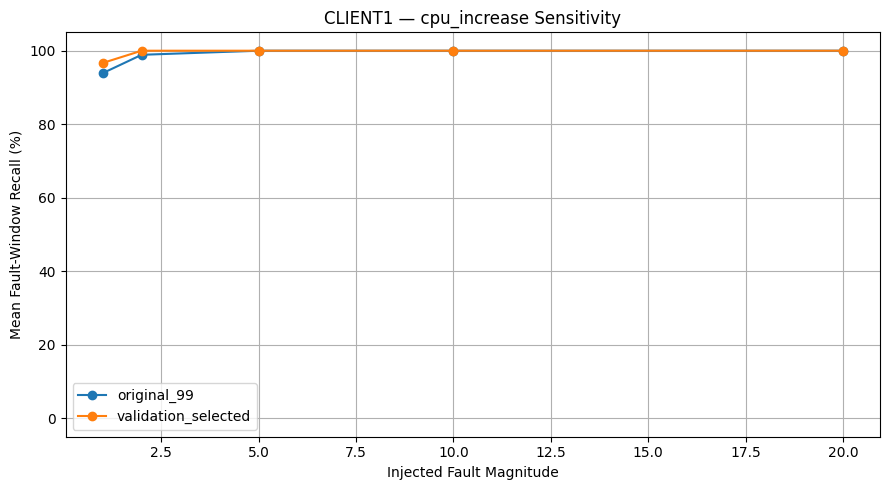

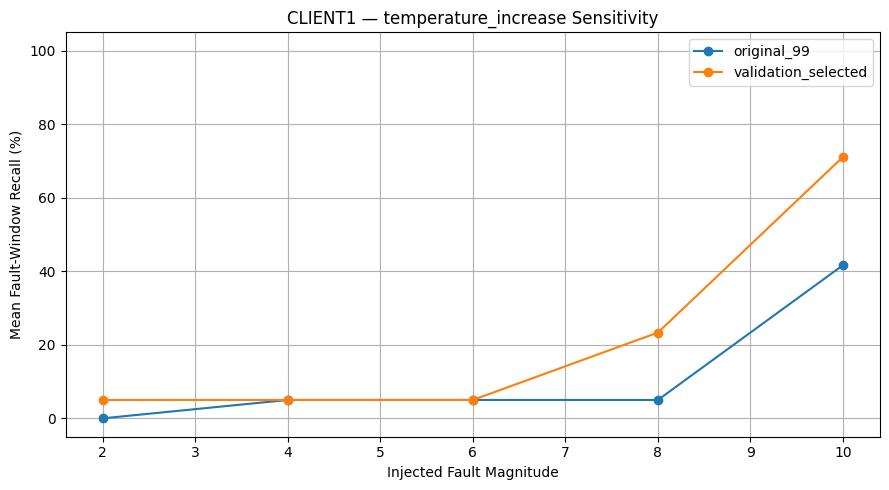

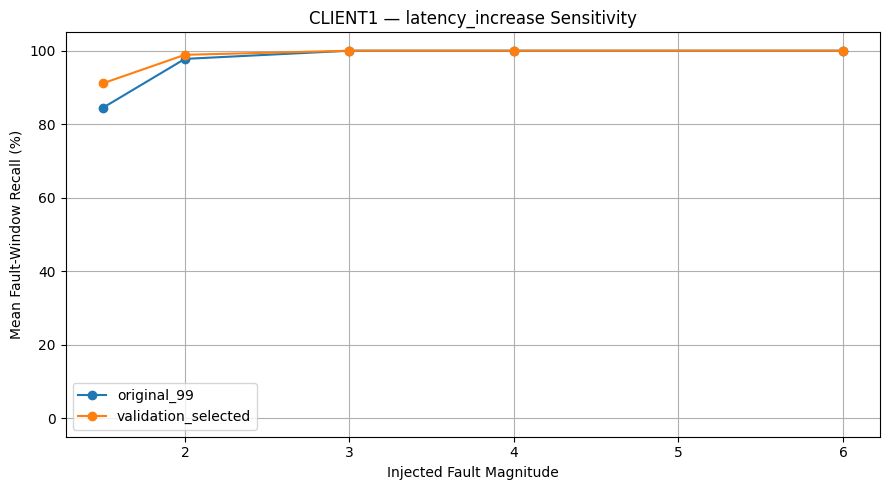

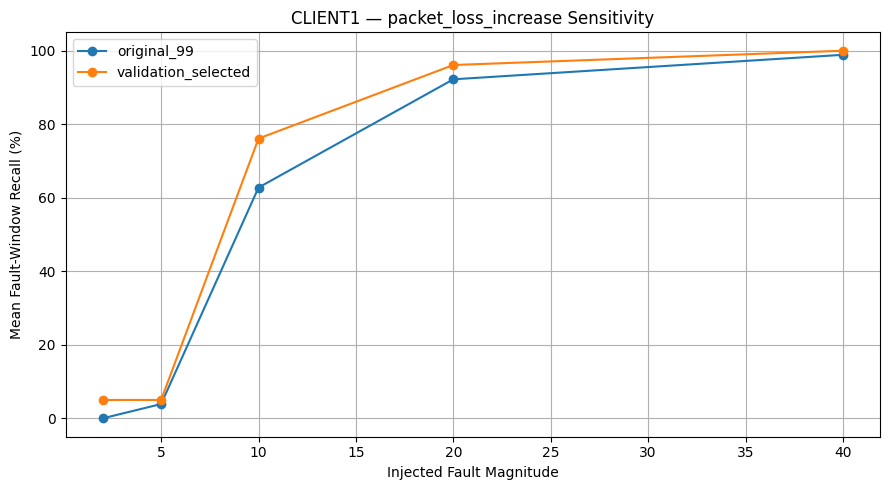

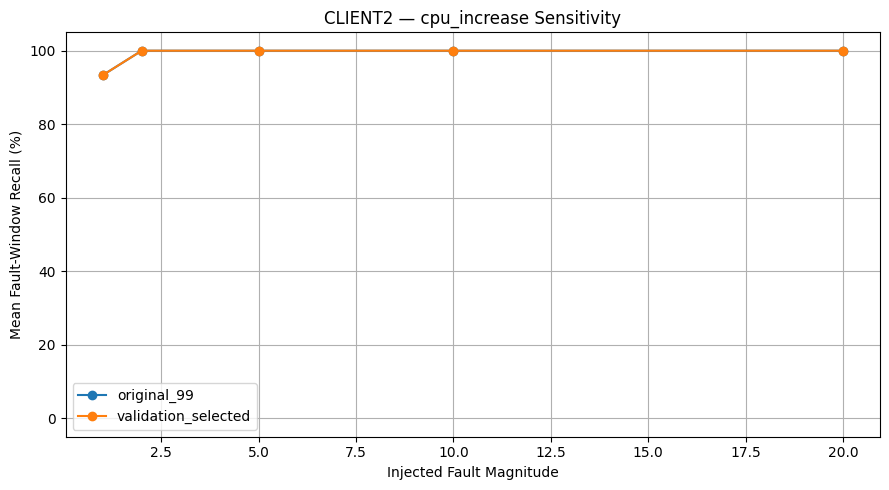

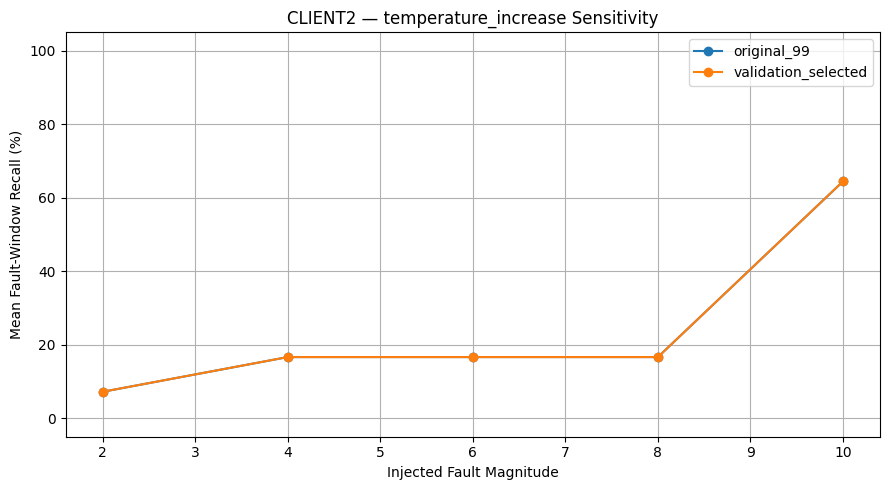

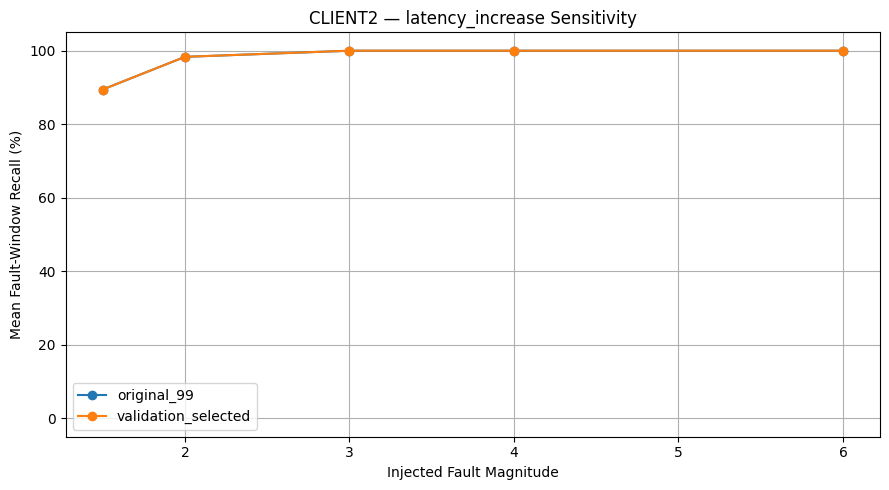

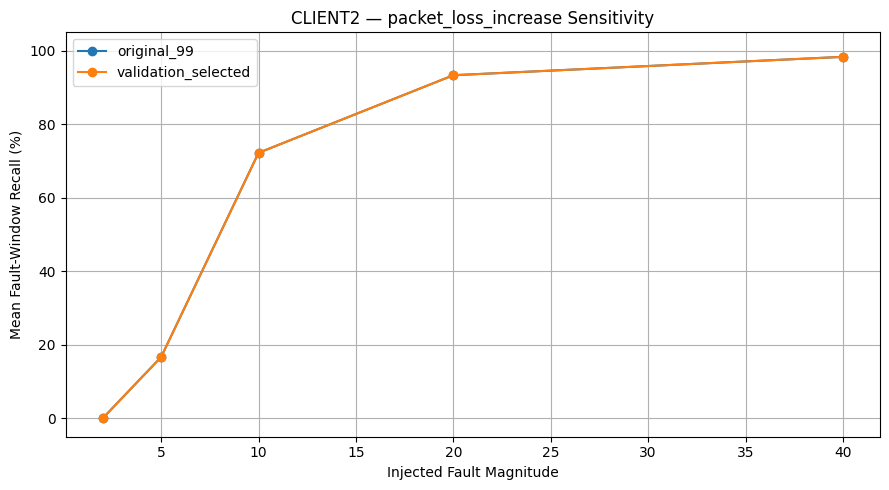

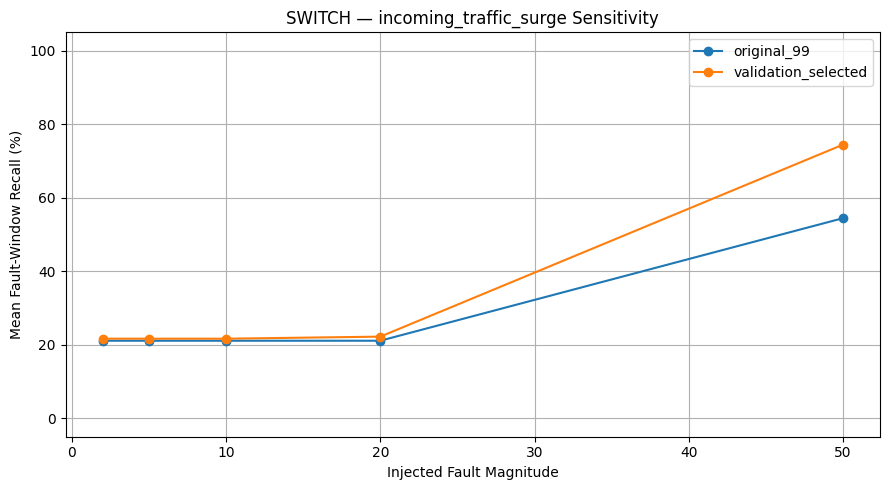

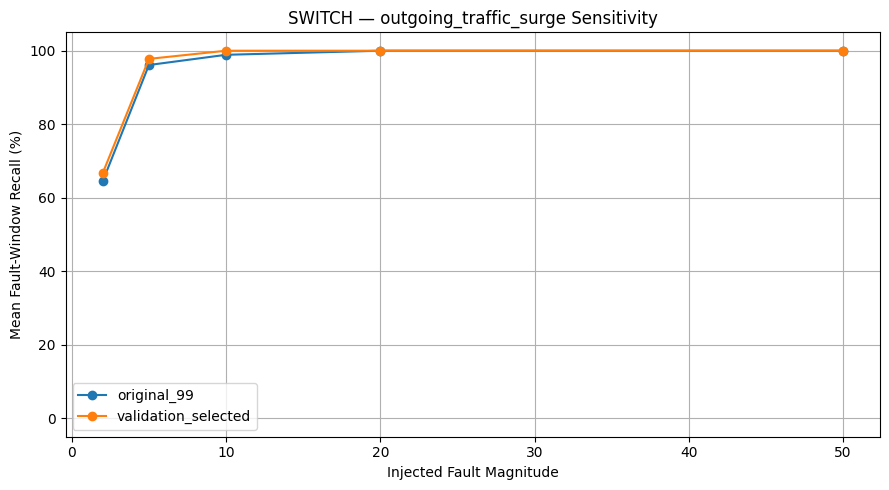

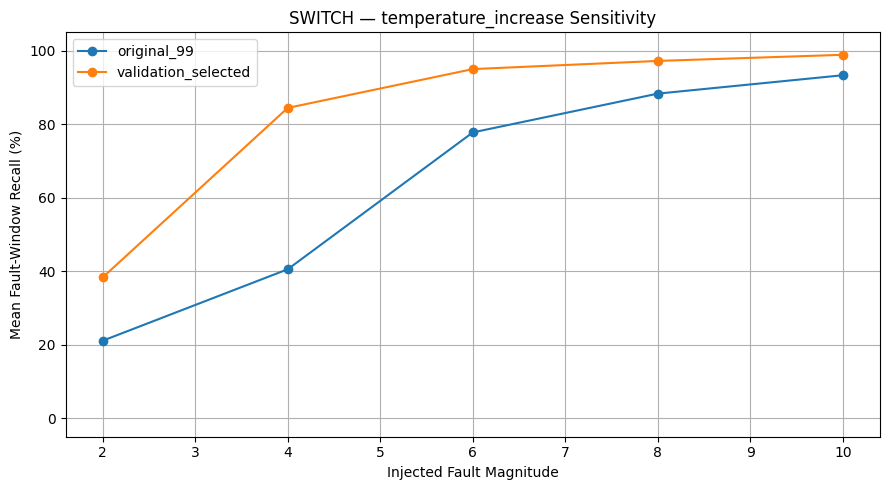

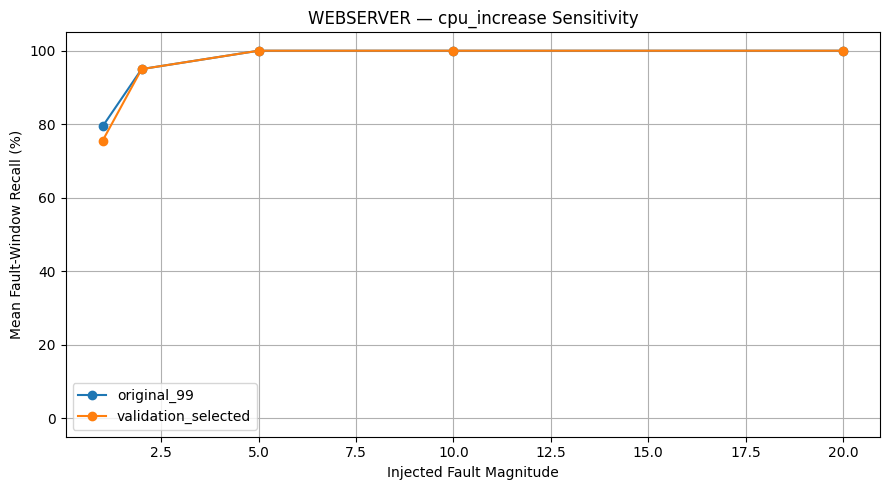

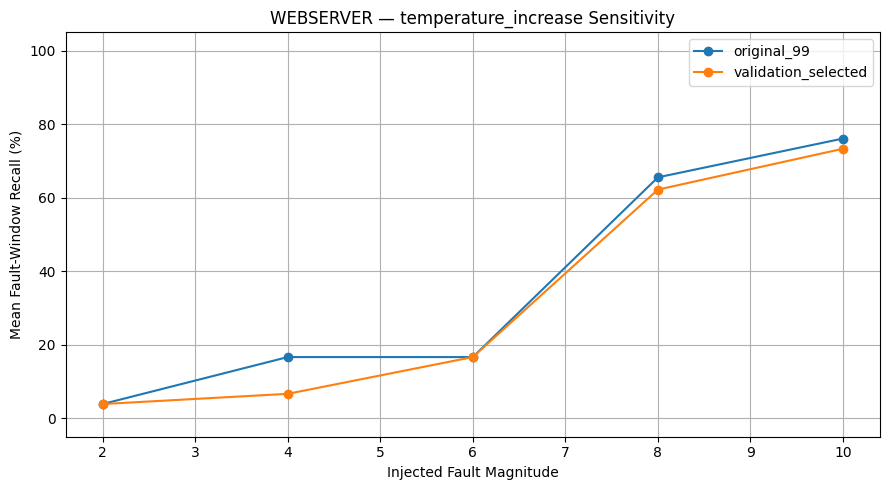

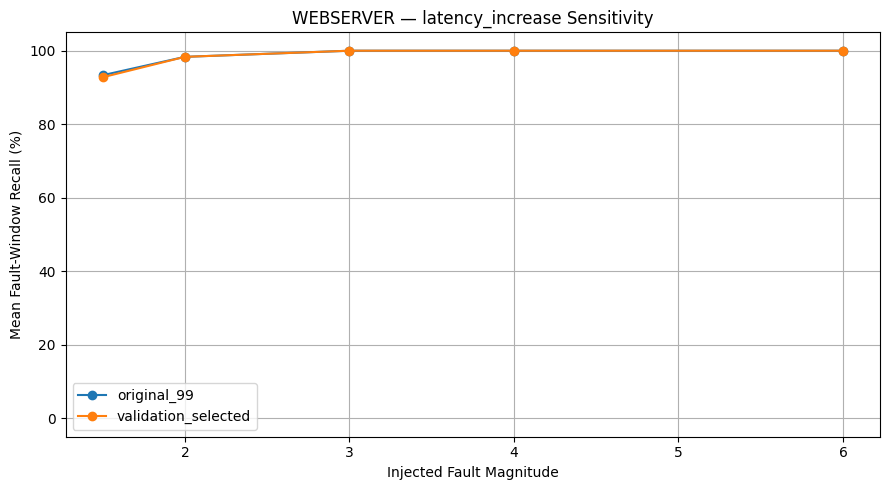

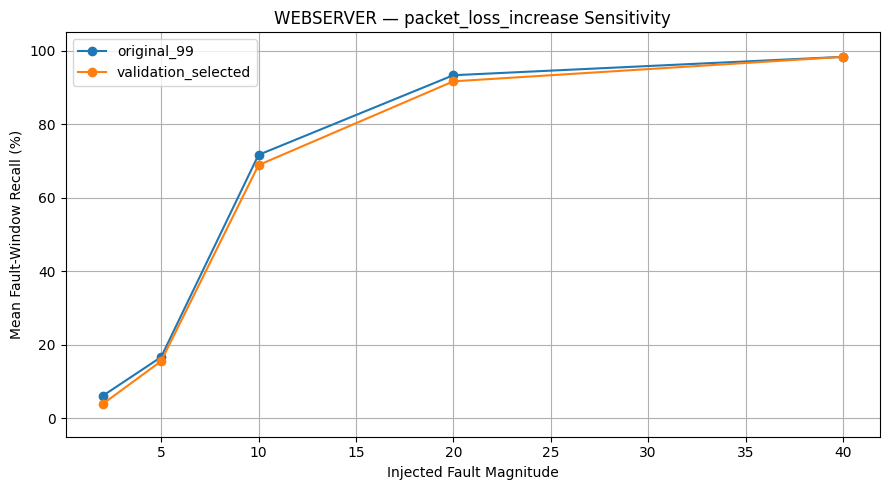


MINIMUM TESTED DETECTABLE SEVERITIES


,device,scenario,threshold_method,minimum_tested_detectable_magnitude,detected_at_all_tested_severities
0,client1,cpu_increase,original_99,1.0,True
1,client1,cpu_increase,validation_selected,1.0,True
2,client1,latency_increase,original_99,1.5,True
3,client1,latency_increase,validation_selected,1.5,True
4,client1,packet_loss_increase,original_99,10.0,False
5,client1,packet_loss_increase,validation_selected,10.0,False
6,client1,temperature_increase,original_99,10.0,False
7,client1,temperature_increase,validation_selected,10.0,False
8,client2,cpu_increase,original_99,1.0,True
9,client2,cpu_increase,validation_selected,1.0,True



Section 11 complete
Results saved to: lstm_sensitivity_analysis


In [18]:

# ============================================================
# Section 11 — Fault Sensitivity and Threshold Optimisation
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

SENSITIVITY_DIR = Path("lstm_sensitivity_analysis")
SENSITIVITY_DIR.mkdir(parents=True, exist_ok=True)

# ------------------------------------------------------------
# 11.1 Experiment configuration
# ------------------------------------------------------------

THRESHOLD_PERCENTILES = [95, 97.5, 99, 99.5]
MAX_VALIDATION_ALERT_PCT = 2.0

INJECTION_FRACTIONS = [0.25, 0.50, 0.75]
FAULT_DURATION_STEPS = 60

# Smaller/larger disturbances for all four devices
#
# Magnitudes use:
# - add: absolute increase in original metric units
# - multiply: multiplicative factor
#
# CPU and packet loss use percentage points, not fractions.

SENSITIVITY_SCENARIOS = {
    "client1": {
        "cpu_increase": {
            "metric": "cpu_pct",
            "operation": "add",
            "magnitudes": [1, 2, 5, 10, 20],
        },
        "temperature_increase": {
            "metric": "temperature_c",
            "operation": "add",
            "magnitudes": [2, 4, 6, 8, 10],
        },
        "latency_increase": {
            "metric": "latency_ms",
            "operation": "multiply",
            "magnitudes": [1.5, 2, 3, 4, 6],
        },
        "packet_loss_increase": {
            "metric": "packet_loss_pct",
            "operation": "add",
            "magnitudes": [2, 5, 10, 20, 40],
        },
    },

    "client2": {
        "cpu_increase": {
            "metric": "cpu_pct",
            "operation": "add",
            "magnitudes": [1, 2, 5, 10, 20],
        },
        "temperature_increase": {
            "metric": "temperature_c",
            "operation": "add",
            "magnitudes": [2, 4, 6, 8, 10],
        },
        "latency_increase": {
            "metric": "latency_ms",
            "operation": "multiply",
            "magnitudes": [1.5, 2, 3, 4, 6],
        },
        "packet_loss_increase": {
            "metric": "packet_loss_pct",
            "operation": "add",
            "magnitudes": [2, 5, 10, 20, 40],
        },
    },

    "switch": {
        "incoming_traffic_surge": {
            "metric": "interface_4_in_bytes_rate_Bps",
            "operation": "multiply",
            "magnitudes": [2, 5, 10, 20, 50],
        },
        "outgoing_traffic_surge": {
            "metric": "interface_4_out_bytes_rate_Bps",
            "operation": "multiply",
            "magnitudes": [2, 5, 10, 20, 50],
        },
        "temperature_increase": {
            "metric": "temperature",
            "operation": "add",
            "magnitudes": [2, 4, 6, 8, 10],
        },
    },

    "webserver": {
        "cpu_increase": {
            "metric": "cpu_pct",
            "operation": "add",
            "magnitudes": [1, 2, 5, 10, 20],
        },
        "temperature_increase": {
            "metric": "temperature_c",
            "operation": "add",
            "magnitudes": [2, 4, 6, 8, 10],
        },
        "latency_increase": {
            "metric": "latency_ms",
            "operation": "multiply",
            "magnitudes": [1.5, 2, 3, 4, 6],
        },
        "packet_loss_increase": {
            "metric": "packet_loss_pct",
            "operation": "add",
            "magnitudes": [2, 5, 10, 20, 40],
        },
    },
}

STEP = pd.Timedelta(WINDOWS[ACTIVE_WINDOW])

# Use a complete engineered-feature interval for injection.
# Each simulated fault begins at a timestamp aligned with
# the start of the corresponding resampled feature row.

np.random.seed(RANDOM_STATE)


# ------------------------------------------------------------
# 11.2 Calibrate alternative thresholds
# ------------------------------------------------------------

THRESHOLD_COMPARISON = []
SELECTED_THRESHOLDS = {}

for device_name in LSTM_MODELS:

    train_errors = np.asarray(
        RECONSTRUCTION_ERRORS[device_name]["train"]
    )

    validation_errors = np.asarray(
        RECONSTRUCTION_ERRORS[device_name]["validation"]
    )

    candidates = []

    for percentile in THRESHOLD_PERCENTILES:

        threshold = float(
            np.percentile(train_errors, percentile)
        )

        train_alert_rate = float(
            np.mean(train_errors > threshold) * 100
        )

        validation_alert_rate = float(
            np.mean(validation_errors > threshold) * 100
        )

        row = {
            "device": device_name,
            "percentile": percentile,
            "threshold": threshold,
            "train_alert_rate_pct": train_alert_rate,
            "validation_alert_rate_pct": validation_alert_rate,
        }

        THRESHOLD_COMPARISON.append(row)
        candidates.append(row)

    # Choose the most sensitive threshold satisfying
    # the validation alert-rate budget.
    #
    # IMPORTANT:
    # This is a proxy for alert frequency, NOT a
    # verified false-positive rate.

    eligible = [
        row for row in candidates
        if row["validation_alert_rate_pct"]
        <= MAX_VALIDATION_ALERT_PCT
    ]

    if eligible:
        selected = min(
            eligible,
            key=lambda row: row["threshold"]
        )
        budget_met = True
    else:
        # Fallback to least sensitive candidate.
        selected = max(
            candidates,
            key=lambda row: row["threshold"]
        )
        budget_met = False

    SELECTED_THRESHOLDS[device_name] = {
        "threshold": selected["threshold"],
        "percentile": selected["percentile"],
        "validation_alert_rate_pct":
            selected["validation_alert_rate_pct"],
        "validation_budget_met": budget_met,
    }


THRESHOLD_COMPARISON_DF = pd.DataFrame(
    THRESHOLD_COMPARISON
)

SELECTED_THRESHOLD_DF = pd.DataFrame.from_dict(
    SELECTED_THRESHOLDS,
    orient="index"
)

print("\nTHRESHOLD CALIBRATION")
display(THRESHOLD_COMPARISON_DF.round(4))

print("\nSELECTED THRESHOLDS")
display(SELECTED_THRESHOLD_DF.round(4))

THRESHOLD_COMPARISON_DF.to_csv(
    SENSITIVITY_DIR / "threshold_comparison.csv",
    index=False
)

SELECTED_THRESHOLD_DF.to_csv(
    SENSITIVITY_DIR / "selected_thresholds.csv"
)


# ------------------------------------------------------------
# 11.3 Select multiple independent injection periods
# ------------------------------------------------------------

INJECTION_PERIODS = {}

# The fault injection periods are selected without looking
# at anomaly scores or fault detection results.

for device_name in SENSITIVITY_SCENARIOS:

    timestamps = pd.DatetimeIndex(
        SPLIT_DATA[device_name]["test_times"]
    )

    required_history = SEQUENCE_LENGTH - 1

    valid_starts = []

    for i in range(
        required_history,
        len(timestamps) - FAULT_DURATION_STEPS + 1
    ):

        segment = timestamps[
            i - required_history:
            i + FAULT_DURATION_STEPS
        ]

        if (
            segment.to_series()
            .diff()
            .dropna()
            .eq(STEP)
            .all()
        ):
            valid_starts.append(i)

    if not valid_starts:
        raise ValueError(
            f"No suitable injection period: {device_name}"
        )

    # Select three periods distributed across test time.
    chosen_starts = []

    for fraction in INJECTION_FRACTIONS:

        target = int(len(timestamps) * fraction)

        ranked = sorted(
            valid_starts,
            key=lambda i: abs(i - target)
        )

        # Avoid overlapping injection periods and
        # their adjacent lookback/recovery windows.
        min_separation = (
            FAULT_DURATION_STEPS
            + 2 * SEQUENCE_LENGTH
        )

        selected_start = next(
            (
                i for i in ranked
                if all(
                    abs(i - previous) >= min_separation
                    for previous in chosen_starts
                )
            ),
            None
        )

        if selected_start is None:
            raise ValueError(
                f"Cannot select independent periods "
                f"for {device_name}"
            )

        chosen_starts.append(selected_start)

    INJECTION_PERIODS[device_name] = []

    for period_id, start_index in enumerate(
        sorted(chosen_starts),
        start=1
    ):

        end_index = (
            start_index + FAULT_DURATION_STEPS - 1
        )

        INJECTION_PERIODS[device_name].append({
            "period_id": period_id,
            "start_index": start_index,
            "end_index": end_index,
            "start": timestamps[start_index],
            "end": timestamps[end_index],
        })

    print(f"\n{device_name.upper()} injection periods:")

    for period in INJECTION_PERIODS[device_name]:
        print(
            period["period_id"],
            period["start"],
            "to",
            period["end"]
        )


# ------------------------------------------------------------
# 11.4 Prepare reference test sequences
# ------------------------------------------------------------

TEST_REFERENCE = {}

for device_name in SENSITIVITY_SCENARIOS:

    test_scaled = np.asarray(
        SPLIT_DATA[device_name]["test"],
        dtype=np.float32
    )

    timestamps = pd.DatetimeIndex(
        SPLIT_DATA[device_name]["test_times"]
    )

    X_base, sequence_times = create_sequences(
        test_scaled,
        timestamps,
        SEQUENCE_LENGTH,
        SEQUENCE_STRIDE
    )

    sequence_times = pd.DatetimeIndex(sequence_times)

    baseline_results = (
        ANOMALY_RESULTS[device_name]["test"]
        .reindex(sequence_times)
    )

    if baseline_results[
        "reconstruction_error"
    ].isna().any():
        raise ValueError(
            f"Baseline alignment failed for {device_name}"
        )

    TEST_REFERENCE[device_name] = {
        "X_base": X_base,
        "sequence_times": sequence_times,
        "baseline_errors": baseline_results[
            "reconstruction_error"
        ].to_numpy(dtype=float),
        "timestamps": timestamps,
        "test_scaled": test_scaled,
    }


# ------------------------------------------------------------
# 11.5 Evaluate fault sensitivity
# ------------------------------------------------------------

SENSITIVITY_RESULTS = []

# Total experiments:
# 15 scenarios x 5 severities x 3 periods = 225
#
# Only fault-affected windows are reconstructed.
# Outside those windows, the original baseline
# reconstruction errors are reused.

for device_name, scenarios in SENSITIVITY_SCENARIOS.items():

    print(f"\n{'=' * 65}")
    print(f"SENSITIVITY ANALYSIS — {device_name.upper()}")
    print(f"{'=' * 65}")

    model = LSTM_MODELS[device_name]
    scaler = SCALERS[device_name]
    feature_columns = list(
        FEATURE_COLUMNS[device_name]
    )

    reference = TEST_REFERENCE[device_name]

    X_base = reference["X_base"]
    sequence_times = reference["sequence_times"]

    original_scaled = reference["test_scaled"]
    timestamps = reference["timestamps"]

    baseline_errors = reference["baseline_errors"]

    thresholds = {
        "original_99": float(
            ANOMALY_THRESHOLDS[device_name]
        ),
        "validation_selected": float(
            SELECTED_THRESHOLDS[device_name]["threshold"]
        ),
    }

    for scenario_name, config in scenarios.items():

        metric = config["metric"]
        operation = config["operation"]

        print(f"\nScenario: {scenario_name}")

        for magnitude in config["magnitudes"]:

            for period in INJECTION_PERIODS[device_name]:

                start_time = period["start"]
                end_time = period["end"]

                injection_mask = (
                    (timestamps >= start_time) &
                    (timestamps <= end_time)
                )

                # Inject into a fresh copy of original test data.
                modified_scaled, modified_features = inject_fault(
                    original_scaled.copy(),
                    scaler,
                    feature_columns,
                    metric,
                    operation,
                    magnitude,
                    injection_mask
                )

                # Build all sequences, maintaining exact
                # original Section 5 timestamp behaviour.
                X_fault, fault_times = create_sequences(
                    modified_scaled,
                    timestamps,
                    SEQUENCE_LENGTH,
                    SEQUENCE_STRIDE
                )

                fault_times = pd.DatetimeIndex(
                    fault_times
                )

                if not fault_times.equals(sequence_times):
                    raise ValueError(
                        "Injection changed sequence alignment."
                    )

                # Any sequence ending from fault onset
                # through the lookback tail may contain
                # at least one modified feature row.
                contamination_end = (
                    end_time
                    + (SEQUENCE_LENGTH - 1) * STEP
                )

                affected_mask = (
                    (sequence_times >= start_time) &
                    (sequence_times <= contamination_end)
                )

                # Only predict the changed windows.
                affected_errors, _ = evaluate_sequences(
                    model,
                    X_fault[affected_mask],
                    threshold=float(
                        ANOMALY_THRESHOLDS[device_name]
                    )
                )

                # Reuse original model errors elsewhere.
                all_errors = baseline_errors.copy()
                all_errors[affected_mask] = affected_errors

                # Count fault-active windows.
                fault_active = (
                    (sequence_times >= start_time) &
                    (sequence_times <= end_time)
                )

                # Exclude post-fault contamination
                # from the clean control interval.
                clean_control = (
                    (sequence_times < start_time) |
                    (sequence_times > contamination_end)
                )

                for threshold_name, threshold in thresholds.items():

                    predictions = all_errors > threshold

                    tp = int(
                        np.sum(predictions & fault_active)
                    )

                    fn = int(
                        np.sum(~predictions & fault_active)
                    )

                    fp = int(
                        np.sum(predictions & clean_control)
                    )

                    tn = int(
                        np.sum(~predictions & clean_control)
                    )

                    recall = (
                        tp / (tp + fn)
                        if tp + fn else np.nan
                    )

                    control_alert_rate = (
                        fp / (fp + tn)
                        if fp + tn else np.nan
                    )

                    baseline_predictions = (
                        baseline_errors > threshold
                    )

                    newly_detected = (
                        predictions &
                        ~baseline_predictions &
                        fault_active
                    )

                    incremental_recall = (
                        np.sum(newly_detected) /
                        np.sum(fault_active)
                        if np.sum(fault_active)
                        else np.nan
                    )

                    detected_times = sequence_times[
                        fault_active & predictions
                    ]

                    if len(detected_times):
                        delay = (
                            detected_times.min() - start_time
                        ).total_seconds() / 60
                    else:
                        delay = np.nan

                    # A detection is attributable to injection
                    # when it was absent in the unmodified
                    # baseline at that timestamp.
                    new_detection_times = sequence_times[
                        newly_detected
                    ]

                    if len(new_detection_times):
                        incremental_delay = (
                            new_detection_times.min()
                            - start_time
                        ).total_seconds() / 60
                    else:
                        incremental_delay = np.nan

                    SENSITIVITY_RESULTS.append({
                        "device": device_name,
                        "scenario": scenario_name,
                        "magnitude": magnitude,
                        "period_id": period["period_id"],
                        "fault_start": start_time,
                        "threshold_method": threshold_name,
                        "threshold": threshold,
                        "TP": tp,
                        "FN": fn,
                        "FP": fp,
                        "TN": tn,
                        "recall_pct": recall * 100,
                        "incremental_recall_pct":
                            incremental_recall * 100,
                        "control_alert_rate_pct":
                            control_alert_rate * 100,
                        "event_detected": bool(tp > 0),
                        "incremental_event_detected":
                            bool(newly_detected.any()),
                        "detection_delay_minutes": delay,
                        "incremental_detection_delay_minutes":
                            incremental_delay,
                    })

            print(f"  Completed severity: {magnitude}")


# ------------------------------------------------------------
# 11.6 Aggregate results across injection periods
# ------------------------------------------------------------

SENSITIVITY_DF = pd.DataFrame(
    SENSITIVITY_RESULTS
)

SENSITIVITY_DF.to_csv(
    SENSITIVITY_DIR / "all_sensitivity_results.csv",
    index=False
)

SENSITIVITY_AGGREGATE = (
    SENSITIVITY_DF
    .groupby([
        "device",
        "scenario",
        "magnitude",
        "threshold_method"
    ])
    .agg(
        mean_recall_pct=("recall_pct", "mean"),
        min_recall_pct=("recall_pct", "min"),
        mean_incremental_recall_pct=(
            "incremental_recall_pct", "mean"
        ),
        event_detection_rate_pct=(
            "event_detected",
            lambda x: 100 * x.mean()
        ),
        incremental_event_detection_rate_pct=(
            "incremental_event_detected",
            lambda x: 100 * x.mean()
        ),
        mean_control_alert_rate_pct=(
            "control_alert_rate_pct", "mean"
        ),
        mean_detection_delay_minutes=(
            "detection_delay_minutes", "mean"
        ),
        mean_incremental_delay_minutes=(
            "incremental_detection_delay_minutes",
            "mean"
        ),
    )
    .reset_index()
)

print("\nSENSITIVITY RESULTS")
display(SENSITIVITY_AGGREGATE.round(2))

SENSITIVITY_AGGREGATE.to_csv(
    SENSITIVITY_DIR / "sensitivity_aggregate.csv",
    index=False
)


# ------------------------------------------------------------
# 11.7 Compare original and selected thresholds
# ------------------------------------------------------------

THRESHOLD_EVALUATION = (
    SENSITIVITY_DF
    .groupby([
        "device",
        "threshold_method"
    ])
    .agg(
        mean_recall_pct=("recall_pct", "mean"),
        mean_incremental_recall_pct=(
            "incremental_recall_pct", "mean"
        ),
        event_detection_rate_pct=(
            "event_detected",
            lambda x: 100 * x.mean()
        ),
        mean_control_alert_rate_pct=(
            "control_alert_rate_pct", "mean"
        ),
    )
    .reset_index()
)

print("\nTHRESHOLD PERFORMANCE COMPARISON")
display(THRESHOLD_EVALUATION.round(2))

THRESHOLD_EVALUATION.to_csv(
    SENSITIVITY_DIR / "threshold_performance.csv",
    index=False
)


# ------------------------------------------------------------
# 11.8 Plot sensitivity curves
# ------------------------------------------------------------

for device_name, scenarios in SENSITIVITY_SCENARIOS.items():

    for scenario_name in scenarios:

        subset = SENSITIVITY_AGGREGATE[
            (SENSITIVITY_AGGREGATE["device"]
             == device_name) &
            (SENSITIVITY_AGGREGATE["scenario"]
             == scenario_name)
        ]

        plt.figure(figsize=(9, 5))

        for method in [
            "original_99",
            "validation_selected"
        ]:

            curve = subset[
                subset["threshold_method"] == method
            ].sort_values("magnitude")

            plt.plot(
                curve["magnitude"],
                curve["mean_recall_pct"],
                marker="o",
                label=method
            )

        plt.title(
            f"{device_name.upper()} — "
            f"{scenario_name} Sensitivity"
        )

        plt.xlabel("Injected Fault Magnitude")
        plt.ylabel("Mean Fault-Window Recall (%)")

        plt.ylim(-5, 105)
        plt.grid(True)
        plt.legend()
        plt.tight_layout()

        plt.savefig(
            SENSITIVITY_DIR /
            f"{device_name}_{scenario_name}_sensitivity.png",
            dpi=150
        )

        plt.show()


# ------------------------------------------------------------
# 11.9 Identify minimum tested detectable severity
# ------------------------------------------------------------

# "Detectable" means at least one NEW alert in every
# one of the three injection experiments.
#
# This is an experimental criterion, not a physical
# equipment failure threshold.

DETECTION_LIMITS = []

for (
    device_name,
    scenario_name,
    threshold_method
), group in SENSITIVITY_DF.groupby([
    "device",
    "scenario",
    "threshold_method"
]):

    severity_summary = (
        group.groupby("magnitude")
        ["incremental_event_detected"]
        .all()
        .sort_index()
    )

    detected = severity_summary[
        severity_summary
    ]

    minimum_detectable = (
        float(detected.index.min())
        if not detected.empty
        else np.nan
    )

    DETECTION_LIMITS.append({
        "device": device_name,
        "scenario": scenario_name,
        "threshold_method": threshold_method,
        "minimum_tested_detectable_magnitude":
            minimum_detectable,
        "detected_at_all_tested_severities":
            bool(severity_summary.all()),
    })


DETECTION_LIMITS_DF = pd.DataFrame(
    DETECTION_LIMITS
)

print("\nMINIMUM TESTED DETECTABLE SEVERITIES")
display(DETECTION_LIMITS_DF)

DETECTION_LIMITS_DF.to_csv(
    SENSITIVITY_DIR / "detection_limits.csv",
    index=False
)

print("\nSection 11 complete")
print(f"Results saved to: {SENSITIVITY_DIR}")



Processing CLIENT1
  train: (11943, 39)
  validation: (2536, 39)
  test: (2538, 39)

Processing CLIENT2
  train: (11907, 39)
  validation: (2530, 39)
  test: (2532, 39)

Processing SWITCH
  train: (11154, 60)
  validation: (2367, 60)
  test: (2368, 60)

Processing WEBSERVER
  train: (11168, 39)
  validation: (2370, 39)
  test: (2372, 39)

CLIENT1 — Highest-error features


,device,feature,train_mean_error,test_mean_error,train_error_share_pct,test_to_train_ratio
14,client1,temperature_c_std,0.9827,0.9504,5.2922,0.9671
27,client1,throughput_bytes_per_sec_mean,0.9822,1.0142,5.2895,1.0325
2,client1,latency_ms_std,0.9819,0.8961,5.2878,0.9126
29,client1,throughput_bytes_per_sec_std,0.9807,0.9914,5.2810,1.0109
28,client1,throughput_bytes_per_sec_max,0.9774,0.9817,5.2634,1.0044
11,client1,disk_usage_pct_std,0.9698,0.0005,5.2225,0.0006
1,client1,latency_ms_max,0.9328,1.0263,5.0231,1.1003
0,client1,latency_ms_mean,0.9131,0.9996,4.9174,1.0947
23,client1,est_power_draw_w_std,0.8613,0.8324,4.6384,0.9664
21,client1,est_power_draw_w_mean,0.8600,0.8040,4.6313,0.9349



CLIENT2 — Highest-error features


,device,feature,train_mean_error,test_mean_error,train_error_share_pct,test_to_train_ratio
53,client2,temperature_c_std,0.9951,0.9760,6.2455,0.9808
50,client2,disk_usage_pct_std,0.9936,2.3613,6.2359,2.3765
66,client2,throughput_bytes_per_sec_mean,0.9910,0.9973,6.2193,1.0064
41,client2,latency_ms_std,0.9839,1.2419,6.1748,1.2623
68,client2,throughput_bytes_per_sec_std,0.9787,0.9857,6.1420,1.0072
67,client2,throughput_bytes_per_sec_max,0.9755,0.9964,6.1224,1.0214
39,client2,latency_ms_mean,0.9324,1.0955,5.8519,1.1749
58,client2,cpu_clock_mhz_max,0.9266,0.9663,5.8156,1.0428
57,client2,cpu_clock_mhz_mean,0.9261,0.8245,5.8121,0.8903
59,client2,cpu_clock_mhz_std,0.9258,0.8973,5.8105,0.9692



SWITCH — Highest-error features


...

,device,global_mse_alert_rate_pct,feature_aware_alert_rate_pct,global_mse_alerts,feature_aware_alerts
0,client1,0.000,3.231,0,82
1,client2,2.133,1.777,54,45
2,switch,6.672,11.613,158,275
3,webserver,0.295,1.265,7,30


C:\Users\alwyn\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCache\local-packages\Python312\site-packages\sklearn\utils\validation.py:2691: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(
C:\Users\alwyn\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCache\local-packages\Python312\site-packages\sklearn\utils\validation.py:2691: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(
C:\Users\alwyn\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCache\local-packages\Python312\site-packages\sklearn\utils\validation.py:2691: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(
C:\Users\alwyn\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCache\local-packages\Python312\site-pac


FAULT DETECTION COMPARISON


C:\Users\alwyn\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCache\local-packages\Python312\site-packages\sklearn\utils\validation.py:2691: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(
C:\Users\alwyn\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCache\local-packages\Python312\site-packages\sklearn\utils\validation.py:2691: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(


,device,scenario,method,mean_recall_pct,mean_incremental_recall_pct,event_detection_rate_pct,incremental_event_detection_rate_pct,mean_delay_minutes
0,client1,packet_loss_increase,feature_aware,97.44,96.89,100.00,100.00,1.27
1,client1,packet_loss_increase,global_mse,51.56,51.56,66.67,66.67,13.20
2,client1,temperature_increase,feature_aware,4.56,4.00,60.00,26.67,23.78
3,client1,temperature_increase,global_mse,11.33,11.33,40.00,40.00,43.00
4,client2,packet_loss_increase,feature_aware,100.00,97.22,100.00,100.00,0.00
5,client2,packet_loss_increase,global_mse,56.11,53.44,66.67,66.67,8.40
6,client2,temperature_increase,feature_aware,36.44,33.67,60.00,60.00,19.00
7,client2,temperature_increase,global_mse,24.33,21.00,46.67,46.67,22.43
8,switch,incoming_traffic_surge,feature_aware,34.56,15.67,46.67,46.67,15.43
9,switch,incoming_traffic_surge,global_mse,27.78,6.67,46.67,20.00,24.29


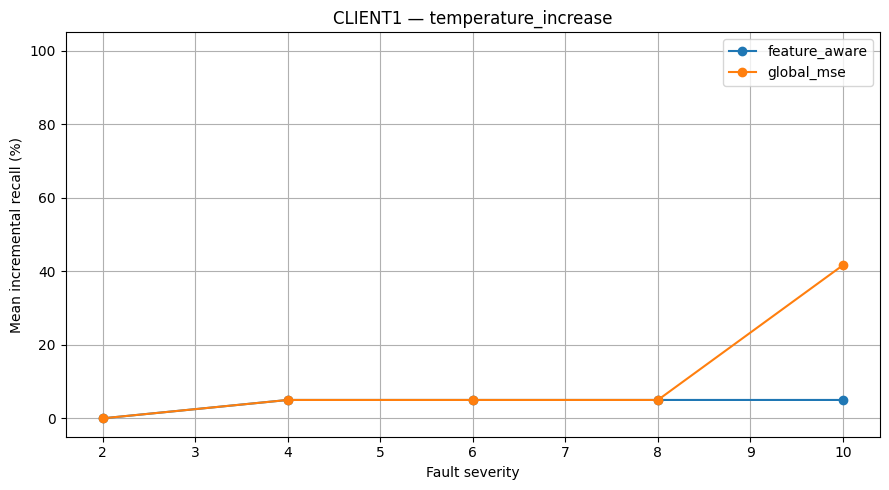

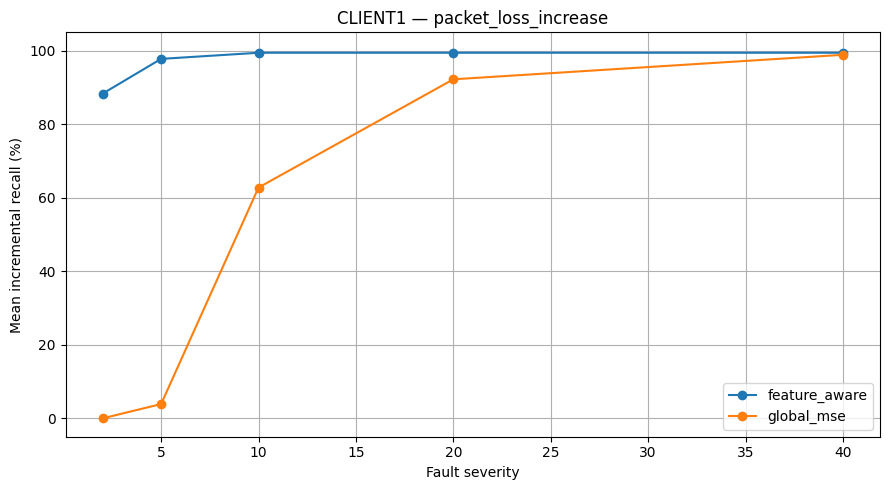

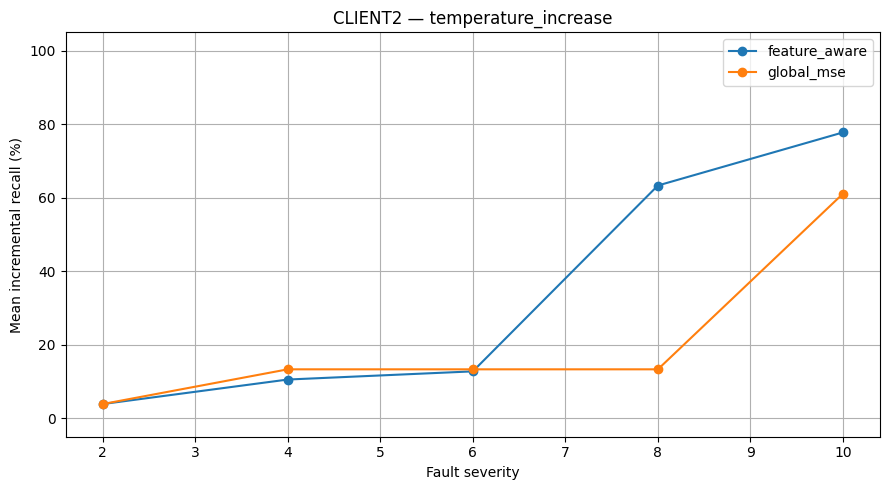

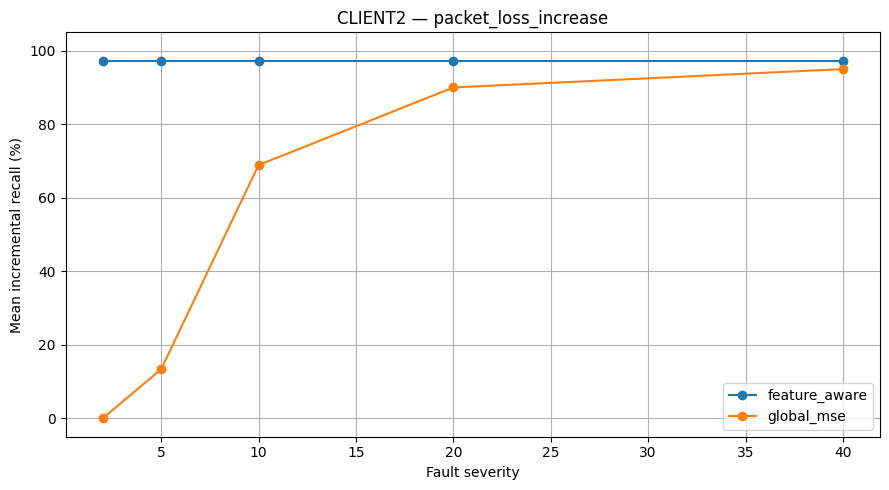

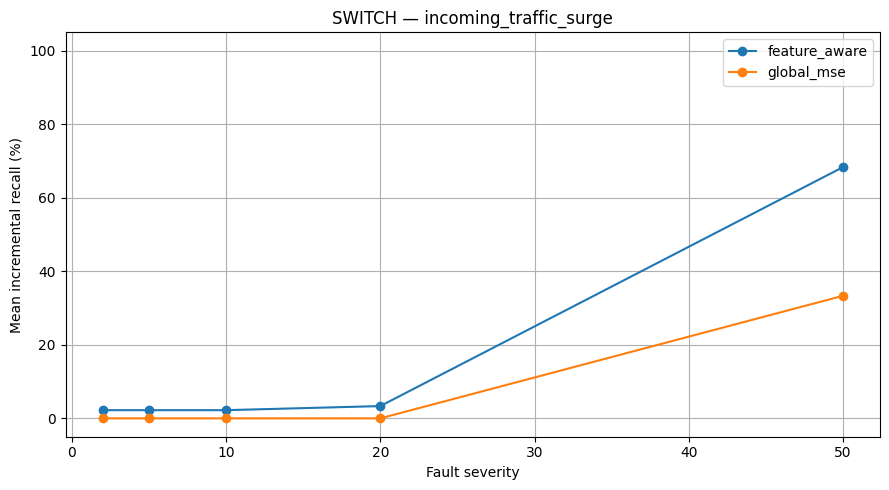

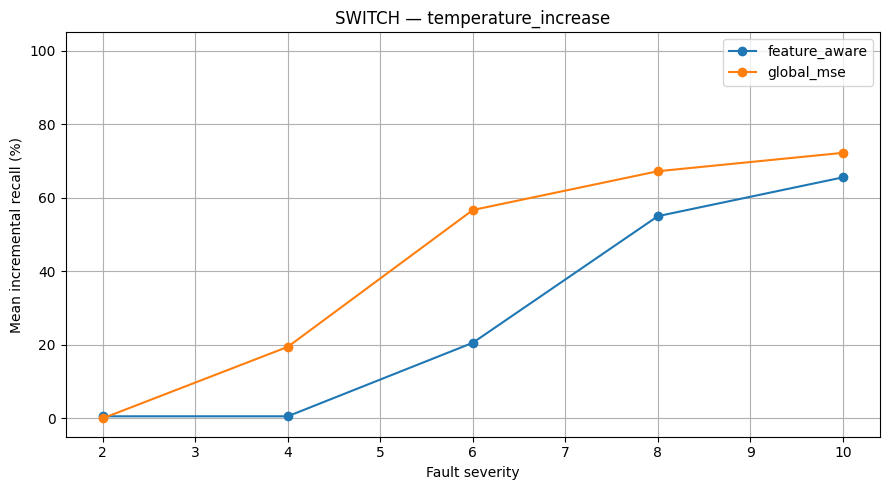

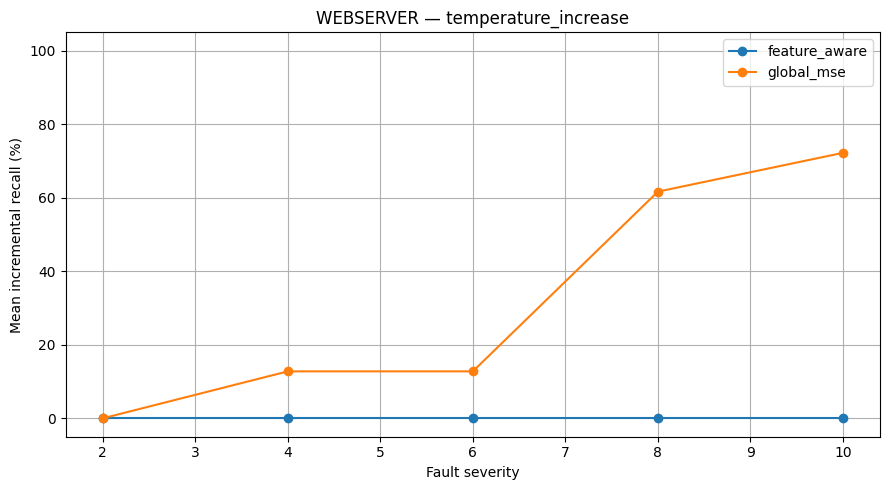


Section 12 complete
Results saved to: lstm_contamination_aware


In [19]:

# ============================================================
# SECTION 12 — CONTAMINATION-AWARE ANOMALY DETECTION
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib

from pathlib import Path

SECTION12_DIR = Path("lstm_contamination_aware")
SECTION12_DIR.mkdir(parents=True, exist_ok=True)

# ------------------------------------------------------------
# 12.1 Configuration
# ------------------------------------------------------------

THRESHOLD_PERCENTILES_12 = [95, 97.5, 99, 99.5]
MAX_VALIDATION_ALERT_PCT_12 = 2.0

# Prevent division by nearly zero MAD values.
# A dimension-specific fallback uses the training IQR.
ROBUST_SCALE_FLOOR_12 = 0.10

# Reuse the exploratory injection periods from Section 11.
# Test results must NOT be used to calibrate thresholds.
TARGET_SCENARIOS_12 = {
    "client1": ["temperature_increase", "packet_loss_increase"],
    "client2": ["temperature_increase", "packet_loss_increase"],
    "switch": [
        "incoming_traffic_surge",
        "temperature_increase"
    ],
    "webserver": ["temperature_increase"]
}

FEATURE_ERROR_DATA_12 = {}
FEATURE_CALIBRATION_12 = {}
METRIC_GROUPS_12 = {}
METRIC_ERROR_DATA_12 = {}
FEATURE_AWARE_SCORES_12 = {}

FEATURE_ANALYSIS_ROWS_12 = []
THRESHOLD_ROWS_12 = []
SELECTED_THRESHOLDS_12 = {}
TEST_COMPARISON_ROWS_12 = []
FAULT_COMPARISON_ROWS_12 = []


# ------------------------------------------------------------
# 12.2 Calculate reconstruction error for each feature
# ------------------------------------------------------------

def feature_reconstruction_errors_12(model, sequences):
    """
    Calculate mean squared reconstruction error across
    timesteps, separately for every engineered feature.

    Input:  (samples, timesteps, features)
    Output: (samples, features)
    """

    reconstructed = model.predict(
        sequences,
        batch_size=BATCH_SIZE,
        verbose=0
    )

    return np.mean(
        (
            sequences.astype(np.float64)
            - reconstructed.astype(np.float64)
        ) ** 2,
        axis=1
    )


for device_name, model in LSTM_MODELS.items():

    print(f"\nProcessing {device_name.upper()}")

    FEATURE_ERROR_DATA_12[device_name] = {}

    for split_name in ["train", "validation", "test"]:

        X = LSTM_SEQUENCES[device_name][split_name]

        errors = feature_reconstruction_errors_12(
            model, X
        )

        FEATURE_ERROR_DATA_12[device_name][split_name] = errors

        print(
            f"  {split_name}: {errors.shape}"
        )


# ------------------------------------------------------------
# 12.3 Diagnose feature-level reconstruction errors
# ------------------------------------------------------------

for device_name in LSTM_MODELS:

    train_errors = FEATURE_ERROR_DATA_12[
        device_name
    ]["train"]

    test_errors = FEATURE_ERROR_DATA_12[
        device_name
    ]["test"]

    train_means = train_errors.mean(axis=0)
    test_means = test_errors.mean(axis=0)

    train_total = max(train_means.sum(), 1e-12)

    for i, feature in enumerate(
        FEATURE_COLUMNS[device_name]
    ):

        FEATURE_ANALYSIS_ROWS_12.append({
            "device": device_name,
            "feature": feature,
            "train_mean_error": train_means[i],
            "test_mean_error": test_means[i],
            "train_error_share_pct":
                100 * train_means[i] / train_total,
            "test_to_train_ratio":
                test_means[i] / max(train_means[i], 1e-12),
        })


FEATURE_ANALYSIS_DF_12 = pd.DataFrame(
    FEATURE_ANALYSIS_ROWS_12
)

for device_name in LSTM_MODELS:

    subset = FEATURE_ANALYSIS_DF_12[
        FEATURE_ANALYSIS_DF_12["device"] == device_name
    ]

    print(f"\n{device_name.upper()} — Highest-error features")

    display(
        subset.nlargest(
            12, "train_mean_error"
        ).round(4)
    )

FEATURE_ANALYSIS_DF_12.to_csv(
    SECTION12_DIR / "feature_error_analysis.csv",
    index=False
)


# ------------------------------------------------------------
# 12.4 Create metric groups
# ------------------------------------------------------------

def get_metric_name_12(feature):
    """
    Map engineered features to their original metric.

    Example:
        temperature_c_mean -> temperature_c
        temperature_c_max  -> temperature_c
        temperature_c_std  -> temperature_c
    """

    for suffix in ["_mean", "_max", "_std", "_reset"]:
        if feature.endswith(suffix):
            return feature[:-len(suffix)]

    return feature


for device_name in LSTM_MODELS:

    groups = {}

    for i, feature in enumerate(
        FEATURE_COLUMNS[device_name]
    ):

        metric = get_metric_name_12(feature)

        groups.setdefault(metric, []).append(i)

    METRIC_GROUPS_12[device_name] = groups

    print(
        f"{device_name.upper()}: "
        f"{len(groups)} metric groups"
    )


# ------------------------------------------------------------
# 12.5 Fit robust calibration using TRAINING errors
# ------------------------------------------------------------

def fit_robust_calibration_12(errors):
    """
    Fit robust residual statistics per engineered feature.

    The median estimates typical reconstruction error.
    MAD describes dispersion around that median.

    IQR fallback prevents zero-MAD features from having
    unstable or infinite anomaly scores.
    """

    median = np.median(errors, axis=0)

    absolute_deviation = np.abs(
        errors - median
    )

    mad = np.median(
        absolute_deviation,
        axis=0
    )

    robust_scale = 1.4826 * mad

    q25 = np.percentile(errors, 25, axis=0)
    q75 = np.percentile(errors, 75, axis=0)

    iqr_scale = (q75 - q25) / 1.349

    scale = np.maximum(
        robust_scale,
        ROBUST_SCALE_FLOOR_12 * iqr_scale
    )

    # Final numerical floor for constant features.
    scale = np.maximum(scale, 1e-6)

    return {
        "median": median,
        "scale": scale
    }


for device_name in LSTM_MODELS:

    FEATURE_CALIBRATION_12[device_name] = (
        fit_robust_calibration_12(
            FEATURE_ERROR_DATA_12[device_name]["train"]
        )
    )


# ------------------------------------------------------------
# 12.6 Calculate metric-aware anomaly scores
# ------------------------------------------------------------

def calculate_feature_aware_score_12(
    feature_errors,
    calibration,
    metric_groups
):
    """
    Step 1: Compare feature reconstruction errors with
            their own training error distributions.

    Step 2: Average scores within each raw metric.

    Step 3: Use the maximum metric score as the
            sequence-level anomaly score.

    Only positive departures are counted.
    """

    median = calibration["median"]
    scale = calibration["scale"]

    # Robust positive deviations from typical errors.
    normalized = np.maximum(
        (feature_errors - median) / scale,
        0.0
    )

    metric_names = list(metric_groups.keys())

    metric_scores = np.column_stack([
        normalized[:, metric_groups[metric]].mean(axis=1)
        for metric in metric_names
    ])

    sequence_scores = metric_scores.max(axis=1)

    dominant_indices = metric_scores.argmax(axis=1)

    dominant_metrics = np.array(metric_names)[
        dominant_indices
    ]

    return (
        sequence_scores,
        metric_scores,
        dominant_metrics
    )


for device_name in LSTM_MODELS:

    FEATURE_AWARE_SCORES_12[device_name] = {}
    METRIC_ERROR_DATA_12[device_name] = {}

    for split_name in ["train", "validation", "test"]:

        feature_errors = FEATURE_ERROR_DATA_12[
            device_name
        ][split_name]

        scores, metric_scores, dominant_metrics = (
            calculate_feature_aware_score_12(
                feature_errors,
                FEATURE_CALIBRATION_12[device_name],
                METRIC_GROUPS_12[device_name]
            )
        )

        FEATURE_AWARE_SCORES_12[
            device_name
        ][split_name] = scores

        METRIC_ERROR_DATA_12[
            device_name
        ][split_name] = {
            "scores": metric_scores,
            "dominant_metrics": dominant_metrics
        }


# ------------------------------------------------------------
# 12.7 Calibrate thresholds without test labels
# ------------------------------------------------------------

for device_name in LSTM_MODELS:

    train_scores = FEATURE_AWARE_SCORES_12[
        device_name
    ]["train"]

    validation_scores = FEATURE_AWARE_SCORES_12[
        device_name
    ]["validation"]

    candidates = []

    for percentile in THRESHOLD_PERCENTILES_12:

        threshold = np.percentile(
            train_scores,
            percentile
        )

        train_rate = (
            100 * np.mean(train_scores > threshold)
        )

        validation_rate = (
            100 * np.mean(validation_scores > threshold)
        )

        row = {
            "device": device_name,
            "percentile": percentile,
            "threshold": threshold,
            "train_alert_rate_pct": train_rate,
            "validation_alert_rate_pct": validation_rate
        }

        candidates.append(row)
        THRESHOLD_ROWS_12.append(row)

    # Select lowest threshold meeting the alert budget.
    eligible = [
        row for row in candidates
        if row["validation_alert_rate_pct"]
        <= MAX_VALIDATION_ALERT_PCT_12
    ]

    if eligible:
        selected = min(
            eligible,
            key=lambda row: row["threshold"]
        )
        budget_met = True
    else:
        selected = max(
            candidates,
            key=lambda row: row["threshold"]
        )
        budget_met = False

    SELECTED_THRESHOLDS_12[device_name] = {
        "threshold": selected["threshold"],
        "percentile": selected["percentile"],
        "validation_alert_rate_pct":
            selected["validation_alert_rate_pct"],
        "validation_budget_met": budget_met
    }


THRESHOLD_CALIBRATION_DF_12 = pd.DataFrame(
    THRESHOLD_ROWS_12
)

SELECTED_THRESHOLDS_DF_12 = pd.DataFrame.from_dict(
    SELECTED_THRESHOLDS_12,
    orient="index"
)

print("\nFEATURE-AWARE THRESHOLD CALIBRATION")
display(THRESHOLD_CALIBRATION_DF_12.round(4))

print("\nSELECTED FEATURE-AWARE THRESHOLDS")
display(SELECTED_THRESHOLDS_DF_12.round(4))

THRESHOLD_CALIBRATION_DF_12.to_csv(
    SECTION12_DIR / "threshold_calibration.csv",
    index=False
)

SELECTED_THRESHOLDS_DF_12.to_csv(
    SECTION12_DIR / "selected_thresholds.csv"
)


# ------------------------------------------------------------
# 12.8 Compare baseline alert rates
# ------------------------------------------------------------

for device_name in LSTM_MODELS:

    global_errors = np.asarray(
        RECONSTRUCTION_ERRORS[device_name]["test"]
    )

    global_threshold = float(
        ANOMALY_THRESHOLDS[device_name]
    )

    feature_scores = FEATURE_AWARE_SCORES_12[
        device_name
    ]["test"]

    feature_threshold = SELECTED_THRESHOLDS_12[
        device_name
    ]["threshold"]

    global_predictions = (
        global_errors > global_threshold
    )

    feature_predictions = (
        feature_scores > feature_threshold
    )

    TEST_COMPARISON_ROWS_12.append({
        "device": device_name,
        "global_mse_alert_rate_pct":
            100 * global_predictions.mean(),
        "feature_aware_alert_rate_pct":
            100 * feature_predictions.mean(),
        "global_mse_alerts":
            int(global_predictions.sum()),
        "feature_aware_alerts":
            int(feature_predictions.sum())
    })


TEST_COMPARISON_DF_12 = pd.DataFrame(
    TEST_COMPARISON_ROWS_12
)

print("\nUNMODIFIED TEST DATA — ALERT COMPARISON")
display(TEST_COMPARISON_DF_12.round(3))

TEST_COMPARISON_DF_12.to_csv(
    SECTION12_DIR / "test_alert_comparison.csv",
    index=False
)


# ------------------------------------------------------------
# 12.9 Evaluate weak fault scenarios
# ------------------------------------------------------------

for device_name, scenario_names in TARGET_SCENARIOS_12.items():

    model = LSTM_MODELS[device_name]
    scaler = SCALERS[device_name]

    columns = list(
        FEATURE_COLUMNS[device_name]
    )

    original_scaled = np.asarray(
        SPLIT_DATA[device_name]["test"],
        dtype=np.float32
    )

    timestamps = pd.DatetimeIndex(
        SPLIT_DATA[device_name]["test_times"]
    )

    base_times = pd.DatetimeIndex(
        SEQUENCE_TIMESTAMPS[device_name]["test"]
    )

    baseline_global_errors = np.asarray(
        RECONSTRUCTION_ERRORS[device_name]["test"]
    )

    baseline_feature_scores = np.asarray(
        FEATURE_AWARE_SCORES_12[device_name]["test"]
    )

    global_threshold = float(
        ANOMALY_THRESHOLDS[device_name]
    )

    feature_threshold = float(
        SELECTED_THRESHOLDS_12[device_name]["threshold"]
    )

    for scenario_name in scenario_names:

        config = SENSITIVITY_SCENARIOS[
            device_name
        ][scenario_name]

        metric = config["metric"]
        operation = config["operation"]

        for magnitude in config["magnitudes"]:

            for period in INJECTION_PERIODS[device_name]:

                injection_mask = (
                    (timestamps >= period["start"]) &
                    (timestamps <= period["end"])
                )

                modified_scaled, _ = inject_fault(
                    original_scaled.copy(),
                    scaler,
                    columns,
                    metric,
                    operation,
                    magnitude,
                    injection_mask
                )

                X_fault, fault_times = create_sequences(
                    modified_scaled,
                    timestamps,
                    SEQUENCE_LENGTH,
                    SEQUENCE_STRIDE
                )

                fault_times = pd.DatetimeIndex(
                    fault_times
                )

                if not fault_times.equals(base_times):
                    raise ValueError(
                        "Fault sequence timestamps "
                        "do not match baseline."
                    )

                contamination_end = (
                    period["end"]
                    + (SEQUENCE_LENGTH - 1)
                    * pd.Timedelta(WINDOWS[ACTIVE_WINDOW])
                )

                affected = (
                    (fault_times >= period["start"]) &
                    (fault_times <= contamination_end)
                )

                fault_active = (
                    (fault_times >= period["start"]) &
                    (fault_times <= period["end"])
                )

                # Reconstruct only fault-affected sequences.
                changed_feature_errors = (
                    feature_reconstruction_errors_12(
                        model,
                        X_fault[affected]
                    )
                )

                changed_global_errors = (
                    changed_feature_errors.mean(axis=1)
                )

                changed_feature_scores, _, _ = (
                    calculate_feature_aware_score_12(
                        changed_feature_errors,
                        FEATURE_CALIBRATION_12[device_name],
                        METRIC_GROUPS_12[device_name]
                    )
                )

                global_errors = baseline_global_errors.copy()
                feature_scores = baseline_feature_scores.copy()

                global_errors[affected] = changed_global_errors
                feature_scores[affected] = changed_feature_scores

                for method, errors, threshold, baseline_scores in [
                    (
                        "global_mse",
                        global_errors,
                        global_threshold,
                        baseline_global_errors
                    ),
                    (
                        "feature_aware",
                        feature_scores,
                        feature_threshold,
                        baseline_feature_scores
                    )
                ]:

                    predictions = errors > threshold
                    baseline_predictions = (
                        baseline_scores > threshold
                    )

                    active_predictions = (
                        predictions & fault_active
                    )

                    new_predictions = (
                        predictions &
                        ~baseline_predictions &
                        fault_active
                    )

                    recall = (
                        100 * active_predictions.sum()
                        / fault_active.sum()
                    )

                    incremental_recall = (
                        100 * new_predictions.sum()
                        / fault_active.sum()
                    )

                    detected_times = fault_times[
                        active_predictions
                    ]

                    new_times = fault_times[
                        new_predictions
                    ]

                    delay = (
                        (detected_times.min() - period["start"])
                        .total_seconds() / 60
                        if len(detected_times)
                        else np.nan
                    )

                    incremental_delay = (
                        (new_times.min() - period["start"])
                        .total_seconds() / 60
                        if len(new_times)
                        else np.nan
                    )

                    FAULT_COMPARISON_ROWS_12.append({
                        "device": device_name,
                        "scenario": scenario_name,
                        "magnitude": magnitude,
                        "period_id": period["period_id"],
                        "method": method,
                        "recall_pct": recall,
                        "incremental_recall_pct":
                            incremental_recall,
                        "event_detected":
                            len(detected_times) > 0,
                        "incremental_event_detected":
                            len(new_times) > 0,
                        "detection_delay_minutes": delay,
                        "incremental_delay_minutes":
                            incremental_delay
                    })


FAULT_COMPARISON_DF_12 = pd.DataFrame(
    FAULT_COMPARISON_ROWS_12
)

FAULT_COMPARISON_DF_12.to_csv(
    SECTION12_DIR / "fault_comparison_detailed.csv",
    index=False
)


# ------------------------------------------------------------
# 12.10 Summarise fault detection improvements
# ------------------------------------------------------------

FAULT_COMPARISON_SUMMARY_12 = (
    FAULT_COMPARISON_DF_12
    .groupby([
        "device",
        "scenario",
        "method"
    ])
    .agg(
        mean_recall_pct=("recall_pct", "mean"),
        mean_incremental_recall_pct=(
            "incremental_recall_pct", "mean"
        ),
        event_detection_rate_pct=(
            "event_detected",
            lambda x: 100 * x.mean()
        ),
        incremental_event_detection_rate_pct=(
            "incremental_event_detected",
            lambda x: 100 * x.mean()
        ),
        mean_delay_minutes=(
            "detection_delay_minutes", "mean"
        )
    )
    .reset_index()
)

print("\nFAULT DETECTION COMPARISON")
display(FAULT_COMPARISON_SUMMARY_12.round(2))

FAULT_COMPARISON_SUMMARY_12.to_csv(
    SECTION12_DIR / "fault_comparison_summary.csv",
    index=False
)


# ------------------------------------------------------------
# 12.11 Visualise performance comparison
# ------------------------------------------------------------

for device_name, scenarios in TARGET_SCENARIOS_12.items():

    for scenario_name in scenarios:

        subset = FAULT_COMPARISON_DF_12[
            (FAULT_COMPARISON_DF_12["device"] == device_name) &
            (FAULT_COMPARISON_DF_12["scenario"] == scenario_name)
        ]

        curves = (
            subset.groupby(["magnitude", "method"])
            ["incremental_recall_pct"]
            .mean()
            .unstack()
        )

        plt.figure(figsize=(9, 5))

        for method in curves.columns:
            plt.plot(
                curves.index,
                curves[method],
                marker="o",
                label=method
            )

        plt.title(
            f"{device_name.upper()} — {scenario_name}"
        )

        plt.xlabel("Fault severity")
        plt.ylabel("Mean incremental recall (%)")

        plt.ylim(-5, 105)
        plt.grid(True)
        plt.legend()
        plt.tight_layout()

        plt.savefig(
            SECTION12_DIR /
            f"{device_name}_{scenario_name}_comparison.png",
            dpi=150
        )

        plt.show()


# ------------------------------------------------------------
# 12.12 Save feature-aware detection configuration
# ------------------------------------------------------------

for device_name in LSTM_MODELS:

    artifact = {
        "metric_groups": METRIC_GROUPS_12[device_name],
        "feature_columns": list(
            FEATURE_COLUMNS[device_name]
        ),
        "feature_error_median":
            FEATURE_CALIBRATION_12[device_name]["median"],
        "feature_error_scale":
            FEATURE_CALIBRATION_12[device_name]["scale"],
        "feature_aware_threshold":
            SELECTED_THRESHOLDS_12[device_name]["threshold"],
        "threshold_percentile":
            SELECTED_THRESHOLDS_12[device_name]["percentile"],
        "validation_budget_met":
            SELECTED_THRESHOLDS_12[device_name][
                "validation_budget_met"
            ],
    }

    joblib.dump(
        artifact,
        SECTION12_DIR /
        f"{device_name}_feature_aware.joblib"
    )


print("\nSection 12 complete")
print(f"Results saved to: {SECTION12_DIR}")



Processing CLIENT1
  train: 11943 sequences, maximum score = 10.4464
  validation: 2536 sequences, maximum score = 10.1123
  test: 2538 sequences, maximum score = 9.9607

Processing CLIENT2
  train: 11907 sequences, maximum score = 6.2854
  validation: 2530 sequences, maximum score = 6.3331
  test: 2532 sequences, maximum score = 6.7089

Processing SWITCH
  train: 11154 sequences, maximum score = 11.3426
  validation: 2367 sequences, maximum score = 4.2974
  test: 2368 sequences, maximum score = 11.6100

Processing WEBSERVER
  train: 11168 sequences, maximum score = 7.1727
  validation: 2370 sequences, maximum score = 6.9025
  test: 2372 sequences, maximum score = 7.0339

CLIENT1 — Largest calibration scale changes


,device,feature,previous_scale,new_scale,training_error_median,new_to_old_scale_ratio
25,client1,packet_error_rate_pct_max,0.00000,0.0001,0.00000,26.73246
36,client1,cpu_throttled_mean,0.00001,0.0001,0.00001,17.66016
38,client1,uptime_seconds_reset,0.00001,0.0001,0.00001,11.41150
33,client1,power_supply_low_voltage_max,0.00001,0.0001,0.00001,11.05055
30,client1,reachability_mean,0.00001,0.0001,0.00001,10.96634
4,client1,packet_loss_pct_max,0.00002,0.0001,0.00001,6.10222
5,client1,packet_loss_pct_std,0.00002,0.0001,0.00002,5.76822
3,client1,packet_loss_pct_mean,0.00002,0.0001,0.00002,4.43882
24,client1,packet_error_rate_pct_mean,0.00003,0.0001,0.00003,3.52111
32,client1,power_supply_low_voltage_mean,0.00003,0.0001,0.00002,3.25587



CLIENT2 — Largest calibration scale changes


,device,feature,previous_scale,new_scale,training_error_median,new_to_old_scale_ratio
16,client2,cpu_voltage_v_max,0.00003,0.00010,0.00003,2.95229
11,client2,disk_usage_pct_std,0.00164,0.00340,0.00132,2.07233
5,client2,packet_loss_pct_std,0.00010,0.00017,0.00008,1.58501
17,client2,cpu_voltage_v_std,0.00007,0.00010,0.00006,1.48314
37,client2,cpu_throttled_max,0.00014,0.00020,0.00010,1.45923
19,client2,cpu_clock_mhz_max,0.21604,0.29464,0.31434,1.36383
30,client2,reachability_mean,0.00008,0.00010,0.00007,1.33032
4,client2,packet_loss_pct_max,0.00010,0.00013,0.00007,1.31243
24,client2,packet_error_rate_pct_mean,0.00017,0.00021,0.00012,1.29115
12,client2,temperature_c_mean,0.03644,0.04656,0.08257,1.27770



SWITCH — Largest calibration scale changes


...

  Completed severity: 20
  Completed severity: 40

HYBRID FAULT DETECTION PERFORMANCE


C:\Users\alwyn\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCache\local-packages\Python312\site-packages\sklearn\utils\validation.py:2691: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(


,device,scenario,method,mean_recall_pct,mean_incremental_recall_pct,event_detection_rate_pct,incremental_event_detection_rate_pct,mean_control_alert_rate_pct,mean_delay_minutes,mean_incremental_delay_minutes
0,client1,packet_loss_increase,global_mse,51.56,51.56,66.67,66.67,0.00,13.20,13.20
1,client1,packet_loss_increase,hybrid,51.89,51.33,80.00,66.67,3.47,9.58,13.50
2,client1,packet_loss_increase,original_feature_aware,97.44,96.89,100.00,100.00,3.32,1.27,1.60
3,client1,packet_loss_increase,stabilised_feature_aware,34.22,33.67,66.67,46.67,3.47,10.50,16.29
4,client1,temperature_increase,global_mse,11.33,11.33,40.00,40.00,0.00,43.00,43.00
5,client1,temperature_increase,hybrid,12.11,11.56,73.33,46.67,3.47,27.00,41.29
6,client1,temperature_increase,original_feature_aware,4.56,4.00,60.00,26.67,3.32,23.78,51.00
7,client1,temperature_increase,stabilised_feature_aware,4.78,4.22,66.67,40.00,3.47,26.80,43.33
8,client2,packet_loss_increase,global_mse,56.11,53.44,66.67,66.67,2.13,8.40,8.40
9,client2,packet_loss_increase,hybrid,97.22,93.89,100.00,100.00,2.50,1.67,1.67



DEVICE-LEVEL DETECTOR COMPARISON


,device,method,mean_recall_pct,mean_incremental_recall_pct,event_detection_rate_pct,mean_control_alert_rate_pct,mean_delay_minutes
0,client1,global_mse,31.44,31.44,53.33,0.00,24.38
1,client1,hybrid,32.00,31.44,76.67,3.47,17.91
2,client1,original_feature_aware,51.00,50.44,80.00,3.32,9.71
3,client1,stabilised_feature_aware,19.50,18.94,66.67,3.47,18.65
4,client2,global_mse,40.22,37.22,56.67,2.13,14.18
5,client2,hybrid,60.78,57.44,73.33,2.50,8.27
6,client2,original_feature_aware,68.22,65.44,80.00,1.77,7.12
7,client2,stabilised_feature_aware,48.61,47.22,50.00,1.53,1.67
8,switch,global_mse,61.30,40.19,75.56,6.22,11.32
9,switch,hybrid,72.26,51.15,84.44,10.08,8.05


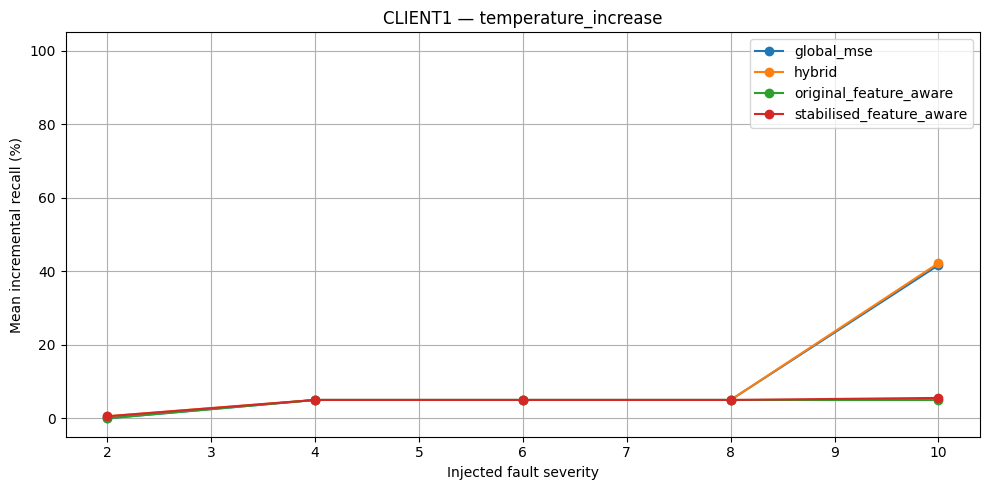

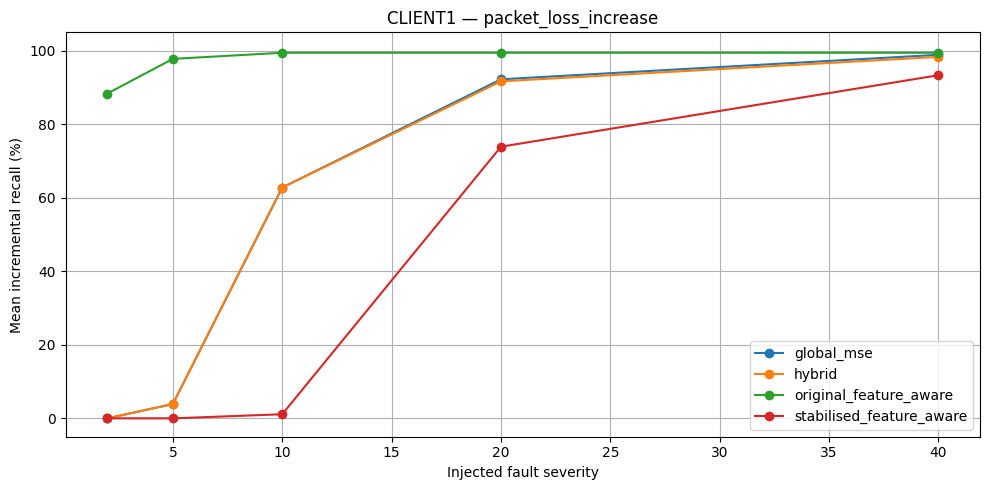

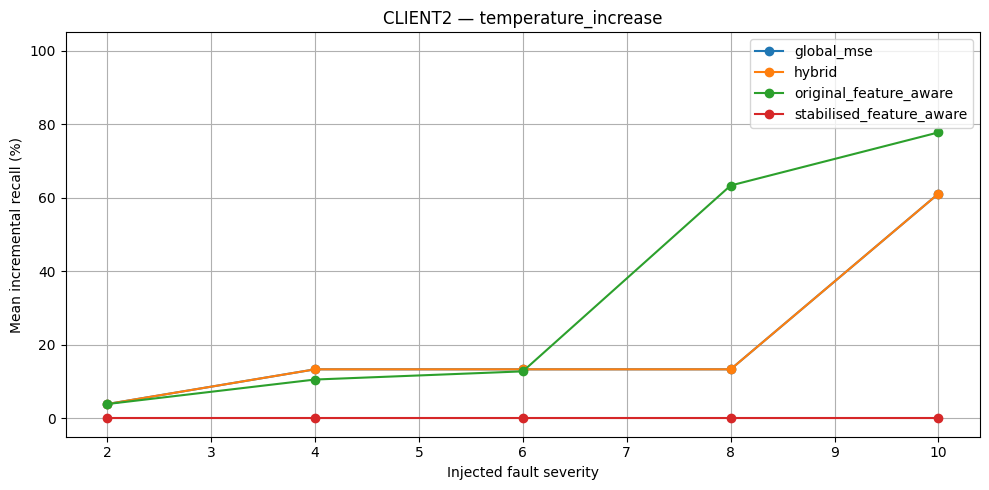

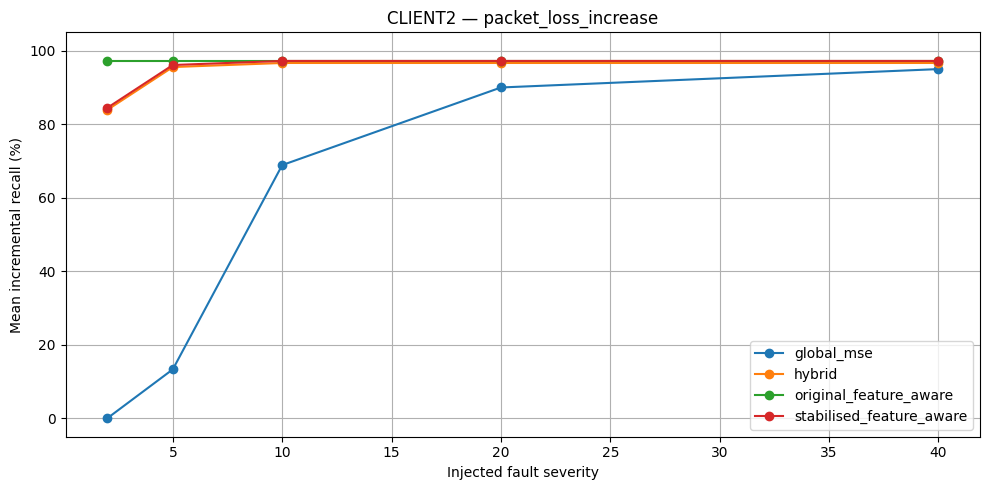

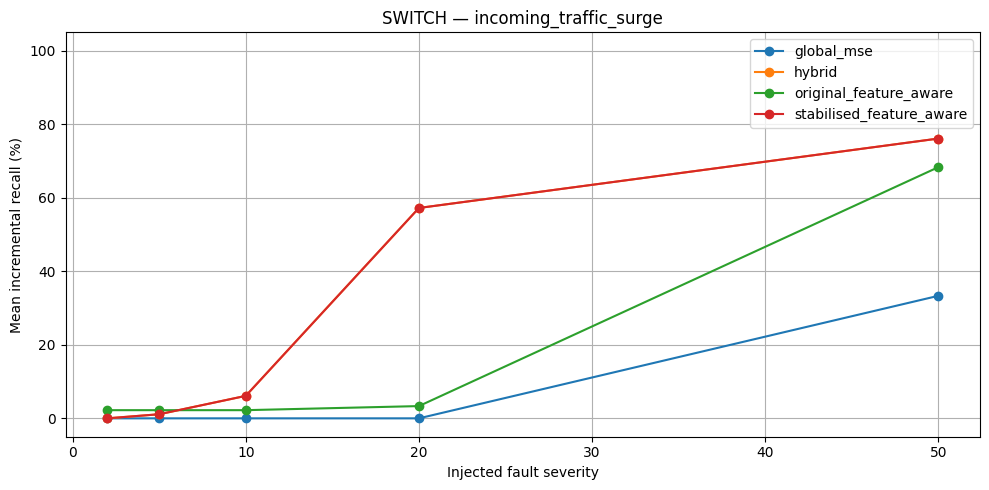

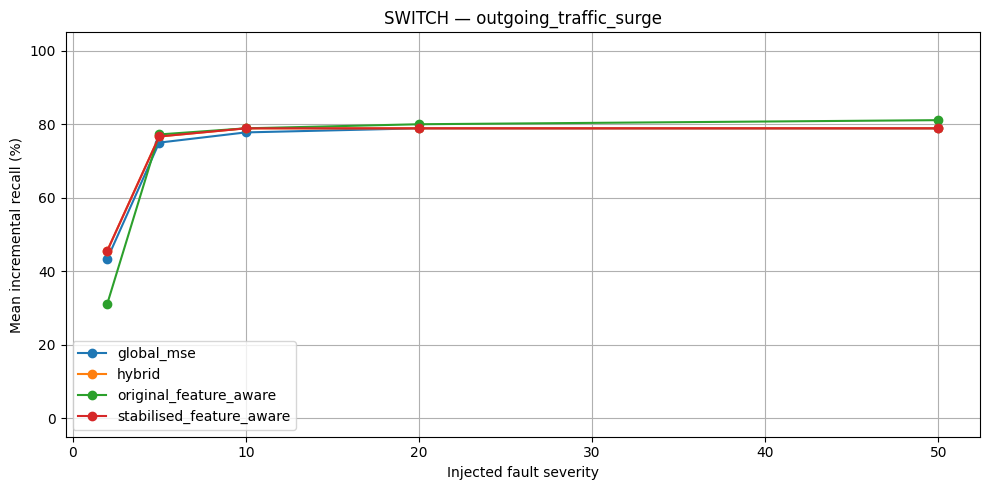

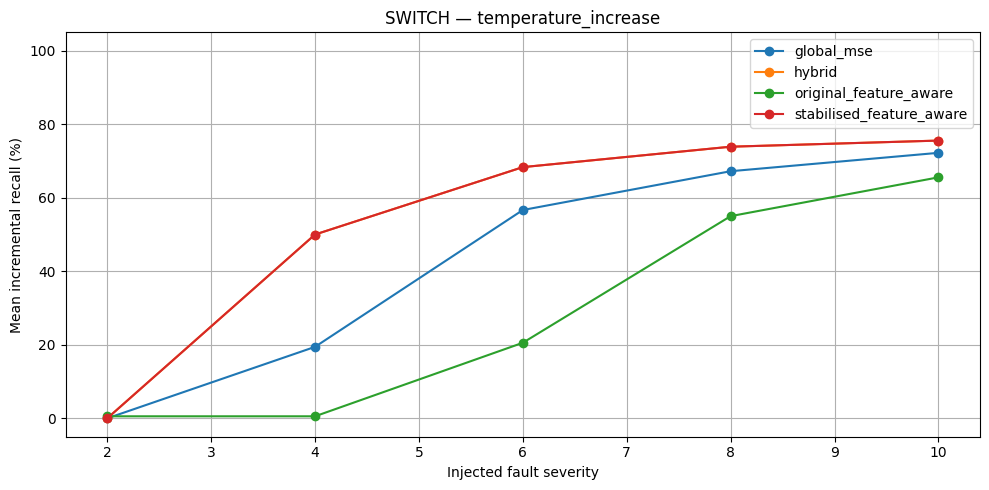

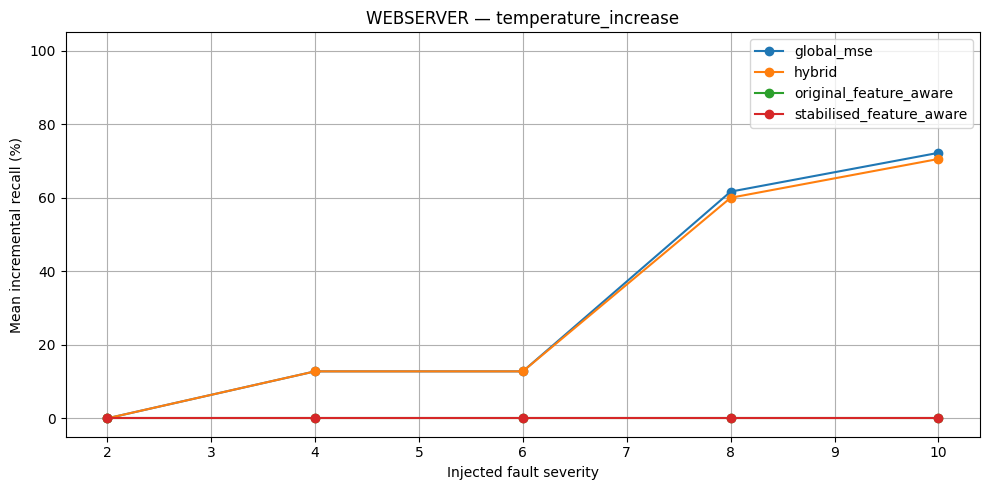

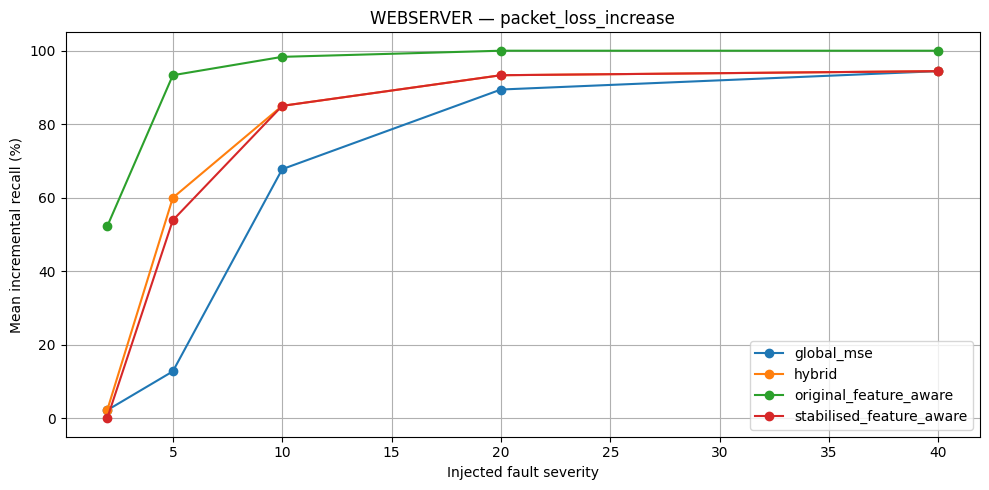

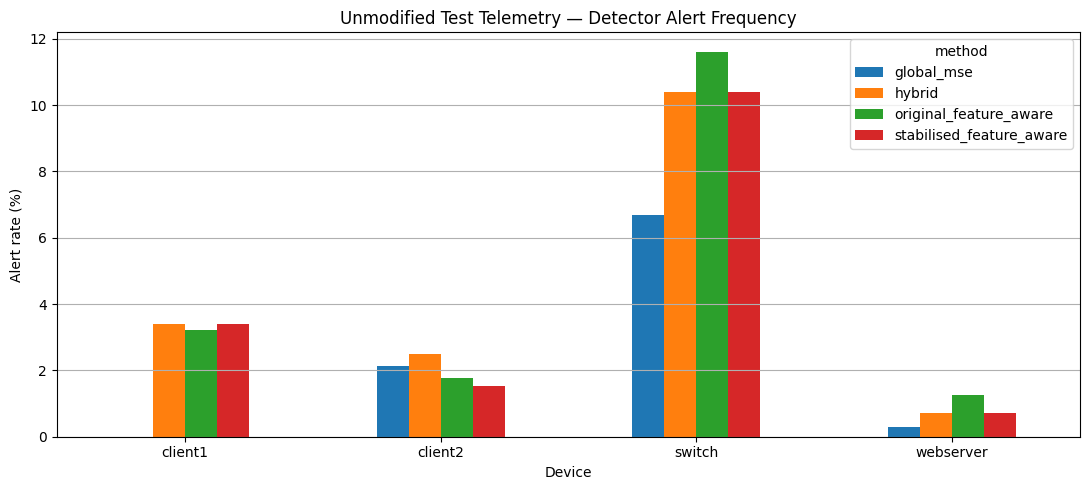


SECTION 13 COMPLETE

Results directory:
C:\Users\alwyn\OneDrive\Documents\Year 3 - Semester 2\Capstone\lstm_hybrid_detection

Files saved:
- threshold_candidates.csv
- selected_thresholds.csv
- alert_comparison.csv
- dominant_metrics.csv
- fault_results_detailed.csv
- fault_results_summary.csv
- device_comparison.csv
- Detector sensitivity graphs
- Detector alert-rate comparison graph
- Four hybrid scoring configuration files

IMPORTANT:
Unmodified telemetry alert rates are not verified false-positive rates.
Injected fault experiments are exploratory because these test periods have already been used during model development.


In [22]:

# ============================================================
# SECTION 13 — HYBRID ANOMALY DETECTION
#              AND ROBUST FEATURE CALIBRATION
#
# CORRECTED VERSION
#
# Improvements:
# - Removes the hard clipping bug
# - Uses log1p() for smooth score compression
# - Uses more stable feature-error calibration
# - Prevents unusable saturated thresholds
# - Calibrates using training/validation data only
# - Evaluates four detection approaches
# - Accounts for overlapping LSTM sequences
# - Preserves the original global MSE baseline
# - Saves all results and detector configurations
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
import warnings

from pathlib import Path

SECTION13_DIR = Path("lstm_hybrid_detection")
SECTION13_DIR.mkdir(parents=True, exist_ok=True)

# ------------------------------------------------------------
# 13.1 Configuration
# ------------------------------------------------------------

DEVICES_13 = [
    "client1",
    "client2",
    "switch",
    "webserver"
]

PERCENTILES_13 = [
    95,
    97.5,
    99,
    99.5,
    99.9
]

VALIDATION_ALERT_BUDGET_13 = 2.0

# Stabilisation parameters.
RELATIVE_SCALE_FLOOR_13 = 0.10
ABSOLUTE_SCALE_FLOOR_13 = 1e-4

# No hard maximum is imposed on feature scores.
# The log1p transformation compresses large values.

TARGET_SCENARIOS_13 = {
    "client1": [
        "temperature_increase",
        "packet_loss_increase"
    ],
    "client2": [
        "temperature_increase",
        "packet_loss_increase"
    ],
    "switch": [
        "incoming_traffic_surge",
        "outgoing_traffic_surge",
        "temperature_increase"
    ],
    "webserver": [
        "temperature_increase",
        "packet_loss_increase"
    ]
}

STEP_13 = pd.Timedelta(
    WINDOWS[ACTIVE_WINDOW]
)

# Reset results every time the section is rerun.
CALIBRATION_13 = {}
STABLE_SCORES_13 = {}
METRIC_SCORES_13 = {}
THRESHOLDS_13 = {}

THRESHOLD_ROWS_13 = []
ALERT_ROWS_13 = []
FAULT_ROWS_13 = []
DOMINANCE_ROWS_13 = []

np.random.seed(RANDOM_STATE)


# ------------------------------------------------------------
# 13.2 Fit robust feature-error calibration
# ------------------------------------------------------------

def fit_stable_calibration_13(feature_errors):
    """
    Fit a robust reconstruction-error reference
    using training observations only.

    No assumption is made that all training
    observations are anomaly-free.
    """

    errors = np.asarray(
        feature_errors,
        dtype=np.float64
    )

    if errors.ndim != 2:
        raise ValueError(
            "Expected feature-error matrix "
            "(samples, features)."
        )

    if not np.isfinite(errors).all():
        raise ValueError(
            "Non-finite training reconstruction errors."
        )

    median = np.median(
        errors,
        axis=0
    )

    mad = np.median(
        np.abs(errors - median),
        axis=0
    )

    q25 = np.percentile(
        errors,
        25,
        axis=0
    )

    q75 = np.percentile(
        errors,
        75,
        axis=0
    )

    mad_scale = 1.4826 * mad

    iqr_scale = (
        q75 - q25
    ) / 1.349

    relative_floor = (
        RELATIVE_SCALE_FLOOR_13
        * np.maximum(median, 0.0)
    )

    absolute_floor = np.full_like(
        median,
        ABSOLUTE_SCALE_FLOOR_13
    )

    scale = np.maximum.reduce([
        mad_scale,
        iqr_scale,
        relative_floor,
        absolute_floor
    ])

    return {
        "median": median,
        "scale": scale,
        "mad": mad,
        "iqr_scale": iqr_scale,
        "relative_floor": relative_floor
    }


# ------------------------------------------------------------
# 13.3 Corrected stabilised feature-aware scoring
# ------------------------------------------------------------

def stable_feature_scores_13(
    feature_errors,
    calibration,
    metric_groups
):
    """
    Calculate stabilised anomaly scores.

    Steps:
    1. Calculate deviations from typical training errors.
    2. Divide by robust feature-specific scales.
    3. Retain positive deviations.
    4. Compress large deviations with log1p().
    5. Aggregate within original metric groups.
    6. Use maximum metric score for the sequence.

    Unlike the previous implementation, no hard score
    cap is used. This prevents threshold saturation.
    """

    errors = np.asarray(
        feature_errors,
        dtype=np.float64
    )

    median = np.asarray(
        calibration["median"],
        dtype=np.float64
    )

    scale = np.asarray(
        calibration["scale"],
        dtype=np.float64
    )

    if errors.ndim != 2:
        raise ValueError(
            "Feature errors must be two-dimensional."
        )

    if errors.shape[1] != len(median):
        raise ValueError(
            "Feature dimensions do not match calibration."
        )

    if not np.isfinite(errors).all():
        raise ValueError(
            "Non-finite reconstruction errors detected."
        )

    # Positive deviation from typical reconstruction error.
    z = np.maximum(
        (errors - median) / scale,
        0.0
    )

    # FIX: Smooth compression instead of hard clipping.
    z = np.log1p(z)

    metric_names = list(
        metric_groups.keys()
    )

    metric_scores = np.column_stack([
        z[:, metric_groups[name]].mean(axis=1)
        for name in metric_names
    ])

    sequence_scores = metric_scores.max(
        axis=1
    )

    dominant_indices = metric_scores.argmax(
        axis=1
    )

    dominant_metrics = np.asarray(
        metric_names
    )[dominant_indices]

    return (
        sequence_scores,
        metric_scores,
        dominant_metrics
    )


# ------------------------------------------------------------
# 13.4 Calculate stable scores for all four devices
# ------------------------------------------------------------

for device in DEVICES_13:

    print(f"\nProcessing {device.upper()}")

    training_errors = FEATURE_ERROR_DATA_12[
        device
    ]["train"]

    calibration = fit_stable_calibration_13(
        training_errors
    )

    CALIBRATION_13[device] = calibration

    STABLE_SCORES_13[device] = {}
    METRIC_SCORES_13[device] = {}

    for split in [
        "train",
        "validation",
        "test"
    ]:

        feature_errors = FEATURE_ERROR_DATA_12[
            device
        ][split]

        scores, metric_scores, dominant = (
            stable_feature_scores_13(
                feature_errors,
                calibration,
                METRIC_GROUPS_12[device]
            )
        )

        STABLE_SCORES_13[
            device
        ][split] = scores

        METRIC_SCORES_13[
            device
        ][split] = {
            "metric_scores": metric_scores,
            "dominant_metric": dominant
        }

        print(
            f"  {split}: {len(scores)} sequences, "
            f"maximum score = {scores.max():.4f}"
        )


# ------------------------------------------------------------
# 13.5 Diagnose changes to feature calibration
# ------------------------------------------------------------

for device in DEVICES_13:

    feature_names = list(
        FEATURE_COLUMNS[device]
    )

    previous = FEATURE_CALIBRATION_12[
        device
    ]

    updated = CALIBRATION_13[
        device
    ]

    diagnostics = pd.DataFrame({
        "device": device,
        "feature": feature_names,
        "previous_scale": previous["scale"],
        "new_scale": updated["scale"],
        "training_error_median": updated["median"],
        "new_to_old_scale_ratio": (
            updated["scale"] /
            np.maximum(
                previous["scale"],
                1e-12
            )
        )
    })

    diagnostics.to_csv(
        SECTION13_DIR /
        f"{device}_scale_diagnostics.csv",
        index=False
    )

    print(
        f"\n{device.upper()} — "
        "Largest calibration scale changes"
    )

    display(
        diagnostics.nlargest(
            10,
            "new_to_old_scale_ratio"
        ).round(5)
    )


# ------------------------------------------------------------
# 13.6 Calibrate feature-aware thresholds
#
# Global MSE thresholds remain unchanged.
#
# We select candidate stable-score thresholds using
# training percentiles and validation alert frequency.
#
# The HYBRID alert rate must satisfy the budget
# whenever possible.
# ------------------------------------------------------------

for device in DEVICES_13:

    train_scores = np.asarray(
        STABLE_SCORES_13[device]["train"]
    )

    validation_scores = np.asarray(
        STABLE_SCORES_13[device]["validation"]
    )

    global_validation_errors = np.asarray(
        RECONSTRUCTION_ERRORS[
            device
        ]["validation"]
    )

    global_threshold = float(
        ANOMALY_THRESHOLDS[device]
    )

    global_validation_alerts = (
        global_validation_errors > global_threshold
    )

    candidates = []

    for percentile in PERCENTILES_13:

        threshold = float(
            np.percentile(
                train_scores,
                percentile
            )
        )

        stable_validation_alerts = (
            validation_scores > threshold
        )

        hybrid_validation_alerts = (
            global_validation_alerts |
            stable_validation_alerts
        )

        train_alert_rate = (
            100 * np.mean(
                train_scores > threshold
            )
        )

        stable_validation_rate = (
            100 * stable_validation_alerts.mean()
        )

        global_validation_rate = (
            100 * global_validation_alerts.mean()
        )

        hybrid_validation_rate = (
            100 * hybrid_validation_alerts.mean()
        )

        row = {
            "device": device,
            "percentile": percentile,
            "stable_threshold": threshold,
            "stable_train_alert_pct":
                train_alert_rate,
            "stable_validation_alert_pct":
                stable_validation_rate,
            "global_validation_alert_pct":
                global_validation_rate,
            "hybrid_validation_alert_pct":
                hybrid_validation_rate
        }

        candidates.append(row)
        THRESHOLD_ROWS_13.append(row)

    # Detect degenerate calibration candidates.
    # The score is not hard-capped, so repeated thresholds
    # are possible but do not automatically make the
    # detector impossible to trigger.
    unique_threshold_count = len(
        np.unique([
            c["stable_threshold"]
            for c in candidates
        ])
    )

    if unique_threshold_count == 1:
        warnings.warn(
            f"{device}: all threshold candidates are "
            "identical. Inspect the training score "
            "distribution before interpreting results."
        )

    eligible = [
        row for row in candidates
        if (
            row["hybrid_validation_alert_pct"]
            <= VALIDATION_ALERT_BUDGET_13
        )
    ]

    if eligible:

        selected = min(
            eligible,
            key=lambda row: row["stable_threshold"]
        )

        budget_met = True

    else:

        selected = min(
            candidates,
            key=lambda row: (
                row["hybrid_validation_alert_pct"],
                -row["stable_threshold"]
            )
        )

        budget_met = False

    THRESHOLDS_13[device] = {
        "global_threshold": global_threshold,
        "stable_threshold":
            selected["stable_threshold"],
        "stable_percentile":
            selected["percentile"],
        "stable_validation_alert_pct":
            selected["stable_validation_alert_pct"],
        "global_validation_alert_pct":
            selected["global_validation_alert_pct"],
        "hybrid_validation_alert_pct":
            selected["hybrid_validation_alert_pct"],
        "validation_budget_met": budget_met
    }


THRESHOLD_TABLE_DF_13 = pd.DataFrame(
    THRESHOLD_ROWS_13
)

SELECTED_THRESHOLDS_DF_13 = (
    pd.DataFrame.from_dict(
        THRESHOLDS_13,
        orient="index"
    )
)

print("\n" + "=" * 70)
print("THRESHOLD CANDIDATES")
print("=" * 70)

display(
    THRESHOLD_TABLE_DF_13.round(4)
)

print("\nSELECTED HYBRID THRESHOLDS")

display(
    SELECTED_THRESHOLDS_DF_13.round(4)
)

THRESHOLD_TABLE_DF_13.to_csv(
    SECTION13_DIR /
    "threshold_candidates.csv",
    index=False
)

SELECTED_THRESHOLDS_DF_13.to_csv(
    SECTION13_DIR /
    "selected_thresholds.csv"
)


# ------------------------------------------------------------
# 13.7 Define the four anomaly detectors
# ------------------------------------------------------------

def detector_predictions_13(
    global_errors,
    stable_scores,
    original_feature_scores,
    global_threshold,
    stable_threshold,
    original_feature_threshold
):
    """
    Return anomaly predictions for four detectors.
    """

    global_errors = np.asarray(
        global_errors,
        dtype=float
    )

    stable_scores = np.asarray(
        stable_scores,
        dtype=float
    )

    original_feature_scores = np.asarray(
        original_feature_scores,
        dtype=float
    )

    global_alerts = (
        global_errors > global_threshold
    )

    original_feature_alerts = (
        original_feature_scores >
        original_feature_threshold
    )

    stable_alerts = (
        stable_scores > stable_threshold
    )

    hybrid_alerts = (
        global_alerts | stable_alerts
    )

    return {
        "global_mse": global_alerts,
        "original_feature_aware":
            original_feature_alerts,
        "stabilised_feature_aware":
            stable_alerts,
        "hybrid": hybrid_alerts
    }


# ------------------------------------------------------------
# 13.8 Compare unmodified telemetry alert rates
# ------------------------------------------------------------

for device in DEVICES_13:

    thresholds = THRESHOLDS_13[
        device
    ]

    old_feature_threshold = float(
        SELECTED_THRESHOLDS_12[
            device
        ]["threshold"]
    )

    for split in [
        "train",
        "validation",
        "test"
    ]:

        predictions = detector_predictions_13(
            RECONSTRUCTION_ERRORS[
                device
            ][split],

            STABLE_SCORES_13[
                device
            ][split],

            FEATURE_AWARE_SCORES_12[
                device
            ][split],

            thresholds["global_threshold"],
            thresholds["stable_threshold"],
            old_feature_threshold
        )

        for method, alerts in predictions.items():

            ALERT_ROWS_13.append({
                "device": device,
                "split": split,
                "method": method,
                "sequence_count":
                    len(alerts),
                "alert_count":
                    int(alerts.sum()),
                "alert_rate_pct":
                    100 * alerts.mean()
            })


ALERT_COMPARISON_DF_13 = pd.DataFrame(
    ALERT_ROWS_13
)

ALERT_PIVOT_DF_13 = (
    ALERT_COMPARISON_DF_13
    .pivot_table(
        index=["device", "split"],
        columns="method",
        values="alert_rate_pct"
    )
)

print("\nUNMODIFIED TELEMETRY — ALERT COMPARISON")

display(
    ALERT_PIVOT_DF_13.round(3)
)

ALERT_COMPARISON_DF_13.to_csv(
    SECTION13_DIR /
    "alert_comparison.csv",
    index=False
)


# ------------------------------------------------------------
# 13.9 Identify dominant metrics in stable alerts
# ------------------------------------------------------------

for device in DEVICES_13:

    stable_scores = (
        STABLE_SCORES_13[device]["test"]
    )

    dominant_metrics = (
        METRIC_SCORES_13[device]["test"][
            "dominant_metric"
        ]
    )

    stable_threshold = (
        THRESHOLDS_13[device][
            "stable_threshold"
        ]
    )

    flagged_metrics = dominant_metrics[
        stable_scores > stable_threshold
    ]

    counts = pd.Series(
        flagged_metrics
    ).value_counts()

    for metric, count in counts.items():

        DOMINANCE_ROWS_13.append({
            "device": device,
            "metric": metric,
            "flagged_sequences": int(count)
        })


DOMINANCE_DF_13 = pd.DataFrame(
    DOMINANCE_ROWS_13,
    columns=[
        "device",
        "metric",
        "flagged_sequences"
    ]
)

print("\nDOMINANT METRICS IN STABILISED ALERTS")

if not DOMINANCE_DF_13.empty:
    display(DOMINANCE_DF_13)
else:
    print(
        "No stabilised alerts detected "
        "in the unmodified test data."
    )

DOMINANCE_DF_13.to_csv(
    SECTION13_DIR /
    "dominant_metrics.csv",
    index=False
)


# ------------------------------------------------------------
# 13.10 Re-evaluate simulated faults
#
# - Five severities per scenario
# - Three test injection periods
# - Four detection methods
#
# Each experiment uses a fresh copy of the
# original test features.
#
# Only changed sequences are reconstructed.
# The original baseline scores are reused elsewhere.
# ------------------------------------------------------------

for device, scenario_names in TARGET_SCENARIOS_13.items():

    print("\n" + "=" * 65)
    print(
        f"FAULT EVALUATION — {device.upper()}"
    )
    print("=" * 65)

    model = LSTM_MODELS[device]
    scaler = SCALERS[device]

    feature_columns = list(
        FEATURE_COLUMNS[device]
    )

    timestamps = pd.DatetimeIndex(
        SPLIT_DATA[device]["test_times"]
    )

    original_scaled = np.asarray(
        SPLIT_DATA[device]["test"],
        dtype=np.float32
    )

    sequence_times = pd.DatetimeIndex(
        SEQUENCE_TIMESTAMPS[device]["test"]
    )

    original_global = np.asarray(
        RECONSTRUCTION_ERRORS[device]["test"],
        dtype=float
    )

    original_stable = np.asarray(
        STABLE_SCORES_13[device]["test"],
        dtype=float
    )

    original_feature = np.asarray(
        FEATURE_AWARE_SCORES_12[device]["test"],
        dtype=float
    )

    thresholds = THRESHOLDS_13[device]

    original_feature_threshold = float(
        SELECTED_THRESHOLDS_12[
            device
        ]["threshold"]
    )

    baseline_predictions = detector_predictions_13(
        original_global,
        original_stable,
        original_feature,
        thresholds["global_threshold"],
        thresholds["stable_threshold"],
        original_feature_threshold
    )

    for scenario_name in scenario_names:

        scenario = SENSITIVITY_SCENARIOS[
            device
        ][scenario_name]

        metric = scenario["metric"]
        operation = scenario["operation"]

        print(f"\nScenario: {scenario_name}")

        for magnitude in scenario["magnitudes"]:

            for period in INJECTION_PERIODS[device]:

                fault_start = period["start"]
                fault_end = period["end"]

                injection_mask = (
                    (timestamps >= fault_start) &
                    (timestamps <= fault_end)
                )

                modified_scaled, _ = inject_fault(
                    original_scaled.copy(),
                    scaler,
                    feature_columns,
                    metric,
                    operation,
                    magnitude,
                    injection_mask
                )

                X_fault, fault_times = create_sequences(
                    modified_scaled,
                    timestamps,
                    SEQUENCE_LENGTH,
                    SEQUENCE_STRIDE
                )

                fault_times = pd.DatetimeIndex(
                    fault_times
                )

                if not fault_times.equals(sequence_times):
                    raise ValueError(
                        f"Sequence alignment mismatch: "
                        f"{device}"
                    )

                # Sequence windows containing modified
                # samples may remain affected after
                # the injection itself has ended.
                contamination_end = (
                    fault_end
                    + (SEQUENCE_LENGTH - 1) * STEP_13
                )

                affected = (
                    (sequence_times >= fault_start) &
                    (sequence_times <= contamination_end)
                )

                # Sequences ending while fault is active.
                fault_active = (
                    (sequence_times >= fault_start) &
                    (sequence_times <= fault_end)
                )

                # Exclude post-fault contaminated windows
                # from the control interval.
                clean_control = (
                    (sequence_times < fault_start) |
                    (sequence_times > contamination_end)
                )

                X_affected = X_fault[affected]

                if len(X_affected) == 0:
                    raise ValueError(
                        "No fault-affected LSTM sequences."
                    )

                # Calculate reconstruction error per feature.
                changed_feature_errors = (
                    feature_reconstruction_errors_12(
                        model,
                        X_affected
                    )
                )

                # Global MSE reconstruction error.
                changed_global = (
                    changed_feature_errors.mean(axis=1)
                )

                # New stabilised feature-aware score.
                changed_stable, _, _ = (
                    stable_feature_scores_13(
                        changed_feature_errors,
                        CALIBRATION_13[device],
                        METRIC_GROUPS_12[device]
                    )
                )

                # Original Section 12 feature-aware score.
                changed_original_feature, _, _ = (
                    calculate_feature_aware_score_12(
                        changed_feature_errors,
                        FEATURE_CALIBRATION_12[device],
                        METRIC_GROUPS_12[device]
                    )
                )

                # Copy baseline score arrays.
                global_scores = original_global.copy()
                stable_scores = original_stable.copy()
                feature_scores = original_feature.copy()

                # Replace only affected sequence scores.
                global_scores[affected] = changed_global
                stable_scores[affected] = changed_stable

                feature_scores[affected] = (
                    changed_original_feature
                )

                predictions = detector_predictions_13(
                    global_scores,
                    stable_scores,
                    feature_scores,
                    thresholds["global_threshold"],
                    thresholds["stable_threshold"],
                    original_feature_threshold
                )

                active_count = int(
                    fault_active.sum()
                )

                control_count = int(
                    clean_control.sum()
                )

                for method, predicted in predictions.items():

                    baseline_alerts = (
                        baseline_predictions[method]
                    )

                    detected = (
                        predicted & fault_active
                    )

                    newly_detected = (
                        predicted &
                        ~baseline_alerts &
                        fault_active
                    )

                    control_alerts = (
                        predicted & clean_control
                    )

                    detected_times = sequence_times[
                        detected
                    ]

                    incremental_times = sequence_times[
                        newly_detected
                    ]

                    if len(detected_times) > 0:

                        detection_delay = (
                            detected_times.min() - fault_start
                        ).total_seconds() / 60

                    else:

                        detection_delay = np.nan

                    if len(incremental_times) > 0:

                        incremental_delay = (
                            incremental_times.min()
                            - fault_start
                        ).total_seconds() / 60

                    else:

                        incremental_delay = np.nan

                    FAULT_ROWS_13.append({
                        "device": device,
                        "scenario": scenario_name,
                        "magnitude": magnitude,
                        "period_id": period["period_id"],
                        "method": method,
                        "fault_start": fault_start,
                        "fault_end": fault_end,
                        "fault_active_sequences":
                            active_count,
                        "detected_sequences":
                            int(detected.sum()),
                        "newly_detected_sequences":
                            int(newly_detected.sum()),
                        "recall_pct":
                            100 * detected.sum()
                            / active_count,
                        "incremental_recall_pct":
                            100 * newly_detected.sum()
                            / active_count,
                        "event_detected":
                            bool(detected.any()),
                        "incremental_event_detected":
                            bool(newly_detected.any()),
                        "control_alert_rate_pct":
                            100 * control_alerts.sum()
                            / control_count,
                        "delay_minutes":
                            detection_delay,
                        "incremental_delay_minutes":
                            incremental_delay
                    })

            print(
                f"  Completed severity: {magnitude}"
            )


# ------------------------------------------------------------
# 13.11 Aggregate fault detection performance
# ------------------------------------------------------------

FAULT_RESULTS_DF_13 = pd.DataFrame(
    FAULT_ROWS_13
)

FAULT_SUMMARY_DF_13 = (
    FAULT_RESULTS_DF_13
    .groupby([
        "device",
        "scenario",
        "method"
    ])
    .agg(
        mean_recall_pct=(
            "recall_pct",
            "mean"
        ),
        mean_incremental_recall_pct=(
            "incremental_recall_pct",
            "mean"
        ),
        event_detection_rate_pct=(
            "event_detected",
            lambda x: 100 * x.mean()
        ),
        incremental_event_detection_rate_pct=(
            "incremental_event_detected",
            lambda x: 100 * x.mean()
        ),
        mean_control_alert_rate_pct=(
            "control_alert_rate_pct",
            "mean"
        ),
        mean_delay_minutes=(
            "delay_minutes",
            "mean"
        ),
        mean_incremental_delay_minutes=(
            "incremental_delay_minutes",
            "mean"
        )
    )
    .reset_index()
)

print("\n" + "=" * 70)
print("HYBRID FAULT DETECTION PERFORMANCE")
print("=" * 70)

display(
    FAULT_SUMMARY_DF_13.round(2)
)

FAULT_RESULTS_DF_13.to_csv(
    SECTION13_DIR /
    "fault_results_detailed.csv",
    index=False
)

FAULT_SUMMARY_DF_13.to_csv(
    SECTION13_DIR /
    "fault_results_summary.csv",
    index=False
)


# ------------------------------------------------------------
# 13.12 Device-level detector comparison
# ------------------------------------------------------------

DEVICE_COMPARISON_DF_13 = (
    FAULT_RESULTS_DF_13
    .groupby([
        "device",
        "method"
    ])
    .agg(
        mean_recall_pct=(
            "recall_pct",
            "mean"
        ),
        mean_incremental_recall_pct=(
            "incremental_recall_pct",
            "mean"
        ),
        event_detection_rate_pct=(
            "event_detected",
            lambda x: 100 * x.mean()
        ),
        mean_control_alert_rate_pct=(
            "control_alert_rate_pct",
            "mean"
        ),
        mean_delay_minutes=(
            "delay_minutes",
            "mean"
        )
    )
    .reset_index()
)

print("\nDEVICE-LEVEL DETECTOR COMPARISON")

display(
    DEVICE_COMPARISON_DF_13.round(2)
)

DEVICE_COMPARISON_DF_13.to_csv(
    SECTION13_DIR /
    "device_comparison.csv",
    index=False
)


# ------------------------------------------------------------
# 13.13 Visualise fault sensitivity
# ------------------------------------------------------------

for device, scenario_names in TARGET_SCENARIOS_13.items():

    for scenario_name in scenario_names:

        subset = FAULT_RESULTS_DF_13[
            (
                FAULT_RESULTS_DF_13["device"]
                == device
            ) &
            (
                FAULT_RESULTS_DF_13["scenario"]
                == scenario_name
            )
        ]

        curves = (
            subset.groupby([
                "magnitude",
                "method"
            ])["incremental_recall_pct"]
            .mean()
            .unstack()
        )

        plt.figure(figsize=(10, 5))

        for method in curves.columns:

            plt.plot(
                curves.index,
                curves[method],
                marker="o",
                linewidth=1.5,
                label=method
            )

        plt.title(
            f"{device.upper()} — "
            f"{scenario_name}"
        )

        plt.xlabel(
            "Injected fault severity"
        )

        plt.ylabel(
            "Mean incremental recall (%)"
        )

        plt.ylim(-5, 105)
        plt.grid(True)
        plt.legend()
        plt.tight_layout()

        plt.savefig(
            SECTION13_DIR /
            f"{device}_{scenario_name}_sensitivity.png",
            dpi=150
        )

        plt.show()


# ------------------------------------------------------------
# 13.14 Plot detector alert-rate comparison
# ------------------------------------------------------------

test_alerts = ALERT_COMPARISON_DF_13[
    ALERT_COMPARISON_DF_13["split"] == "test"
]

alert_pivot = test_alerts.pivot(
    index="device",
    columns="method",
    values="alert_rate_pct"
)

ax = alert_pivot.plot(
    kind="bar",
    figsize=(11, 5)
)

ax.set_title(
    "Unmodified Test Telemetry — "
    "Detector Alert Frequency"
)

ax.set_xlabel("Device")
ax.set_ylabel("Alert rate (%)")

plt.xticks(rotation=0)
plt.grid(axis="y")
plt.tight_layout()

plt.savefig(
    SECTION13_DIR /
    "detector_alert_rate_comparison.png",
    dpi=150
)

plt.show()


# ------------------------------------------------------------
# 13.15 Save calibrated detector configurations
# ------------------------------------------------------------

for device in DEVICES_13:

    artifact = {
        "device": device,
        "active_window": ACTIVE_WINDOW,
        "sequence_length": SEQUENCE_LENGTH,

        "feature_columns": list(
            FEATURE_COLUMNS[device]
        ),

        "metric_groups":
            METRIC_GROUPS_12[device],

        "calibration":
            CALIBRATION_13[device],

        "scoring_method":
            "positive_log1p_robust_residual",

        "relative_scale_floor":
            RELATIVE_SCALE_FLOOR_13,

        "absolute_scale_floor":
            ABSOLUTE_SCALE_FLOOR_13,

        "global_threshold":
            THRESHOLDS_13[device][
                "global_threshold"
            ],

        "stable_threshold":
            THRESHOLDS_13[device][
                "stable_threshold"
            ],

        "stable_percentile":
            THRESHOLDS_13[device][
                "stable_percentile"
            ],

        "validation_budget_met":
            THRESHOLDS_13[device][
                "validation_budget_met"
            ],

        "hybrid_validation_alert_pct":
            THRESHOLDS_13[device][
                "hybrid_validation_alert_pct"
            ]
    }

    joblib.dump(
        artifact,
        SECTION13_DIR /
        f"{device}_hybrid_config.joblib"
    )


# ------------------------------------------------------------
# 13.16 Final summary
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("SECTION 13 COMPLETE")
print("=" * 70)

print("\nResults directory:")
print(SECTION13_DIR.resolve())

print("\nFiles saved:")
print("- threshold_candidates.csv")
print("- selected_thresholds.csv")
print("- alert_comparison.csv")
print("- dominant_metrics.csv")
print("- fault_results_detailed.csv")
print("- fault_results_summary.csv")
print("- device_comparison.csv")
print("- Detector sensitivity graphs")
print("- Detector alert-rate comparison graph")
print("- Four hybrid scoring configuration files")

print("\nIMPORTANT:")
print(
    "Unmodified telemetry alert rates are not "
    "verified false-positive rates."
)

print(
    "Injected fault experiments are exploratory "
    "because these test periods have already "
    "been used during model development."
)




UNMODIFIED TELEMETRY — EVENT SUMMARY


,device,method,persistence,sequence_alert_rate_pct,sequence_alert_count,confirmed_events,observation_days,events_per_day,mean_event_duration_minutes,mean_confirmation_delay_minutes
0,client1,global_mse,1,0.000,0,0,1.762,0.000,NaN,NaN
1,client1,global_mse,3,0.000,0,0,1.762,0.000,NaN,NaN
2,client1,global_mse,5,0.000,0,0,1.762,0.000,NaN,NaN
3,client1,original_feature_aware,1,3.231,82,5,1.762,2.838,18.200,0.0
4,client1,original_feature_aware,3,3.231,82,3,1.762,1.703,26.667,2.0
5,client1,original_feature_aware,5,3.231,82,3,1.762,1.703,26.667,4.0
6,client1,stabilised_feature_aware,1,3.388,86,6,1.762,3.406,15.333,0.0
7,client1,stabilised_feature_aware,3,3.388,86,3,1.762,1.703,27.333,2.0
8,client1,stabilised_feature_aware,5,3.388,86,3,1.762,1.703,27.333,4.0
9,client1,hybrid,1,3.388,86,6,1.762,3.406,15.333,0.0



EVENT-LEVEL FAULT EVALUATION — CLIENT1


C:\Users\alwyn\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCache\local-packages\Python312\site-packages\sklearn\utils\validation.py:2691: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(
C:\Users\alwyn\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCache\local-packages\Python312\site-packages\sklearn\utils\validation.py:2691: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(
C:\Users\alwyn\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCache\local-packages\Python312\site-packages\sklearn\utils\validation.py:2691: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(
C:\Users\alwyn\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCache\local-packages\Python312\site-pac

  Completed: temperature_increase


...

,device,scenario,method,persistence,experiments,event_detection_rate_pct,incremental_event_detection_rate_pct,mean_detection_delay_minutes,mean_incremental_delay_minutes,events_per_day
0,client1,packet_loss_increase,global_mse,1,15,66.67,66.67,13.20,13.20,0.00
1,client1,packet_loss_increase,global_mse,3,15,66.67,66.67,15.50,15.50,0.00
2,client1,packet_loss_increase,global_mse,5,15,66.67,66.67,17.50,17.50,0.00
3,client1,packet_loss_increase,hybrid,1,15,53.33,53.33,16.25,16.25,3.41
4,client1,packet_loss_increase,hybrid,3,15,53.33,53.33,18.25,18.25,1.70
...,...,...,...,...,...,...,...,...,...,...
103,webserver,temperature_increase,original_feature_aware,3,15,0.00,0.00,NaN,NaN,0.61
104,webserver,temperature_increase,original_feature_aware,5,15,0.00,0.00,NaN,NaN,0.61
105,webserver,temperature_increase,stabilised_feature_aware,1,15,33.33,0.00,37.00,NaN,1.21
106,webserver,temperature_increase,stabilised_feature_aware,3,15,33.33,0.00,39.00,NaN,1.21



DEVICE-LEVEL EVENT COMPARISON


,device,method,persistence,experiments,event_detection_rate_pct,incremental_detection_rate_pct,mean_detection_delay_minutes,mean_incremental_delay_minutes,events_per_day
0,client1,global_mse,1,30,53.33,53.33,24.38,24.38,0.00
1,client1,global_mse,3,30,53.33,53.33,26.56,26.56,0.00
2,client1,global_mse,5,30,53.33,53.33,28.56,28.56,0.00
3,client1,hybrid,1,30,50.00,50.00,29.53,29.53,3.41
4,client1,hybrid,3,30,46.67,46.67,29.71,29.71,1.70
5,client1,hybrid,5,30,46.67,46.67,31.71,31.71,1.70
6,client1,original_feature_aware,1,30,46.67,46.67,15.71,15.71,2.84
7,client1,original_feature_aware,3,30,50.00,50.00,17.13,17.13,1.70
8,client1,original_feature_aware,5,30,50.00,50.00,19.13,19.13,1.70
9,client1,stabilised_feature_aware,1,30,36.67,36.67,33.55,33.55,3.41



PROVISIONAL MODEL SELECTION


,device,selected_method,selected_persistence,selection_score,incremental_detection_rate_pct,mean_incremental_delay_minutes,events_per_day
0,client1,global_mse,1,0.639,53.333,24.375,0.000
1,client2,original_feature_aware,3,0.780,80.000,9.542,1.707
2,switch,global_mse,1,0.706,64.444,9.483,1.217
3,webserver,hybrid,1,0.733,70.000,11.476,1.215


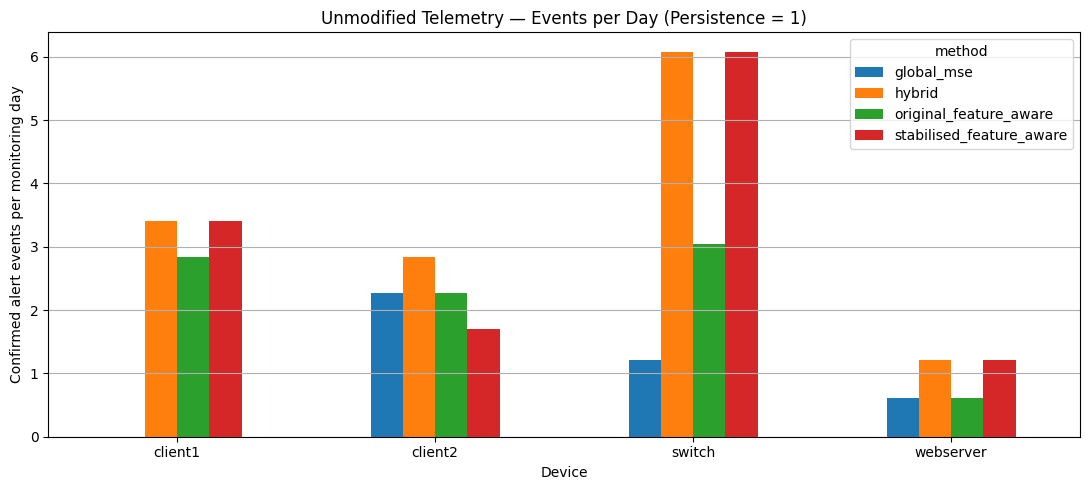

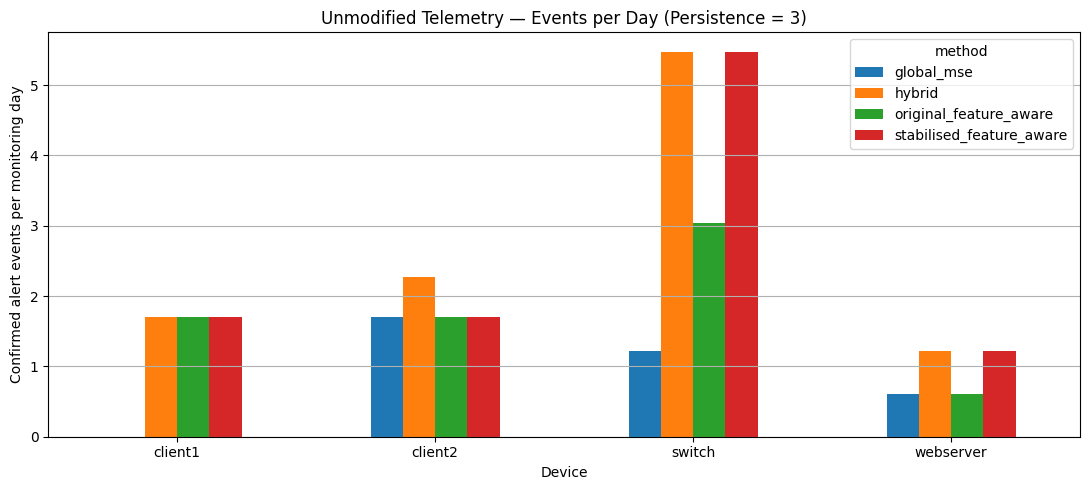

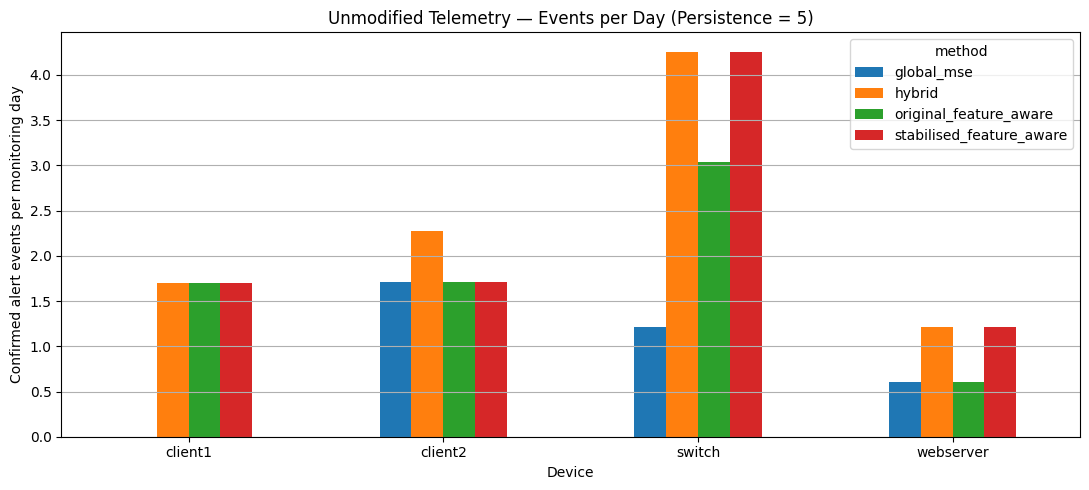

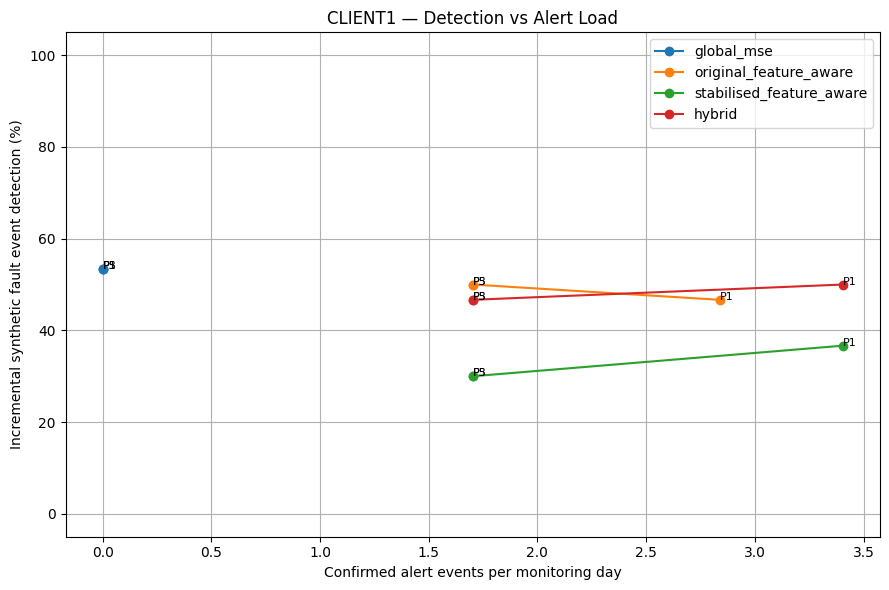

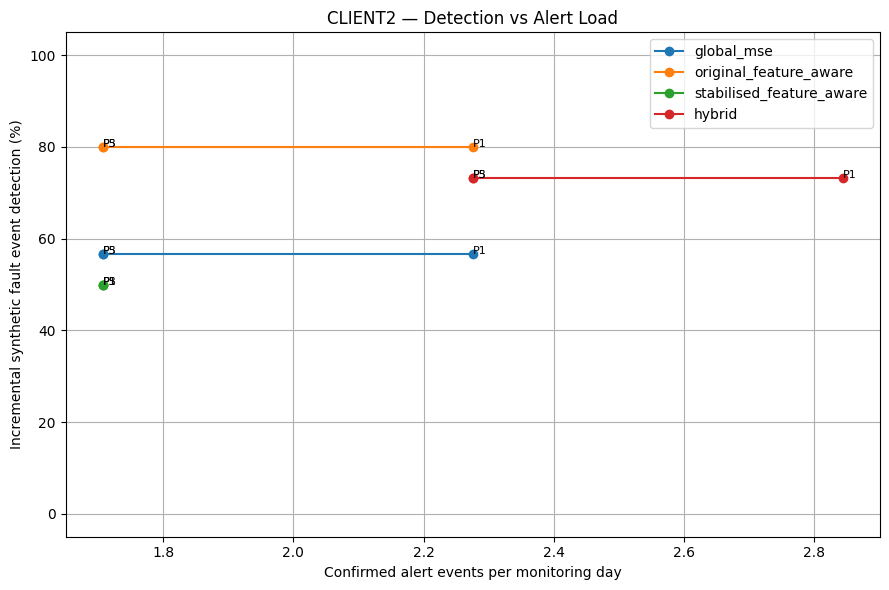

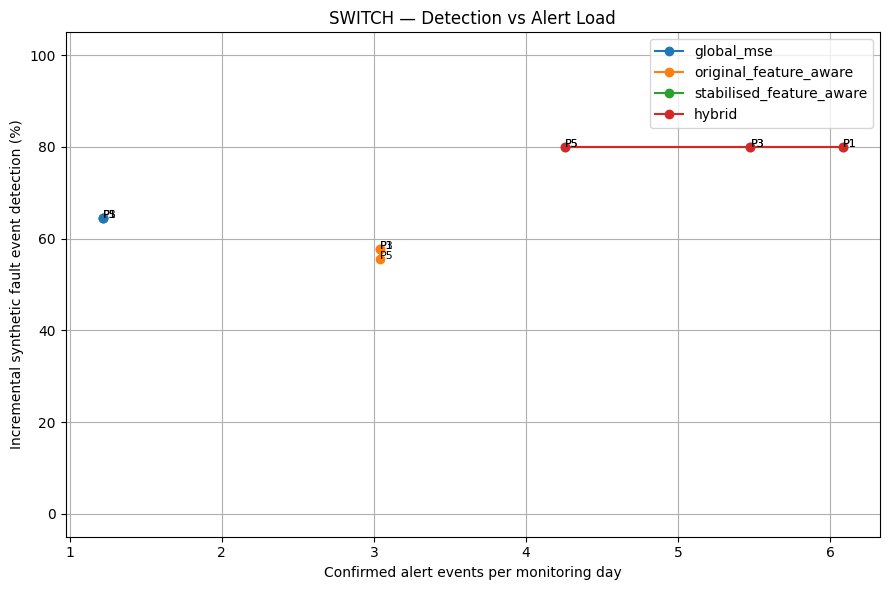

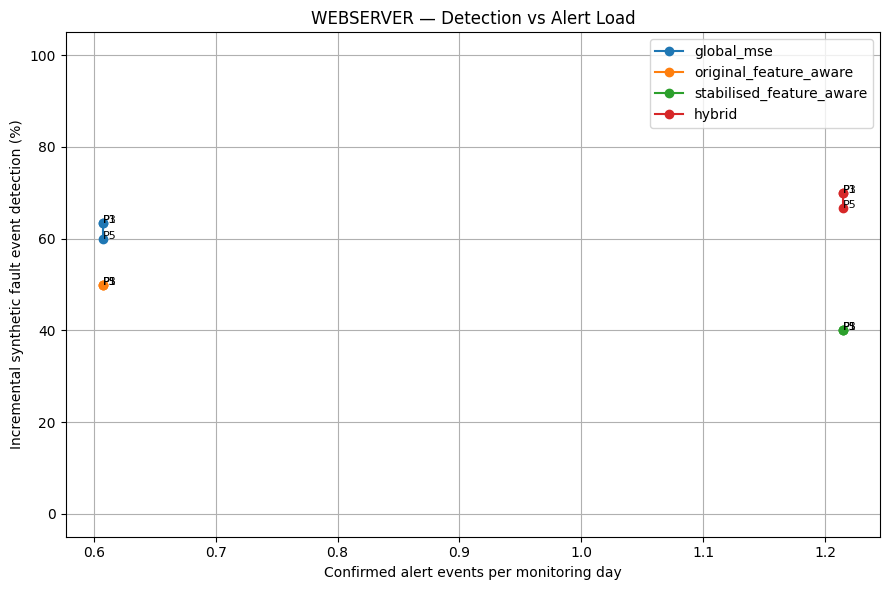


SECTION 14 COMPLETE

Selected operational candidates:


,device,selected_method,selected_persistence,selection_score,incremental_detection_rate_pct,mean_incremental_delay_minutes,events_per_day
0,client1,global_mse,1,0.639,53.333,24.375,0.000
1,client2,original_feature_aware,3,0.780,80.000,9.542,1.707
2,switch,global_mse,1,0.706,64.444,9.483,1.217
3,webserver,hybrid,1,0.733,70.000,11.476,1.215



Results directory:
C:\Users\alwyn\OneDrive\Documents\Year 3 - Semester 2\Capstone\lstm_event_evaluation

Saved outputs:
- unmodified_event_summary.csv
- unmodified_events.csv
- fault_event_results_detailed.csv
- fault_event_summary.csv
- device_event_comparison.csv
- provisional_model_selection.csv
- Events-per-day figures
- Detection-versus-alert-load figures
- Four selected detector configuration files

INTERPRETATION NOTES:
1. Historical telemetry is unlabelled; alerts are not verified false positives.
2. Consecutive LSTM sequence decisions overlap.
3. Model selection is exploratory and should be validated on new monitoring data.
4. Detection delay is measured from simulated fault onset, not from future equipment failure.


: 

In [ ]:

# ============================================================
# SECTION 14 — EVENT-LEVEL FAULT DETECTION,
#              ALERT CONSOLIDATION AND MODEL SELECTION
#
# Requires completed Sections 12 and 13.
#
# This section:
# 1. Consolidates overlapping sequence alerts into events
# 2. Applies persistence-based confirmation
# 3. Measures alert events per monitoring day
# 4. Evaluates injected faults at event level
# 5. Measures incremental fault-caused confirmations
# 6. Compares all four anomaly-scoring methods
# 7. Produces provisional model recommendations
# 8. Saves configurations and evaluation results
#
# No retraining or CSV modification occurs.
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib

from pathlib import Path

SECTION14_DIR = Path("lstm_event_evaluation")
SECTION14_DIR.mkdir(parents=True, exist_ok=True)

# ------------------------------------------------------------
# 14.1 Configuration
# ------------------------------------------------------------

DEVICES_14 = [
    "client1",
    "client2",
    "switch",
    "webserver"
]

METHODS_14 = [
    "global_mse",
    "original_feature_aware",
    "stabilised_feature_aware",
    "hybrid"
]

# Number of consecutive anomalous sequence decisions
# required before an operational alert is confirmed.
#
# For ACTIVE_WINDOW = "1min" and stride = 1:
# 3 consecutive anomalous sequence endpoints
# represent about 3 minutes of sustained alerts.
#
# These windows overlap heavily and are not
# independent observations.

PERSISTENCE_WINDOWS_14 = [1, 3, 5]

# Maximum gap allowed between anomalous sequence
# endpoints when forming a raw event.
#
# A 1-minute gap is the strictest contiguous grouping.

MAX_EVENT_GAP_STEPS_14 = 1

# After a confirmed event closes, a new confirmed
# event within this many minutes is merged into
# the previous event for operational reporting.
#
# This reduces repeated alerts for an ongoing problem.

ALERT_MERGE_GAP_MINUTES_14 = 10

# Operating assumptions for comparative selection.
# These are experiment preferences, not
# verified operational requirements.

TARGET_EVENTS_PER_DAY_14 = 5.0

# Synthetic fault detection is evaluated using
# the same five severities and three injection periods
# previously examined in Sections 11–13.
#
# Consequently, model selection here is exploratory.

STEP_14 = pd.Timedelta(
    WINDOWS[ACTIVE_WINDOW]
)

ALERT_MERGE_GAP_14 = pd.Timedelta(
    minutes=ALERT_MERGE_GAP_MINUTES_14
)

EVENT_ROWS_14 = []
UNMODIFIED_SUMMARY_ROWS_14 = []
FAULT_EVENT_ROWS_14 = []
SELECTION_ROWS_14 = []

UNMODIFIED_PREDICTIONS_14 = {}
UNMODIFIED_EVENTS_14 = {}
FAULT_BASELINE_EVENTS_14 = {}


# ------------------------------------------------------------
# 14.2 Obtain predictions for each scoring method
# ------------------------------------------------------------

def get_predictions_14(device, split="test"):
    """
    Get sequence-level anomaly predictions from
    the four existing detection approaches.

    All methods use their previously calibrated
    thresholds without further optimisation.
    """

    global_errors = np.asarray(
        RECONSTRUCTION_ERRORS[device][split],
        dtype=float
    )

    stable_scores = np.asarray(
        STABLE_SCORES_13[device][split],
        dtype=float
    )

    original_feature_scores = np.asarray(
        FEATURE_AWARE_SCORES_12[device][split],
        dtype=float
    )

    thresholds = THRESHOLDS_13[device]

    predictions = detector_predictions_13(
        global_errors,
        stable_scores,
        original_feature_scores,
        float(thresholds["global_threshold"]),
        float(thresholds["stable_threshold"]),
        float(
            SELECTED_THRESHOLDS_12[device]["threshold"]
        )
    )

    return {
        name: np.asarray(predictions[name], dtype=bool)
        for name in METHODS_14
    }


# ------------------------------------------------------------
# 14.3 Convert sequence alerts into confirmed events
# ------------------------------------------------------------

def consolidate_events_14(
    timestamps,
    predictions,
    persistence=3,
    max_gap_steps=1,
    merge_gap=ALERT_MERGE_GAP_14
):
    """
    Build operational alert events.

    Raw runs:
        Consecutive anomalous sequence endpoints,
        allowing at most max_gap_steps time steps
        between two positive endpoints.

    Confirmation:
        A run must contain at least 'persistence'
        consecutive anomalous sequence decisions.

    Alert event:
        Events confirmed close together are merged.

    Timestamp semantics:
        first_alert_time = first anomalous endpoint
        confirmation_time = endpoint where required
                            persistence is reached
        last_alert_time = last anomalous endpoint

    The timestamp represents an LSTM sequence END,
    not a verified physical fault onset.
    """

    timestamps = pd.DatetimeIndex(timestamps)

    predictions = np.asarray(
        predictions,
        dtype=bool
    )

    if len(timestamps) != len(predictions):
        raise ValueError(
            "Prediction/timestamp length mismatch."
        )

    if len(timestamps) == 0:
        return pd.DataFrame(columns=[
            "first_alert_time",
            "confirmation_time",
            "last_alert_time",
            "duration_minutes",
            "anomalous_sequences",
            "confirmation_delay_minutes"
        ])

    if persistence < 1:
        raise ValueError(
            "Persistence must be at least 1."
        )

    positive_indices = np.flatnonzero(
        predictions
    )

    if len(positive_indices) == 0:
        return pd.DataFrame(columns=[
            "first_alert_time",
            "confirmation_time",
            "last_alert_time",
            "duration_minutes",
            "anomalous_sequences",
            "confirmation_delay_minutes"
        ])

    # Form runs by timestamp adjacency.
    # Confirmation requires consecutive POSITIVE
    # sequence decisions. For persistence > 1,
    # timestamp gaps break the consecutive streak.

    runs = []
    current = [positive_indices[0]]

    for index in positive_indices[1:]:

        previous_index = current[-1]

        elapsed = (
            timestamps[index]
            - timestamps[previous_index]
        )

        if elapsed <= max_gap_steps * STEP_14:
            current.append(index)
        else:
            runs.append(current)
            current = [index]

    runs.append(current)

    # Confirm runs using actual consecutive
    # one-step positive endpoints.
    confirmed = []

    for run in runs:

        streak = 0
        confirmation_index = None

        for position, index in enumerate(run):

            if position == 0:
                streak = 1
            else:
                previous = run[position - 1]

                if (
                    timestamps[index]
                    - timestamps[previous]
                ) == STEP_14:
                    streak += 1
                else:
                    streak = 1

            if streak >= persistence:
                confirmation_index = index
                break

        if confirmation_index is None:
            continue

        first_index = run[0]
        last_index = run[-1]

        confirmed.append({
            "first_alert_time":
                timestamps[first_index],
            "confirmation_time":
                timestamps[confirmation_index],
            "last_alert_time":
                timestamps[last_index],
            "anomalous_sequences":
                len(run)
        })

    if not confirmed:
        return pd.DataFrame(columns=[
            "first_alert_time",
            "confirmation_time",
            "last_alert_time",
            "duration_minutes",
            "anomalous_sequences",
            "confirmation_delay_minutes"
        ])

    # Operationally merge nearby confirmed events.
    merged = [confirmed[0].copy()]

    for event in confirmed[1:]:

        previous = merged[-1]

        gap = (
            event["first_alert_time"]
            - previous["last_alert_time"]
        )

        if gap <= merge_gap:

            previous["last_alert_time"] = max(
                previous["last_alert_time"],
                event["last_alert_time"]
            )

            previous["anomalous_sequences"] += (
                event["anomalous_sequences"]
            )

        else:
            merged.append(event.copy())

    result = pd.DataFrame(merged)

    result["duration_minutes"] = (
        result["last_alert_time"]
        - result["first_alert_time"]
    ).dt.total_seconds() / 60 + (
        STEP_14.total_seconds() / 60
    )

    result["confirmation_delay_minutes"] = (
        result["confirmation_time"]
        - result["first_alert_time"]
    ).dt.total_seconds() / 60

    return result


# ------------------------------------------------------------
# 14.4 Evaluate unmodified historical telemetry
# ------------------------------------------------------------

for device in DEVICES_14:

    timestamps = pd.DatetimeIndex(
        SEQUENCE_TIMESTAMPS[device]["test"]
    )

    predictions = get_predictions_14(
        device,
        split="test"
    )

    UNMODIFIED_PREDICTIONS_14[device] = predictions
    UNMODIFIED_EVENTS_14[device] = {}

    # Observation exposure is based on the actual
    # contiguous monitoring interval, not on the
    # number of overlapping LSTM windows.
    #
    # The output assumes the test timeline represents
    # approximately continuous monitoring.
    #
    # It should not be interpreted as a verified
    # equipment-normal observation period.

    observation_days = (
        timestamps.max() - timestamps.min()
    ).total_seconds() / 86400

    observation_days = max(
        observation_days,
        STEP_14.total_seconds() / 86400
    )

    for method in METHODS_14:

        alerts = predictions[method]

        for persistence in PERSISTENCE_WINDOWS_14:

            events = consolidate_events_14(
                timestamps,
                alerts,
                persistence=persistence,
                max_gap_steps=MAX_EVENT_GAP_STEPS_14,
                merge_gap=ALERT_MERGE_GAP_14
            )

            UNMODIFIED_EVENTS_14[device][
                (method, persistence)
            ] = events

            event_count = len(events)

            mean_duration = (
                events["duration_minutes"].mean()
                if event_count
                else np.nan
            )

            mean_confirmation_delay = (
                events[
                    "confirmation_delay_minutes"
                ].mean()
                if event_count
                else np.nan
            )

            UNMODIFIED_SUMMARY_ROWS_14.append({
                "device": device,
                "method": method,
                "persistence": persistence,
                "sequence_alert_rate_pct":
                    100 * alerts.mean(),
                "sequence_alert_count":
                    int(alerts.sum()),
                "confirmed_events":
                    event_count,
                "observation_days":
                    observation_days,
                "events_per_day":
                    event_count / observation_days,
                "mean_event_duration_minutes":
                    mean_duration,
                "mean_confirmation_delay_minutes":
                    mean_confirmation_delay
            })

            if event_count:

                export = events.copy()

                export.insert(
                    0, "device", device
                )

                export.insert(
                    1, "method", method
                )

                export.insert(
                    2, "persistence", persistence
                )

                EVENT_ROWS_14.extend(
                    export.to_dict("records")
                )


UNMODIFIED_SUMMARY_DF_14 = pd.DataFrame(
    UNMODIFIED_SUMMARY_ROWS_14
)

EVENTS_DF_14 = pd.DataFrame(EVENT_ROWS_14)

print("\nUNMODIFIED TELEMETRY — EVENT SUMMARY")

display(
    UNMODIFIED_SUMMARY_DF_14.round(3)
)

UNMODIFIED_SUMMARY_DF_14.to_csv(
    SECTION14_DIR / "unmodified_event_summary.csv",
    index=False
)

EVENTS_DF_14.to_csv(
    SECTION14_DIR / "unmodified_events.csv",
    index=False
)


# ------------------------------------------------------------
# 14.5 Precompute baseline confirmed events
# ------------------------------------------------------------

for device in DEVICES_14:

    FAULT_BASELINE_EVENTS_14[device] = {}

    for method in METHODS_14:

        for persistence in PERSISTENCE_WINDOWS_14:

            FAULT_BASELINE_EVENTS_14[device][
                (method, persistence)
            ] = UNMODIFIED_EVENTS_14[
                device
            ][(method, persistence)]


# ------------------------------------------------------------
# 14.6 Evaluate fault injection at event level
#
# Reuses:
# - SENSITIVITY_SCENARIOS
# - INJECTION_PERIODS
# - THRESHOLDS_13
# - Feature-aware reconstruction functions
# - Original LSTM models
#
# Each injected scenario is assessed at a fixed
# severity and injection period.
#
# Evaluation measures:
# - Confirmed detection while fault is active
# - Newly confirmed detection vs baseline
# - Detection delay from injected fault onset
# - Control-period event frequency
#
# NOTE:
# A confirmed event overlapping an injected
# fault is not automatically caused by that fault.
# We therefore report incremental detection too.
# ------------------------------------------------------------

for device, scenario_names in TARGET_SCENARIOS_13.items():

    print("\n" + "=" * 65)
    print(
        f"EVENT-LEVEL FAULT EVALUATION — "
        f"{device.upper()}"
    )
    print("=" * 65)

    model = LSTM_MODELS[device]
    scaler = SCALERS[device]

    feature_columns = list(
        FEATURE_COLUMNS[device]
    )

    timestamps = pd.DatetimeIndex(
        SPLIT_DATA[device]["test_times"]
    )

    sequence_times = pd.DatetimeIndex(
        SEQUENCE_TIMESTAMPS[device]["test"]
    )

    original_scaled = np.asarray(
        SPLIT_DATA[device]["test"],
        dtype=np.float32
    )

    original_global = np.asarray(
        RECONSTRUCTION_ERRORS[device]["test"]
    )

    original_stable = np.asarray(
        STABLE_SCORES_13[device]["test"]
    )

    original_feature = np.asarray(
        FEATURE_AWARE_SCORES_12[device]["test"]
    )

    thresholds = THRESHOLDS_13[device]

    feature_threshold = float(
        SELECTED_THRESHOLDS_12[
            device
        ]["threshold"]
    )

    baseline_predictions = (
        UNMODIFIED_PREDICTIONS_14[device]
    )

    for scenario_name in scenario_names:

        scenario = SENSITIVITY_SCENARIOS[
            device
        ][scenario_name]

        for magnitude in scenario["magnitudes"]:

            for period in INJECTION_PERIODS[device]:

                start = pd.Timestamp(
                    period["start"]
                )

                end = pd.Timestamp(
                    period["end"]
                )

                injection_mask = (
                    (timestamps >= start)
                    & (timestamps <= end)
                )

                modified_scaled, _ = inject_fault(
                    original_scaled.copy(),
                    scaler,
                    feature_columns,
                    scenario["metric"],
                    scenario["operation"],
                    magnitude,
                    injection_mask
                )

                X_fault, fault_times = create_sequences(
                    modified_scaled,
                    timestamps,
                    SEQUENCE_LENGTH,
                    SEQUENCE_STRIDE
                )

                fault_times = pd.DatetimeIndex(
                    fault_times
                )

                if not fault_times.equals(sequence_times):
                    raise ValueError(
                        f"Sequence alignment mismatch: "
                        f"{device}"
                    )

                contamination_end = (
                    end
                    + (SEQUENCE_LENGTH - 1)
                    * STEP_14
                )

                affected = (
                    (sequence_times >= start)
                    & (
                        sequence_times
                        <= contamination_end
                    )
                )

                # Only reconstruct changed sequences.
                changed_errors = (
                    feature_reconstruction_errors_12(
                        model,
                        X_fault[affected]
                    )
                )

                changed_global = (
                    changed_errors.mean(axis=1)
                )

                changed_stable, _, _ = (
                    stable_feature_scores_13(
                        changed_errors,
                        CALIBRATION_13[device],
                        METRIC_GROUPS_12[device]
                    )
                )

                changed_feature, _, _ = (
                    calculate_feature_aware_score_12(
                        changed_errors,
                        FEATURE_CALIBRATION_12[device],
                        METRIC_GROUPS_12[device]
                    )
                )

                global_scores = original_global.copy()
                stable_scores = original_stable.copy()
                feature_scores = original_feature.copy()

                global_scores[affected] = changed_global
                stable_scores[affected] = changed_stable
                feature_scores[affected] = changed_feature

                injected_predictions = (
                    detector_predictions_13(
                        global_scores,
                        stable_scores,
                        feature_scores,
                        float(
                            thresholds[
                                "global_threshold"
                            ]
                        ),
                        float(
                            thresholds[
                                "stable_threshold"
                            ]
                        ),
                        feature_threshold
                    )
                )

                for method in METHODS_14:

                    original_alerts = (
                        baseline_predictions[method]
                    )

                    injected_alerts = (
                        injected_predictions[method]
                    )

                    for persistence in (
                        PERSISTENCE_WINDOWS_14
                    ):

                        baseline_events = (
                            FAULT_BASELINE_EVENTS_14[
                                device
                            ][(method, persistence)]
                        )

                        injected_events = (
                            consolidate_events_14(
                                sequence_times,
                                injected_alerts,
                                persistence=persistence,
                                max_gap_steps=(
                                    MAX_EVENT_GAP_STEPS_14
                                ),
                                merge_gap=(
                                    ALERT_MERGE_GAP_14
                                )
                            )
                        )

                        # Confirmations occurring DURING
                        # the active fault interval.
                        #
                        # This avoids counting detections
                        # first confirmed after fault end
                        # as timely fault detections.

                        active_confirmations = (
                            injected_events[
                                (
                                    injected_events[
                                        "confirmation_time"
                                    ] >= start
                                ) &
                                (
                                    injected_events[
                                        "confirmation_time"
                                    ] <= end
                                )
                            ]
                        )

                        event_detected = (
                            len(active_confirmations) > 0
                        )

                        # Count newly raised sequence
                        # alerts during injected fault.
                        #
                        # For a stricter incremental
                        # event criterion, require the
                        # event confirmation to occur
                        # within a run containing at
                        # least one newly raised alert.

                        new_sequence_alerts = (
                            injected_alerts
                            & ~original_alerts
                        )

                        new_alert_times = set(
                            sequence_times[
                                new_sequence_alerts
                                & (
                                    sequence_times >= start
                                )
                                & (
                                    sequence_times <= end
                                )
                            ]
                        )

                        incremental_events = []

                        for _, event in (
                            active_confirmations.iterrows()
                        ):

                            event_start = event[
                                "first_alert_time"
                            ]

                            event_confirmation = event[
                                "confirmation_time"
                            ]

                            # Check whether any injected
                            # new alert contributed before
                            # event confirmation.
                            contributed = any(
                                event_start <= timestamp
                                <= event_confirmation
                                for timestamp
                                in new_alert_times
                            )

                            if contributed:
                                incremental_events.append(
                                    event
                                )

                        incremental_detected = (
                            len(incremental_events) > 0
                        )

                        if event_detected:

                            first_confirmation = (
                                active_confirmations[
                                    "confirmation_time"
                                ].min()
                            )

                            detection_delay = (
                                first_confirmation - start
                            ).total_seconds() / 60

                        else:
                            detection_delay = np.nan

                        if incremental_detected:

                            first_incremental = min(
                                event[
                                    "confirmation_time"
                                ]
                                for event
                                in incremental_events
                            )

                            incremental_delay = (
                                first_incremental - start
                            ).total_seconds() / 60

                        else:
                            incremental_delay = np.nan

                        # Use previously calculated
                        # unmodified event count as an
                        # operational alert-frequency
                        # reference for this method.
                        #
                        # This is not a verified FPR.

                        unmodified_row = (
                            UNMODIFIED_SUMMARY_DF_14[
                                (
                                    UNMODIFIED_SUMMARY_DF_14[
                                        "device"
                                    ] == device
                                ) &
                                (
                                    UNMODIFIED_SUMMARY_DF_14[
                                        "method"
                                    ] == method
                                ) &
                                (
                                    UNMODIFIED_SUMMARY_DF_14[
                                        "persistence"
                                    ] == persistence
                                )
                            ].iloc[0]
                        )

                        FAULT_EVENT_ROWS_14.append({
                            "device": device,
                            "scenario": scenario_name,
                            "magnitude": magnitude,
                            "period_id": period["period_id"],
                            "method": method,
                            "persistence": persistence,
                            "fault_start": start,
                            "fault_end": end,
                            "event_detected": bool(
                                event_detected
                            ),
                            "incremental_event_detected":
                                bool(incremental_detected),
                            "detection_delay_minutes":
                                detection_delay,
                            "incremental_delay_minutes":
                                incremental_delay,
                            "unmodified_events_per_day":
                                unmodified_row[
                                    "events_per_day"
                                ],
                            "baseline_event_count":
                                len(baseline_events),
                            "injected_event_count":
                                len(injected_events)
                        })

        print(
            f"  Completed: {scenario_name}"
        )


FAULT_EVENT_DF_14 = pd.DataFrame(
    FAULT_EVENT_ROWS_14
)

FAULT_EVENT_DF_14.to_csv(
    SECTION14_DIR / "fault_event_results_detailed.csv",
    index=False
)


# ------------------------------------------------------------
# 14.7 Aggregate event-level fault sensitivity
# ------------------------------------------------------------

FAULT_EVENT_SUMMARY_DF_14 = (
    FAULT_EVENT_DF_14
    .groupby([
        "device",
        "scenario",
        "method",
        "persistence"
    ])
    .agg(
        experiments=(
            "event_detected",
            "count"
        ),
        event_detection_rate_pct=(
            "event_detected",
            lambda x: 100 * x.mean()
        ),
        incremental_event_detection_rate_pct=(
            "incremental_event_detected",
            lambda x: 100 * x.mean()
        ),
        mean_detection_delay_minutes=(
            "detection_delay_minutes",
            "mean"
        ),
        mean_incremental_delay_minutes=(
            "incremental_delay_minutes",
            "mean"
        ),
        events_per_day=(
            "unmodified_events_per_day",
            "mean"
        )
    )
    .reset_index()
)

print("\nFAULT EVENT DETECTION SUMMARY")

display(
    FAULT_EVENT_SUMMARY_DF_14.round(2)
)

FAULT_EVENT_SUMMARY_DF_14.to_csv(
    SECTION14_DIR /
    "fault_event_summary.csv",
    index=False
)


# ------------------------------------------------------------
# 14.8 Device-level operational comparison
# ------------------------------------------------------------

DEVICE_EVENT_COMPARISON_DF_14 = (
    FAULT_EVENT_DF_14
    .groupby([
        "device",
        "method",
        "persistence"
    ])
    .agg(
        experiments=(
            "event_detected",
            "count"
        ),
        event_detection_rate_pct=(
            "event_detected",
            lambda x: 100 * x.mean()
        ),
        incremental_detection_rate_pct=(
            "incremental_event_detected",
            lambda x: 100 * x.mean()
        ),
        mean_detection_delay_minutes=(
            "detection_delay_minutes",
            "mean"
        ),
        mean_incremental_delay_minutes=(
            "incremental_delay_minutes",
            "mean"
        ),
        events_per_day=(
            "unmodified_events_per_day",
            "mean"
        )
    )
    .reset_index()
)

print("\nDEVICE-LEVEL EVENT COMPARISON")

display(
    DEVICE_EVENT_COMPARISON_DF_14.round(2)
)

DEVICE_EVENT_COMPARISON_DF_14.to_csv(
    SECTION14_DIR /
    "device_event_comparison.csv",
    index=False
)


# ------------------------------------------------------------
# 14.9 Provisional model selection
#
# Selection is explicitly exploratory.
#
# Score balances:
# - incremental event detection rate
# - mean detection delay
# - confirmed unmodified events per day
#
# Scores are weighted engineering preferences,
# not externally validated operating requirements.
# ------------------------------------------------------------

MAX_DELAY_FOR_SCORING_14 = 60.0

for device in DEVICES_14:

    candidates = DEVICE_EVENT_COMPARISON_DF_14[
        DEVICE_EVENT_COMPARISON_DF_14[
            "device"
        ] == device
    ].copy()

    # Convert measurements to a simple bounded score.
    detection_score = (
        candidates[
            "incremental_detection_rate_pct"
        ] / 100
    )

    delays = candidates[
        "mean_incremental_delay_minutes"
    ].fillna(
        MAX_DELAY_FOR_SCORING_14
    )

    delay_score = (
        1.0
        - np.clip(
            delays / MAX_DELAY_FOR_SCORING_14,
            0,
            1
        )
    )

    alert_load_score = (
        1.0
        - np.clip(
            candidates["events_per_day"]
            / TARGET_EVENTS_PER_DAY_14,
            0,
            1
        )
    )

    candidates["selection_score"] = (
        0.60 * detection_score
        + 0.20 * delay_score
        + 0.20 * alert_load_score
    )

    ranked = candidates.sort_values(
        [
            "selection_score",
            "incremental_detection_rate_pct"
        ],
        ascending=False
    )

    winner = ranked.iloc[0]

    SELECTION_ROWS_14.append({
        "device": device,
        "selected_method":
            winner["method"],
        "selected_persistence":
            int(winner["persistence"]),
        "selection_score":
            float(winner["selection_score"]),
        "incremental_detection_rate_pct":
            float(
                winner[
                    "incremental_detection_rate_pct"
                ]
            ),
        "mean_incremental_delay_minutes":
            float(
                winner[
                    "mean_incremental_delay_minutes"
                ]
            ),
        "events_per_day":
            float(winner["events_per_day"])
    })


MODEL_SELECTION_DF_14 = pd.DataFrame(
    SELECTION_ROWS_14
)

print("\nPROVISIONAL MODEL SELECTION")

display(
    MODEL_SELECTION_DF_14.round(3)
)

MODEL_SELECTION_DF_14.to_csv(
    SECTION14_DIR /
    "provisional_model_selection.csv",
    index=False
)


# ------------------------------------------------------------
# 14.10 Visualise events per monitoring day
# ------------------------------------------------------------

for persistence in PERSISTENCE_WINDOWS_14:

    subset = UNMODIFIED_SUMMARY_DF_14[
        UNMODIFIED_SUMMARY_DF_14[
            "persistence"
        ] == persistence
    ]

    pivot = subset.pivot(
        index="device",
        columns="method",
        values="events_per_day"
    )

    ax = pivot.plot(
        kind="bar",
        figsize=(11, 5)
    )

    ax.set_title(
        f"Unmodified Telemetry — Events per Day "
        f"(Persistence = {persistence})"
    )

    ax.set_xlabel("Device")
    ax.set_ylabel(
        "Confirmed alert events per monitoring day"
    )

    plt.xticks(rotation=0)
    plt.grid(axis="y")
    plt.tight_layout()

    plt.savefig(
        SECTION14_DIR /
        f"events_per_day_persistence_{persistence}.png",
        dpi=150
    )

    plt.show()


# ------------------------------------------------------------
# 14.11 Plot operational trade-off
# ------------------------------------------------------------

for device in DEVICES_14:

    subset = DEVICE_EVENT_COMPARISON_DF_14[
        DEVICE_EVENT_COMPARISON_DF_14[
            "device"
        ] == device
    ]

    plt.figure(figsize=(9, 6))

    for method in METHODS_14:

        method_rows = subset[
            subset["method"] == method
        ].sort_values("persistence")

        plt.plot(
            method_rows["events_per_day"],
            method_rows[
                "incremental_detection_rate_pct"
            ],
            marker="o",
            label=method
        )

        for _, row in method_rows.iterrows():

            plt.annotate(
                f"P{int(row['persistence'])}",
                (
                    row["events_per_day"],
                    row[
                        "incremental_detection_rate_pct"
                    ]
                ),
                fontsize=8
            )

    plt.title(
        f"{device.upper()} — Detection vs Alert Load"
    )

    plt.xlabel(
        "Confirmed alert events per monitoring day"
    )

    plt.ylabel(
        "Incremental synthetic fault event detection (%)"
    )

    plt.ylim(-5, 105)
    plt.grid(True)
    plt.legend()
    plt.tight_layout()

    plt.savefig(
        SECTION14_DIR /
        f"{device}_operational_tradeoff.png",
        dpi=150
    )

    plt.show()


# ------------------------------------------------------------
# 14.12 Save selected operational configurations
# ------------------------------------------------------------

SELECTED_CONFIGURATIONS_14 = {}

for _, row in MODEL_SELECTION_DF_14.iterrows():

    device = row["device"]
    method = row["selected_method"]
    persistence = int(
        row["selected_persistence"]
    )

    configuration = {
        "device": device,
        "method": method,
        "persistence_windows": persistence,
        "active_window": ACTIVE_WINDOW,
        "sequence_length": SEQUENCE_LENGTH,
        "sequence_stride": SEQUENCE_STRIDE,
        "max_event_gap_steps":
            MAX_EVENT_GAP_STEPS_14,
        "merge_gap_minutes":
            ALERT_MERGE_GAP_MINUTES_14,
        "global_threshold":
            THRESHOLDS_13[
                device
            ]["global_threshold"],
        "stable_threshold":
            THRESHOLDS_13[
                device
            ]["stable_threshold"],
        "original_feature_threshold":
            SELECTED_THRESHOLDS_12[
                device
            ]["threshold"],
        "feature_columns": list(
            FEATURE_COLUMNS[device]
        ),
        "exploratory_selection": True
    }

    SELECTED_CONFIGURATIONS_14[
        device
    ] = configuration

    joblib.dump(
        configuration,
        SECTION14_DIR /
        f"{device}_selected_detector.joblib"
    )


# ------------------------------------------------------------
# 14.13 Final report summary
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("SECTION 14 COMPLETE")
print("=" * 70)

print("\nSelected operational candidates:")
display(
    MODEL_SELECTION_DF_14.round(3)
)

print("\nResults directory:")
print(SECTION14_DIR.resolve())

print("\nSaved outputs:")
print("- unmodified_event_summary.csv")
print("- unmodified_events.csv")
print("- fault_event_results_detailed.csv")
print("- fault_event_summary.csv")
print("- device_event_comparison.csv")
print("- provisional_model_selection.csv")
print("- Events-per-day figures")
print("- Detection-versus-alert-load figures")
print("- Four selected detector configuration files")

print("\nINTERPRETATION NOTES:")
print(
    "1. Historical telemetry is unlabelled; "
    "alerts are not verified false positives."
)
print(
    "2. Consecutive LSTM sequence decisions overlap."
)
print(
    "3. Model selection is exploratory and should "
    "be validated on new monitoring data."
)
print(
    "4. Detection delay is measured from simulated "
    "fault onset, not from future equipment failure."
)
